# Lab 1, teaching version: a simple EEG preprocessing pipeline, step by step
### Lexical decision while seated (Brain Walk project), participant P012

**PSY2007D, 2026.** This notebook teaches the basic steps of EEG preprocessing on real data: one participant doing a lexical
decision task while seated, and two seated rest recordings, one before the task and one at the end of the session.

**The task.** A string of letters appears for 100 ms at the centre of a tablet. The participant decides as fast as possible whether it is
a French word, and taps one side of the screen for "word" and the other side for "not a word". There are three kinds of strings:

- **HF**: high-frequency words, which are familiar (e.g. *excès*)
- **LF**: low-frequency words, which are rarer (e.g. *lièvre*)
- **pseudoword**: strings that follow French spelling rules but are not words (e.g. *assous*)

The participant did 4 seated blocks of 100 trials (25 HF, 25 LF and 50 pseudowords per block, a new string every 2 to 3 s).

**The EEG.** A DSI-24 headset with dry electrodes (no gel): 19 electrodes, 300 samples per second (300 Hz).

## How to use this notebook

Run the cells in order (Shift+Enter).

| Step | What | Main function |
|---|---|---|
| 1 | Load and look at the data | `mne.io.read_raw_brainvision` |
| 2 | Find the bad channels | a robust amplitude (a few lines of NumPy) |
| 3 | Filter | `raw.notch_filter`, `raw.filter` |
| 4 | Re-reference to the average | `raw.set_eeg_reference` |
| 5 | Clean the data used to train ICA | `autoreject.AutoReject` |
| 6 | ICA: find the eye and muscle components | `mne.preprocessing.ICA`, ICLabel |
| 7 | Remove those components | `ica.apply` |
| 8 | Rebuild the bad channels | `raw.interpolate_bads` |
| 9 | Cut one epoch around each word | `mne.Epochs` |
| 10 | Final cleaning of the epochs | `autoreject.AutoReject` |
| 11 | The ERPs | `epochs.average` |
| 12 | The rest recordings: spectra | `epochs.compute_psd` |

## 0. Setup

In [1]:
# ---- 0.1 The data and the packages: downloaded once, into tasks/brainwalk next to the notebook ----------------------------------
import sys                                                   # to know whether the notebook runs in Google Colab
import zipfile                                               # to unzip the data
import urllib.request                                        # to download the data
import importlib.util                                        # to check which packages are installed
from pathlib import Path                                     # to write file paths
import hashlib                                               # to recognize the version of the data

# The packages this notebook needs (import name: name to install). The missing ones are installed the first time.
PACKAGES = {'mne': 'mne', 'autoreject': 'autoreject', 'picard': 'python-picard',
            'mne_icalabel': 'mne-icalabel', 'onnxruntime': 'onnxruntime'}
missing = [name for module, name in PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing:
    to_install = ' '.join(missing)
    print('Installing', to_install, '(about one minute)')
    %pip install -q {to_install}

DATA_DIR = Path('tasks/brainwalk')                           # do not change: the data, in tasks/ next to the notebook
DRIVE_ID = '19nnPiRuypz5fCPISybipdjxeop2EA_P8'               # do not change: the file labo1_donnees_2026.zip on Google Drive
FINGERPRINT = '123a0b4bc32ecf49'                             # do not change: the fingerprint of manifest.json in this version of the data


def data_up_to_date():
    """True if DATA_DIR contains this version of the data (the fingerprint of its manifest.json file)."""
    manifest = DATA_DIR / 'manifest.json'
    return manifest.exists() and hashlib.sha256(manifest.read_bytes()).hexdigest()[:16] == FINGERPRINT


def progress(blocks, block_size, total):
    """Prints the progress of the download, every 10 %."""
    if total > 0 and blocks * block_size * 10 // total > (blocks - 1) * block_size * 10 // total:
        print(f'  {min(100, 100 * blocks * block_size // total)} %')


if not data_up_to_date():                                    # missing, or an older version: we download them (855 MB)
    archive = DATA_DIR.parent / 'labo1_donnees_2026.zip'
    archive.parent.mkdir(parents=True, exist_ok=True)
    print('Downloading the data from Google Drive (855 MB, a few minutes):')
    urllib.request.urlretrieve(f'https://drive.usercontent.google.com/download?id={DRIVE_ID}&export=download&confirm=t', archive, progress)
    if not zipfile.is_zipfile(archive):                      # Google Drive sent a web page instead of the file
        archive.unlink()
        raise RuntimeError('Google Drive did not send the data (too many downloads today?). Try again later.')
    with zipfile.ZipFile(archive) as z:
        z.extractall(DATA_DIR.parent)                        # creates tasks/brainwalk/
    archive.unlink()                                         # the zip is no longer needed
print('Data:', DATA_DIR, '(ready)' if data_up_to_date() else '(NOT FOUND: rerun this cell)')

Data: tasks\brainwalk (ready)


In [2]:
# ---- 0.2 The tools -----------------------------------------------------------------------------------------------------------------
import json                                                  # to save a summary of the results
import numpy as np                                           # arrays and maths
import pandas as pd                                          # tables
import matplotlib.pyplot as plt                              # figures
from matplotlib import animation                             # animated figures
from matplotlib.patches import FancyBboxPatch, Patch         # the boxes of the pipeline map, the legends of the AutoReject logs
from matplotlib.colors import ListedColormap                 # the colours of the AutoReject logs
from scipy.stats import kurtosis                             # used by the ICA demonstration (step 6)
from IPython.display import HTML, display                    # to show tables and animations in the notebook
import mne                                                   # MNE-Python: the EEG toolbox
from autoreject import AutoReject                            # automatic repair or rejection of bad pieces of data
from mne_icalabel.iclabel import iclabel_label_components    # ICLabel: what kind of source is each ICA component?

%matplotlib inline
mne.set_log_level('ERROR')                                   # MNE prints only errors (try 'INFO' to see what each function does)
mne.viz.set_browser_backend('matplotlib')                    # raw.plot() draws a picture inside the notebook
plt.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False, 'animation.embed_limit': 40})
import autoreject, mne_icalabel, picard
for module in (mne, autoreject, mne_icalabel, picard, np):
    print(f'{module.__name__:13s} {module.__version__}')

mne           1.13.2
autoreject    0.5.1
mne_icalabel  0.10.0
picard        0.8.2
numpy         2.5.3


In [3]:
# ---- 0.3 The parameters we use in the pipeline --------------------------------------------------------------

SUBJECT = 'P010'                 # the participant whose data we analyze (P001, P002, ..., P010)
# Step 2: bad channels. Compared with the median channel, a channel is flat below FLAT_RATIO and noisy above NOISY_RATIO
FLAT_RATIO = 0.1
NOISY_RATIO = 3.0
FLAT_SD_UV = 1.0                 # a channel is also flat if its standard deviation is below this (µV): the rule of cell 1.2 and of NEAR
MAX_BAD = 3                      # more bad channels than this (about one fifth of the 18 recorded): look at the recording before going on

# Step 3: filters (Hz)
LINE_FREQ = 60                   # the electrical network: 60 Hz in North America (50 Hz in Europe)
ANALYSIS_BAND = (0.1, 30.0)      # the data we analyze: keeps the slow ERPs (N400, late positivity), removes fast noise
ICA_BAND = (1.0, 100.0)          # a copy used only to train ICA: no slow drifts, which ICA handles badly

# Step 5: the data used to train ICA
SEGMENT_S = 2.0                  # length of the pieces AutoReject checks (s)
AR_N_INTERPOLATE = [1, 2, 3, 4]  # AutoReject may rebuild up to this many channels in a piece before it rejects the piece

# Step 6: ICA
ICA_METHOD = 'picard'            # a fast ICA algorithm 
ICA_FIT_PARAMS = dict(ortho=False, extended=True)   # Picard set up like extended Infomax, the algorithm ICLabel was built with
ICA_SEED = 97                    # fixes the random start, so ICA gives the same result every time
N_EYE = 2                        # remove the N_EYE components most likely to be "eye" (one for the blinks, one for eye movements) ...
EYE_THRESHOLD = 0.5              # ... if ICLabel gives each of them at least this probability of "eye"
MUSCLE_THRESHOLD = 0.5           # remove a component if ICLabel says "muscle" with at least this probability
MIXED_THRESHOLD = 0.8            # remove a mixture: "eye" + "muscle" at least this probability, each of them at least 1 - MIXED_THRESHOLD

# Steps 9 and 10: epochs
TMIN, TMAX = -0.2, 0.8           # the window around each word (s)
BASELINE = (-0.2, 0.0)           # the period before the word used for the baseline correction (s)
BASELINE_METHOD = 'regression'   # 'regression' (Alday, 2019; cell 9.4) or 'mean' (subtract the mean of the baseline)
REJECT_UV = 150                  # drop an epoch if one channel varies by more than this, peak to peak (µV)
MIN_RT_S = 0.01                # faster responses are anticipations, not decisions (s) I want to remove this
KEEP_CORRECT_ONLY = True         # ERPs from correct trials only
MAX_TONE_MS = 5.0                # keep a word only if its own tone confirms its onset within this (ms; cell 10.2)

# Step 11: ERPs. Each component: its time window (s) and the electrodes averaged. Both come from the literature (table in section 11),
# not from these data: electrodes chosen where the data show the largest difference would inflate the effect.
COMPONENTS = {
    'P2': dict(window=(0.18, 0.26), region=['P3', 'Pz', 'P4']),
    'P350': dict(window=(0.26, 0.36), region=['P3', 'Pz', 'P4']),
    'N400a': dict(window=(0.36, 0.47), region=['Cz', 'Pz', 'P3', 'P4']),
    'N400b': dict(window=(0.47, 0.58), region=['Cz', 'Pz', 'P3', 'P4']),
    'LatePos': dict(window=(0.60, 0.80), region=['Cz', 'Pz', 'P3', 'P4']),   # exploratory: no source in the literature we follow
}
REGION = COMPONENTS['N400a']['region']                   # the centro-parietal electrodes of the single trials (9.5) and of 11.1
CONDITIONS = {'word/HF': 'tab:blue', 'word/LF': 'tab:green', 'pseudoword': 'tab:red'}   # condition: colour in the figures
PLOTTED = ['word/HF', 'word/LF']  # the conditions drawn in the ERP figures of step 11 (add 'pseudoword' to draw it too)

# Step 12: rest
ALPHA_BAND = (8.0, 12.0)                                 # the alpha rhythm (Hz)
POSTERIOR = ['O1', 'O2']               # back of the head, where alpha is largest

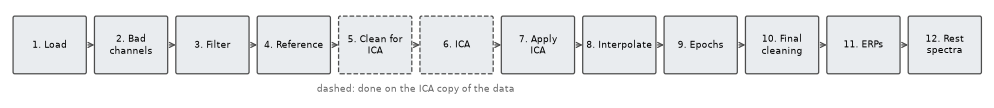

In [4]:
# ---- 0.4 Two helpers for the figures -----------------------------------------------------------------------------------------------
STEPS = ['Load', 'Bad\nchannels', 'Filter', 'Reference', 'Clean for\nICA', 'ICA', 'Apply\nICA',
         'Interpolate', 'Epochs', 'Final\ncleaning', 'ERPs', 'Rest\nspectra']


def pipeline_map(step):
    """Draws the 12 steps of the pipeline: the current step in orange, the steps already done in green."""
    fig, ax = plt.subplots(figsize=(14, 1.3))
    for i, label in enumerate(STEPS, start=1):
        color = '#f4a261' if i == step else '#b7e4c7' if i < step else '#e9ecef'
        ax.add_patch(FancyBboxPatch((i - 0.43, 0.3), 0.86, 0.6, boxstyle='round,pad=0.02', fc=color, ec='0.3',
                                    ls='--' if i in (5, 6) else '-'))
        ax.text(i, 0.6, f'{i}. {label}', ha='center', va='center', fontsize=7.5, weight='bold' if i == step else 'normal')
        if i < len(STEPS):
            ax.annotate('', xy=(i + 0.58, 0.6), xytext=(i + 0.44, 0.6), arrowprops=dict(arrowstyle='->', color='0.3'))
    ax.text(5.5, 0.08, 'dashed: done on the ICA copy of the data', ha='center', fontsize=7, color='0.4')
    ax.set(xlim=(0.5, len(STEPS) + 0.5), ylim=(0, 1))
    ax.axis('off')
    plt.show()


def plot_reject_log(log, channels, title, rebuilt_label='rebuilt'):
    """AutoReject's decisions: one row per channel, one column per piece or epoch."""
    rows = [log.ch_names.index(ch) for ch in channels]
    image = log.labels[:, rows].T.copy()                     # 0 good, 1 above threshold, 2 rebuilt
    image[:, log.bad_epochs] = 3                             # the whole piece or epoch is rejected
    colors = ['#b7e4c7', '#e63946', '#457b9d', '0.35']
    fig, ax = plt.subplots(figsize=(13, 3.6))
    ax.imshow(image, aspect='auto', interpolation='nearest', cmap=ListedColormap(colors), vmin=-0.5, vmax=3.5)
    ax.set(yticks=range(len(channels)), yticklabels=channels, xlabel='piece or epoch number', title=title)
    ax.tick_params(axis='y', labelsize=7)
    ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(colors, ['good', 'above its threshold', rebuilt_label, 'rejected'])],
              loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
    plt.show()


def show_animation(fig, anim, dpi=72):
    """Shows a matplotlib animation in the notebook, with play and pause buttons."""
    plt.close(fig)                                           # no extra still picture
    fig.set_dpi(dpi)                                         # small frames keep the notebook light
    with plt.rc_context({'animation.frame_format': 'jpeg'}):
        display(HTML(anim.to_jshtml(default_mode='once')))


pipeline_map(0)

## 1. Load and look at the data

**What.** Read the six seated recordings of the participant: the rest before the task, the 4 task blocks, the rest at the end.

**Why.** Before changing anything, look at the raw data. You need to know the problems before you fix them.

**The BIDS format.** The data follow BIDS, the Brain Imaging Data Structure (Pernet et al., 2019): a standard way to name and organize
files. The file name says what the file contains:

`sub-P012_ses-001_task-LexicalDecision_acq-seatedBlock01_run-01_eeg.vhdr`

= participant P012, session 1, task LexicalDecision, acquisition "seated block 1", run 1, EEG data. Each recording has six files:

| File | Contains |
|---|---|
| `_eeg.vhdr`, `_eeg.vmrk`, `_eeg.eeg` | the signal, in the BrainVision format (header, markers, data) |
| `_eeg.json` | a description of the recording (device, reference, sampling rate...) |
| `_channels.tsv` | one row per channel (name, type, status) |
| `_events.tsv` | one row per event (each word, each response) with its time and details |

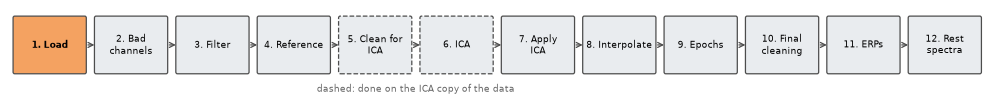

In [5]:
pipeline_map(1)

In [6]:
# ---- 1.1 The seated recordings of this participant (six for P012) ----------------------------------------------------------------
EEG_DIR = DATA_DIR / 'bids' / f'sub-{SUBJECT}' / 'ses-001' / 'eeg'
LABELS = {                                                   # our short name: the task and acquisition labels in the BIDS file name
    'rest_pre': 'task-RestingState_acq-seatedPre',
    'block1': 'task-LexicalDecision_acq-seatedBlock01',
    'block2': 'task-LexicalDecision_acq-seatedBlock02',
    'block3': 'task-LexicalDecision_acq-seatedBlock03',
    'block4': 'task-LexicalDecision_acq-seatedBlock04',
    'rest_post': 'task-RestingState_acq-seatedPost',
}


def bids_file(name, suffix):
    """The path of one BIDS file of a recording, for example bids_file('block1', 'events.tsv'), or None if it does not exist. The run
    number is usually 01; a recording restarted after a problem gets the next one, and we take the last."""
    return max(EEG_DIR.glob(f'sub-{SUBJECT}_ses-001_{LABELS[name]}_run-*_{suffix}'), default=None)


RECORDINGS = [name for name in LABELS if bids_file(name, 'eeg.vhdr')]   # the recordings this participant has
BLOCKS = [name for name in RECORDINGS if name.startswith('block')]
FIRST_BLOCK = BLOCKS[0]                                      # the block that the figures of steps 1 to 3 show
print('Missing for this participant:', ', '.join(name for name in LABELS if name not in RECORDINGS) or 'nothing')
print(f'The files of {FIRST_BLOCK}:')
for f in sorted(EEG_DIR.glob(f'*{LABELS[FIRST_BLOCK]}*')):
    print(f'  {f.name:80s} {f.stat().st_size / 1e6:6.2f} MB')

Missing for this participant: nothing
The files of block1:
  sub-P010_ses-001_task-LexicalDecision_acq-seatedBlock01_run-01_channels.tsv        0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-seatedBlock01_run-01_eeg.eeg             7.78 MB
  sub-P010_ses-001_task-LexicalDecision_acq-seatedBlock01_run-01_eeg.json            0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-seatedBlock01_run-01_eeg.vhdr            0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-seatedBlock01_run-01_eeg.vmrk            0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-seatedBlock01_run-01_events.tsv          0.04 MB


In [7]:
# ---- 1.2 What the dataset says about the recording and the channels ---------------------------------------------------------------
sidecar = json.loads(bids_file(FIRST_BLOCK, 'eeg.json').read_text(encoding='utf-8'))    # the _eeg.json file
print('Device:       ', sidecar['ManufacturersModelName'], '-', sidecar['CapManufacturersModelName'])
print('Sampling rate:', sidecar['SamplingFrequency'], 'Hz')
print('Reference:    ', sidecar['EEGReference'])
channels = pd.read_csv(bids_file(FIRST_BLOCK, 'channels.tsv'), sep='\t')                 # the _channels.tsv file
channels[['name', 'type', 'status', 'status_description', 'description']]

Device:        DSI-24 - DSI-24 dry-electrode headset
Sampling rate: 300.0 Hz
Reference:     Pz (online hardware reference). Every scalp channel is recorded as (channel - Pz); Pz is kept as an all-zero EEG channel so that an average reference over the EEG channels reconstructs it. A1/A2 (ear clips) and CM are typed MISC.


,name,type,status,status_description,description
0,P3,EEG,good,NaN,NaN
1,C3,EEG,good,NaN,NaN
2,F3,EEG,good,NaN,NaN
3,Fz,EEG,good,NaN,NaN
4,F4,EEG,good,NaN,NaN
5,C4,EEG,good,NaN,NaN
6,P4,EEG,good,NaN,NaN
7,Cz,EEG,good,NaN,NaN
8,CM,MISC,good,NaN,DSI common-mode sensor
9,A1,MISC,good,NaN,left ear clip


**Look.** 19 channels are EEG. Three are not: `A1` and `A2` (clips on the ear lobes) and `CM` (a sensor the amplifier uses to remove
noise common to all electrodes); `Trigger` receives the event signals. `Pz` is the **reference**: every channel was recorded as
(channel − Pz), so Pz itself is all zeros. The dataset already flags `P7` as flat. We will check all channels ourselves at step 2.

In [8]:
# ---- 1.3 Read the recordings --------------------------------------------------------------------------------------------------
raws, events = {}, {}
for name in RECORDINGS:
    raw = mne.io.read_raw_brainvision(bids_file(name, 'eeg.vhdr'), preload=True)   # the signal, in volts; preload: into memory
    raw.set_channel_types({'CM': 'misc', 'A1': 'misc', 'A2': 'misc', 'Trigger': 'stim'})   # only the 19 scalp channels are EEG
    raw.set_montage('standard_1020')                         # the position of each electrode on the head (10-20 system)
    raws[name] = raw
    events[name] = pd.read_csv(bids_file(name, 'events.tsv'), sep='\t', na_values='n/a')   # one row per event
    print(f'{name:10s} {raw.times[-1] / 60:4.1f} min, {raw.info["sfreq"]:.0f} Hz, '
          f'{(events[name]["trial_type"] == "stimulus").sum():3d} words')
raws[FIRST_BLOCK].info                                       # the description MNE keeps with the data

rest_pre    5.1 min, 300 Hz,   0 words
block1      4.7 min, 300 Hz, 100 words
block2      4.3 min, 300 Hz, 100 words
block3      4.2 min, 300 Hz,  96 words
block4      4.5 min, 300 Hz, 100 words
rest_post   5.2 min, 300 Hz,   0 words


<Info | 8 non-empty values
 bads: []
 ch_names: P3, C3, F3, Fz, F4, C4, P4, Cz, CM, A1, Fp1, Fp2, T7, P7, O1, ...
 chs: 19 EEG, 3 misc, 1 Stimulus
 custom_ref_applied: False
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.0 Hz
 lowpass: 150.0 Hz
 meas_date: unspecified
 nchan: 23
 projs: []
 sfreq: 300.0 Hz
>

**How.** `mne.io.read_raw_brainvision(path, preload=True)` reads a BrainVision file and returns a `Raw` object: the signal (channels ×
samples, in volts) and its description `raw.info` (channel names and types, sampling rate, bad channels...). `raw.set_channel_types`
tells MNE which channels are EEG, and `raw.set_montage` gives each electrode its position on the head, which topographic maps and
interpolation need.

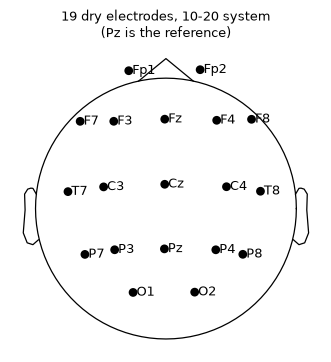

In [9]:
# ---- 1.4 Where the electrodes are -------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(4.5, 4.5))
raws[FIRST_BLOCK].plot_sensors(show_names=True, axes=ax, show=False)
ax.set_title('19 dry electrodes, 10-20 system\n(Pz is the reference)', fontsize=10)
plt.show()

**The 10-20 system.** The letter gives the region: Fp frontopolar, F frontal, C central, T temporal, P parietal, O occipital. Odd numbers are
on the left, even numbers on the right, and z is the midline. Seen from above, the nose is at the top.

In [10]:
# ---- 1.5 The events: one row per word and one per response ------------------------------------------------------------------------
columns = ['onset', 'trial_type', 'stimulus', 'lexicality', 'frequency_class', 'accuracy', 'response_time']
display(events[FIRST_BLOCK][columns].head(7))
words = pd.concat([events[b][events[b]['trial_type'] == 'stimulus'] for b in BLOCKS])   # the 400 words of the 4 blocks
behaviour = words.groupby('frequency_class').agg(trials=('stimulus', 'size'), accuracy=('accuracy', 'mean'),
                                                 median_rt_s=('response_time', 'median'))
behaviour.round(3)

,onset,trial_type,stimulus,lexicality,frequency_class,accuracy,response_time
0,3.833333,recording_start,NaN,NaN,NaN,NaN,NaN
1,5.911045,stimulus,gérant,word,high,1.0,1.1085
2,7.019545,response,NaN,NaN,NaN,1.0,1.1085
3,8.018409,stimulus,néant,word,low,1.0,0.7431
4,8.761509,response,NaN,NaN,NaN,1.0,0.7431
5,10.646364,stimulus,mobule,pseudoword,pseudoword,1.0,0.8732
6,11.519564,response,NaN,NaN,NaN,1.0,0.8732


,trials,accuracy,median_rt_s
frequency_class,,,
high,100,0.950,0.655
low,99,0.866,0.745
pseudoword,197,0.929,0.834


**Look.** `onset` is the time in the recording (s), `accuracy` is 1 for a correct answer, and `response_time` is the reaction time (s).
The behaviour already tells a story: frequent words are recognized faster than rare words, and both faster than pseudowords. Accuracy
is high in all three conditions.

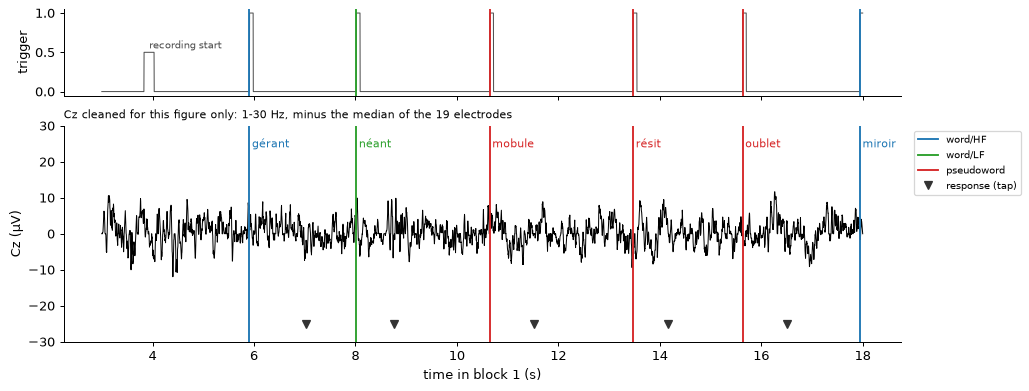

In [11]:
# ---- 1.6 One trial after another: the word onsets, the responses and the trigger channel --------------------------------------------
start, stop = 3, 18                                          # the seconds of the first block we show
piece = raws[FIRST_BLOCK].copy().crop(start, stop)
eeg = piece.copy().pick('eeg').filter(1, 30)                 # the 19 electrodes, filtered only to make the figure readable
# Cz in µV, minus the median electrode: removes the noise of Pz, the reference, which every channel carries
cz = (eeg.get_data(picks='Cz')[0] - np.median(eeg.get_data(), axis=0)) * 1e6
trigger = piece.get_data(picks='Trigger')[0]
ev = events[FIRST_BLOCK][(events[FIRST_BLOCK]['onset'] >= start) & (events[FIRST_BLOCK]['onset'] <= stop)]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.8), sharex=True, height_ratios=[1, 2.5])
ax1.plot(piece.times + start, trigger / trigger.max(), color='0.3', lw=0.8)
ax2.plot(piece.times + start, cz, color='k', lw=0.8)
for _, row in ev.iterrows():
    if row['trial_type'] == 'stimulus':
        kind = 'pseudoword' if row['lexicality'] == 'pseudoword' else 'word/HF' if row['frequency_class'] == 'high' else 'word/LF'
        for ax in (ax1, ax2):
            ax.axvline(row['onset'], color=CONDITIONS[kind], lw=1.5)
        ax2.text(row['onset'] + 0.05, 24, row['stimulus'], color=CONDITIONS[kind], fontsize=9)
    elif row['trial_type'] == 'response':
        ax2.plot(row['onset'], -25, 'v', color='0.2', ms=7)
    elif row['trial_type'] == 'recording_start':
        ax1.text(row['onset'] + 0.1, 0.55, 'recording start', fontsize=8, color='0.3')
ax1.set(ylabel='trigger')
ax2.set(xlabel=f'time in block {FIRST_BLOCK[-1]} (s)', ylabel='Cz (µV)', ylim=(-30, 30))
ax2.set_title('Cz cleaned for this figure only: 1-30 Hz, minus the median of the 19 electrodes', fontsize=9, loc='left')
for kind, color in CONDITIONS.items():
    ax2.plot([], [], color=color, label=kind)
ax2.plot([], [], 'v', color='0.2', label='response (tap)')
ax2.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
plt.show()


**Look.** Four things to see in these 15 seconds of the first block:

1. **The trigger channel (top).** The tablet played a short tone at each word into the trigger channel of the EEG, so each pulse is one
   tone. The first, smaller pulse marks the start of the recording.
2. **The coloured lines** are the word onsets, one colour per condition. An onset is the moment the tablet drew the word, converted to
   EEG time with the help of the tones, so each pulse starts within a few milliseconds of its line. This is how the EEG and the task
   are synchronized.
3. **The triangles** are the taps. The EEG has no trigger for them: each tap is placed at the word onset plus the reaction time
   measured by the tablet (0.7 to 1.1 s here, the `response_time` column of cell 1.5).
4. **Cz (bottom)** shows no obvious response to each word: an ERP is a few µV, much smaller than the ongoing EEG (about ±10 µV here),
   so we will need to average many trials (step 11). This Cz is cleaned for this figure only (1–30 Hz, minus the median of the 19
   electrodes, which removes the noise of the reference Pz that every channel carries). The raw signal is much noisier (cell 1.7).


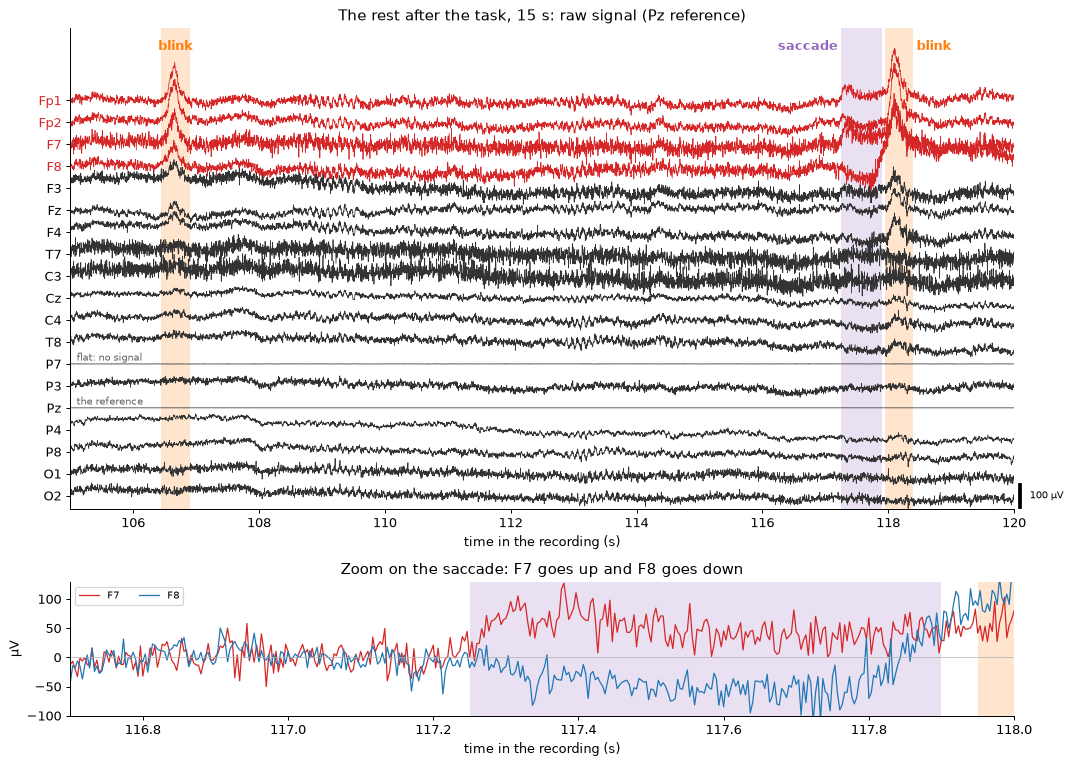

In [12]:
# ---- 1.7 The raw signal: what an eye blink and an eye movement look like (15 s of the rest after the task) ------------------------------
start, stop = 105, 120                                       # the seconds of the rest we show
eye = ['Fp1', 'Fp2', 'F7', 'F8']                             # the four electrodes closest to the eyes
order = eye + ['F3', 'Fz', 'F4', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2']   # the eyes first, then front to back
# the two blinks and the saccade of this piece (start, end, name, colour, side of the span where the name is written)
marks = [(106.45, 106.9, 'blink', 'tab:orange', 'center'),
         (117.25, 117.9, 'saccade', 'tab:purple', 'right'),
         (117.95, 118.4, 'blink', 'tab:orange', 'left')]
piece = raws['rest_post'].copy().pick('eeg').crop(start, stop)
times = piece.times + start
data = piece.get_data(picks=order) * 1e6                     # the raw signal (Pz reference) in µV
data -= data.mean(axis=1, keepdims=True)                     # each channel around its own mean, as raw.plot() does

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8.6), height_ratios=[4.3, 1.2])
gap = 100                                                    # µV between two channels
for k, (name, y) in enumerate(zip(order, data)):
    ax1.plot(times, y - k * gap, lw=0.6, color='tab:red' if name in eye else '0.2')
ax1.set(yticks=[-k * gap for k in range(len(order))], yticklabels=order, xlim=(start, stop), ylim=(-len(order) * gap + 40, 330),
        xlabel='time in the recording (s)', title='The rest after the task, 15 s: raw signal (Pz reference)')
for label in ax1.get_yticklabels():
    label.set_color('tab:red' if label.get_text() in eye else 'k')
for name, text in (('P7', 'flat: no signal'), ('Pz', 'the reference')):
    ax1.text(start + 0.1, -order.index(name) * gap + 15, text, fontsize=8, color='0.4')
ax1.plot([stop + 0.1] * 2, [-17.5 * gap, -18.5 * gap], color='k', lw=3, clip_on=False)      # the scale bar
ax1.text(stop + 0.25, -18 * gap, '100 µV', va='center', fontsize=8)

zoom = (times >= 116.7) & (times <= 118.0)                   # the saccade, enlarged: F7 and F8 only, from their level before it
before = (times >= 116.7) & (times <= 117.2)
for name, color in (('F7', 'tab:red'), ('F8', 'tab:blue')):
    y = data[order.index(name)]
    ax2.plot(times[zoom], (y - y[before].mean())[zoom], color=color, lw=1, label=name)
ax2.set(xlim=(116.7, 118.0), ylim=(-100, 130), xlabel='time in the recording (s)', ylabel='µV',
        title='Zoom on the saccade: F7 goes up and F8 goes down')
ax2.axhline(0, color='0.7', lw=0.6)
ax2.legend(loc='upper left', ncol=2, fontsize=8)

for t0, t1, label, color, side in marks:
    for ax in (ax1, ax2):
        ax.axvspan(t0, t1, color=color, alpha=0.2, lw=0)
    x = {'center': (t0 + t1) / 2, 'right': t0 - 0.05, 'left': t1 + 0.05}[side]
    ax1.text(x, 0.975, label, color=color, ha=side, va='top', weight='bold', transform=ax1.get_xaxis_transform())
plt.tight_layout()
plt.show()


**Look.** This is the raw signal (no filter, Pz reference) of 15 seconds of the rest after the task, from the front of the head to the back.
The four electrodes closest to the eyes (Fp1, Fp2, F7, F8) are in red. The participant blinked twice (orange) and made one clear eye
movement (purple):

1. **Eye blink** (106.7 s and 118.1 s). A sharp wave of about 0.4 s, at the same time on Fp1, Fp2, F7 and F8, 100 to 350 µV high. It is
   smaller on F3, Fz and F4, only about 25 µV at Cz, and small at the back. The eye is electrically charged, and when the eyelid moves it
   changes the voltage at the front of the head.
2. **Eye movement, or saccade** (117.3 s). The eyes jump sideways, here to the left, towards F7. F7 goes **up** and F8 goes **down** by
   about 50 µV (zoom below): the two electrodes move in opposite directions, and they stay there as long as the eyes do (about 0.5 s here).
   In a blink, all the frontal electrodes go up together. A second blink follows right after (118.1 s).
3. **P7** is a flat line: the electrode did not record.
4. **Pz** is flat on purpose: it is the reference.

These artifacts are much larger than the brain signals we want (an ERP is a few µV). Step 6 finds them with ICA (one component for the
blinks, one for the eye movements) and step 7 removes them.

To scroll through a recording yourself, run `raws['rest_post'].plot()` on your own computer with an interactive backend (`%matplotlib
qt` or `%matplotlib widget`).


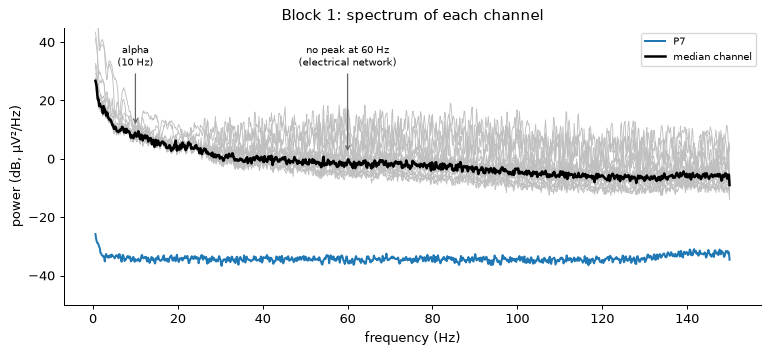

In [13]:
# ---- 1.8 The raw spectrum: how much power the signal has at each frequency -----------------------------------------------------------
eeg_names = [ch for ch in raws[FIRST_BLOCK].copy().pick('eeg').ch_names if ch != 'Pz']   # Pz is all zeros: no spectrum
spectrum = raws[FIRST_BLOCK].compute_psd(method='welch', picks=eeg_names, fmin=0.5, fmax=150)   # power spectral density
power_db = 10 * np.log10(spectrum.get_data() * 1e12)                     # V²/Hz -> µV²/Hz, in decibels
fig, ax = plt.subplots(figsize=(10, 4))
for ch, p in zip(eeg_names, power_db):
    style = dict(color='tab:blue', lw=1.6, label='P7') if ch == 'P7' else dict(color='0.75', lw=0.7)
    ax.plot(spectrum.freqs, p, **style)
ax.plot(spectrum.freqs, np.median(power_db, axis=0), color='k', lw=2, label='median channel')
for f, text in [(10, 'alpha\n(10 Hz)'), (60, 'no peak at 60 Hz\n(electrical network)')]:
    ax.annotate(text, xy=(f, np.median(power_db, axis=0)[np.argmin(abs(spectrum.freqs - f))] + 2), xytext=(f, 32),
                ha='center', fontsize=8, arrowprops=dict(arrowstyle='->', color='0.4'))
ax.set(xlabel='frequency (Hz)', ylabel='power (dB, µV²/Hz)', title=f'Block {FIRST_BLOCK[-1]}: spectrum of each channel', ylim=(-50, 45))
ax.legend(fontsize=8)
plt.show()

**Look.** The spectrum decomposes the signal into frequencies (Hz = cycles per second). EEG power falls as frequency rises. On top of
that you can see a small bump around **10 Hz** (the alpha rhythm, a brain signal) and **P7** far below the others (flat).

Notice also what is **not** there: a sharp peak at **60 Hz**, the frequency of the electrical network in North America. Most EEG
recordings have one, and its harmonic at 120 Hz. In these recordings it is no larger than the noise around it (a few dB at most). We still
apply a notch filter at step 3: it costs almost nothing, and it protects other recordings.

### 1.9 Keep what we analyze, label the words, join the four blocks

- **Rest**: keep the part between the start and end tones of the rest.
- **Task**: turn each word into an **annotation**, a label at a time in the recording. The label is the condition: `word/HF`, `word/LF`
  or `pseudoword`; the `/` lets us later select all words at once with `epochs['word']`. When the wireless link of the headset lost samples
  (`data_gap` in the events), we mark 2 s around it as `BAD_gap`: MNE ignores segments whose annotation starts with `BAD`.
- Then **join** the four blocks into one task recording with `mne.concatenate_raws`. MNE marks each junction with a `BAD boundary`
  annotation (no epoch may cross it) and an `EDGE boundary` (filters treat each block separately).

In [14]:
# ---- 1.9 Keep the rest periods, label the words and join the blocks -------------------------------------------------------------
def condition_of(row):
    """word/HF, word/LF or pseudoword, from one row of an events.tsv file."""
    if row['lexicality'] == 'pseudoword':
        return 'pseudoword'
    return 'word/HF' if row['frequency_class'] == 'high' else 'word/LF'


def label_words(raw, ev):
    """A copy of raw whose annotations are the word onsets (named by condition) and the data gaps (BAD)."""
    raw = raw.copy()
    sfreq = raw.info['sfreq']
    stim = ev[ev['trial_type'] == 'stimulus']
    annotations = mne.Annotations(onset=stim['sample'] / sfreq, duration=0.0, description=list(stim.apply(condition_of, axis=1)))
    gaps = ev.loc[ev['trial_type'] == 'data_gap', 'sample'] / sfreq     # where the wireless link lost samples
    if len(gaps):
        annotations += mne.Annotations(onset=np.maximum(gaps - 1, 0), duration=2.0, description='BAD_gap')
    raw.set_annotations(annotations)
    return raw


def rest_period(raw, ev):
    """A copy of raw cut between the start and end tones of the rest (or the start and end of the file, when a tone is missing)."""
    start = ev.loc[ev['trial_type'] == 'rest_start', 'onset']
    begin = start.iloc[0] if len(start) else 0.0
    end = ev.loc[ev['trial_type'] == 'rest_end', 'onset']
    end = min(end.iloc[0], raw.times[-1]) if len(end) else raw.times[-1]
    return raw.copy().set_annotations(None).crop(begin, end)


recordings = {}                                              # the rest before, the task (the blocks joined), the rest after
if 'rest_pre' in raws:
    recordings['rest_pre'] = rest_period(raws['rest_pre'], events['rest_pre'])
recordings['task'] = mne.concatenate_raws([label_words(raws[b], events[b]) for b in BLOCKS])
if 'rest_post' in raws:
    recordings['rest_post'] = rest_period(raws['rest_post'], events['rest_post'])
trials = pd.concat([events[b][events[b]['trial_type'] == 'stimulus'] for b in BLOCKS], ignore_index=True)   # one row per word
trials['condition'] = trials.apply(condition_of, axis=1)
for name, raw in recordings.items():
    labels = pd.Series(raw.annotations.description).value_counts().to_dict()
    print(f'{name:10s} {raw.times[-1] / 60:5.1f} min   annotations: {labels if labels else "none"}')

rest_pre     5.0 min   annotations: none
task        17.7 min   annotations: {'pseudoword': 197, 'word/HF': 100, 'word/LF': 99, 'BAD boundary': 3, 'EDGE boundary': 3, 'BAD_gap': 2}
rest_post    5.0 min   annotations: none


## 2. Find the bad channels

**What.** Find the electrodes whose signal is not EEG: **flat** (no contact, broken electrode) or **noisy** (much larger than the others:
poor contact, an electrode that moves). Dry electrodes have more of these problems than gel electrodes. In three studies, 5.3 faulty
electrodes had to be interpolated on average with dry electrodes against 2.0 with gel (Kam et al., 2019), 16 % of the channels were bad
against 3 % (Fiedler et al., 2022), and 10.5 % of the data was rejected against 3.9 % (Heijs et al., 2021).

**Why now.** A bad channel spreads to every channel when we re-reference to the average (step 4) and it disturbs ICA (step 6). We mark
the bad channels now (`raw.info['bads']`): MNE then leaves them out of steps 3 to 7, and step 8 rebuilds them from their neighbours.

**How.** For each channel, measure its typical amplitude and compare it with the median channel of the same recording. Which measure of
amplitude? The usual one, the standard deviation, is fooled by blinks: they are rare but huge, and they make the frontal channels look
noisy. A **robust** measure, the median absolute deviation (MAD), ignores rare large events. The order of the checks matters too. Flat
channels are looked for on the signal as it was recorded. Noisy channels are looked for after we subtract what all the channels share,
the noise of the reference Pz. PREP, a standard pipeline for this step, works in the same order (Bigdely-Shamlo et al., 2015).

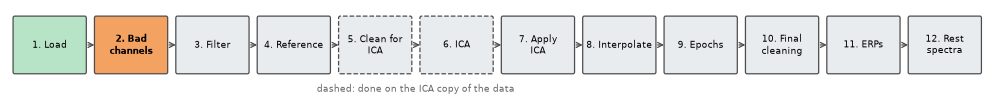

In [15]:
pipeline_map(2)

### Before we measure

Published pipelines prepare the data before they look for bad channels. We do the same.

1. **Leave out what is not scalp EEG.** `A1`, `A2`, `CM` and `Trigger` are not EEG: we gave them other types when we loaded the data
   (cell 1.3), and the function below uses the EEG channels only. BeMoBIL, a pipeline made for EEG recorded while people move, does the
   same with its EOG channels, because their statistics "will often lead to false positive detection" (Klug et al., 2022).
2. **Measure on a copy filtered at 1–40 Hz.** Below 1 Hz, slow drifts (sweat, an electrode that moves) would dominate the amplitude of a
   channel, and above 40 Hz the 60 Hz of the electrical network would add to it. The recording itself stays unfiltered. PREP also removes
   the slow trends before it looks for bad channels (documentation of PyPREP, the Python version of PREP), and it computes its
   correlation criterion on a signal low-passed at 50 Hz (Bigdely-Shamlo et al., 2015).
3. **Look for flat channels before changing the reference.** PyPREP starts with a pass that finds the channels that are NaN, flat or have
   a very low signal, and only then re-references (PyPREP documentation). After a reference is subtracted, such a channel "will
   essentially contain the channel mean" and no longer looks low (Bigdely-Shamlo et al., 2015).
4. **Remove what all the channels share before looking for noisy ones.** The DSI-24 records every channel as the electrode minus Pz
   (Wearable Sensing, 2023), so the noise of Pz is in all of them. PREP computes its criteria after referencing to a robust estimate of
   the average, by default the median of the channels (Bigdely-Shamlo et al., 2015). We subtract the same median (cell 2.2).
5. **Measure the recordings whole.** BeMoBIL recommends removing the segments before and after the experiment and the breaks as a very
   first step, because they can contain very strong artifacts that affect channel rejection and ICA (Klug et al., 2022). We keep each of
   the six recordings whole, including the last seconds after the end of the task (the dark patch at the end of block 1 in cell 2.4) and
   the pieces where the wireless link lost samples (marked in cell 1.9): they are a small part of the data, and the robust amplitude
   ignores rare events. BeMoBIL also advises to switch its flatline criterion off for mobile recordings, because data may be lost
   without the whole channel being unusable (Klug et al., 2022).

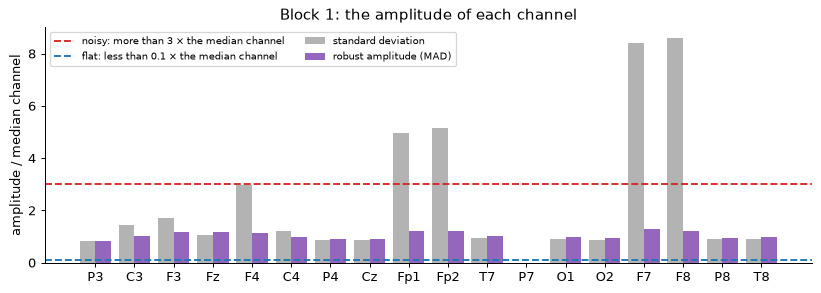

In [16]:
# ---- 2.1 Standard deviation or robust amplitude? ------------------------------------------------------------------------------------
def amplitudes(raw, median_reference=False):
    """Standard deviation and robust amplitude (1.4826 x MAD) of each EEG channel (µV), on a 1-40 Hz copy.
    With median_reference=True, the median of the channels that are not flat is first subtracted at each sample (cell 2.2)."""
    eeg = raw.copy().pick('eeg')
    x = eeg.filter(1, 40).get_data() * 1e6                    # 1-40 Hz: ignore the slow drifts and the 60 Hz noise
    if median_reference:
        live = x.std(axis=1) > FLAT_SD_UV                      # the channels that are not flat (Pz, always 0, and P7 are)
        x = x - np.median(x[live], axis=0)                     # what all the channels have in common: mostly the noise of Pz
    sd = x.std(axis=1)
    mad = 1.4826 * np.median(np.abs(x - np.median(x, axis=1, keepdims=True)), axis=1)   # equals the SD for Gaussian noise
    return pd.DataFrame({'sd': sd, 'robust': mad}, index=eeg.ch_names).drop(index='Pz')   # Pz is the reference: always 0


ratio1 = amplitudes(raws[FIRST_BLOCK])
ratio1 = ratio1 / ratio1.median()                            # each channel compared with the median channel
fig, ax = plt.subplots(figsize=(11, 3.4))
x = np.arange(len(ratio1))
ax.bar(x - 0.2, ratio1['sd'], 0.4, color='0.7', label='standard deviation')
ax.bar(x + 0.2, ratio1['robust'], 0.4, color='tab:purple', label='robust amplitude (MAD)')
ax.axhline(NOISY_RATIO, color='tab:red', ls='--', label=f'noisy: more than {NOISY_RATIO:g} × the median channel')
ax.axhline(FLAT_RATIO, color='tab:blue', ls='--', label=f'flat: less than {FLAT_RATIO:g} × the median channel')
ax.set(xticks=x, xticklabels=ratio1.index, ylabel='amplitude / median channel', title=f'Block {FIRST_BLOCK[-1]}: the amplitude of each channel')
ax.legend(fontsize=8, ncol=2)
plt.show()

**Look.** With the standard deviation (grey), Fp1, Fp2, F7 and F8 go above the "noisy" line, 5 to 9 times the median channel (F4 is just
under it), only because of the blinks and the eye movements: they are rare but huge. With the robust amplitude (purple), all these
channels are normal (at most 1.3 times the median channel), and only **P7** stands out, far below the flat line. The mean and the
standard deviation are moved by the very values they are meant to detect; the median and the MAD are not (Leys et al., 2013). PREP's
noisy-channel criterion is robust for the same reason: it "does not identify channels that capture eye-blinks and most muscle activity
as noisy" (Bigdely-Shamlo et al., 2015). Leys et al. recommend flagging the values beyond the median ± 2.5 MAD; we compare each channel
with the median channel instead.

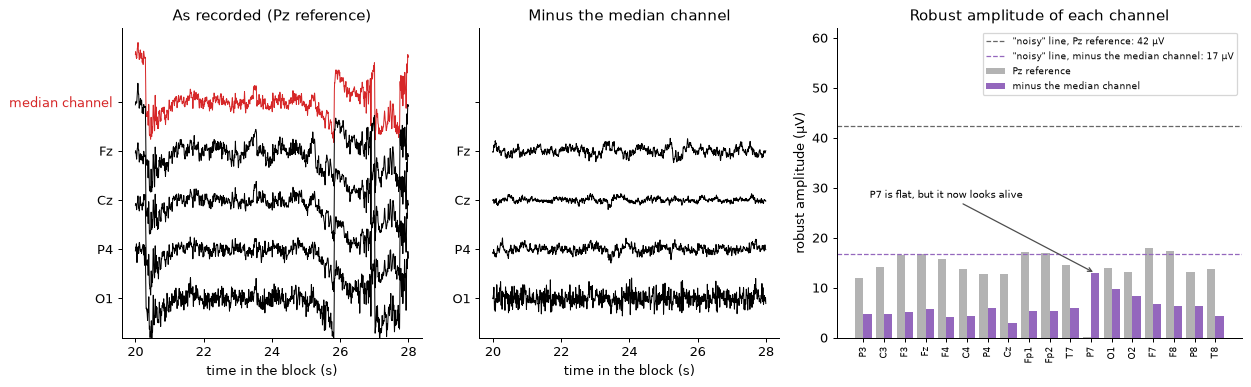

A typical channel: 14.1 µV with the Pz reference, 5.6 µV after subtracting the median channel.
The median channel itself: 12.9 µV, that is 84 % of the variance of a typical channel.
The "noisy" line (3 × the typical channel): 42 µV with the Pz reference, 17 µV after.


In [17]:
# ---- 2.2 The noise of Pz is in every channel ----------------------------------------------------------------------------------------
eeg_1 = raws[FIRST_BLOCK].copy().pick('eeg').filter(1, 40)
names = [ch for ch in eeg_1.ch_names if ch != 'Pz']                     # Pz is the reference: always 0
x = eeg_1.get_data(picks=names) * 1e6                                   # every channel minus Pz, in µV
live = x.std(axis=1) > FLAT_SD_UV                                       # the channels that are not flat (P7 is)
common = np.median(x[live], axis=0)                                     # at each sample, the median of the live channels
y = x - common                                                          # every channel minus the median channel

start, length, gap = 20, 8, 80                                          # the seconds of the first block we show; µV between two traces
piece = slice(int(start * eeg_1.info['sfreq']), int((start + length) * eeg_1.info['sfreq']))
shown = ['Fz', 'Cz', 'P4', 'O1']
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.4), width_ratios=[1, 1, 1.35])
for ax, data, title in ((ax1, x, 'As recorded (Pz reference)'), (ax2, y, 'Minus the median channel')):
    if data is x:
        ax.plot(eeg_1.times[piece], common[piece], color='tab:red', lw=0.8)                  # the median channel: what the channels share
    for k, ch in enumerate(shown, start=1):
        ax.plot(eeg_1.times[piece], data[names.index(ch)][piece] - k * gap, color='k', lw=0.8)
    ax.set(yticks=[-k * gap for k in range(len(shown) + 1)], yticklabels=['median channel' if data is x else ''] + shown,
           ylim=(-(len(shown) + 0.8) * gap, 1.5 * gap), xlabel='time in the block (s)', title=title)
ax1.get_yticklabels()[0].set_color('tab:red')

pz_amp = amplitudes(raws[FIRST_BLOCK])['robust']                        # robust amplitude of each channel, Pz reference
med_amp = amplitudes(raws[FIRST_BLOCK], median_reference=True)['robust']   # and after subtracting the median channel
bars = np.arange(len(pz_amp))
ax3.bar(bars - 0.2, pz_amp, 0.4, color='0.7', label='Pz reference')
ax3.bar(bars + 0.2, med_amp, 0.4, color='tab:purple', label='minus the median channel')
for amp, color, text in ((pz_amp, '0.4', 'Pz reference'), (med_amp, 'tab:purple', 'minus the median channel')):
    ax3.axhline(NOISY_RATIO * amp.median(), color=color, ls='--', lw=1,                  # the "noisy" line: 3 × the median channel
                label=f'"noisy" line, {text}: {NOISY_RATIO * amp.median():.0f} µV')
ax3.annotate('P7 is flat, but it now looks alive', xy=(list(pz_amp.index).index('P7') + 0.2, med_amp['P7']), xytext=(0.3, 28),
             fontsize=8, arrowprops=dict(arrowstyle='->', color='0.3'))
ax3.set(xticks=bars, xticklabels=pz_amp.index, ylabel='robust amplitude (µV)', title='Robust amplitude of each channel', ylim=(0, 62))
ax3.tick_params(axis='x', labelsize=7, rotation=90)
ax3.legend(fontsize=7.5, loc='upper right')
plt.tight_layout()
plt.show()

shared = 1.4826 * np.median(np.abs(common - np.median(common)))        # the robust amplitude of the median channel itself
print(f'A typical channel: {pz_amp.median():.1f} µV with the Pz reference, {med_amp.median():.1f} µV after subtracting the median channel.')
print(f'The median channel itself: {shared:.1f} µV, that is {100 * (shared / pz_amp.median()) ** 2:.0f} % of the variance of a typical channel.')
print(f'The "noisy" line ({NOISY_RATIO:g} × the typical channel): {NOISY_RATIO * pz_amp.median():.0f} µV with the Pz reference, '
      f'{NOISY_RATIO * med_amp.median():.0f} µV after.')

**Look.** With the Pz reference (left), the channels rise and fall together: what they share is the noise of Pz, the red median channel.
The headset records every channel as the electrode minus Pz, so whatever happens at Pz is in all of them (Wearable Sensing, 2023). After
we subtract the median channel (middle), they no longer move together. On the right, a typical channel falls from 14 to about 6 µV, and the
median channel carries more than 80 % of the variance of a typical channel in this block. The "noisy" line, 3 times the typical channel,
falls from 42 to 17 µV: a channel needs much less noise of its own to be noticed.

This is why PREP looks for bad channels after a robust re-reference. The median is not moved by one or two bad channels, so we can use it
before we know which channels are bad (Bigdely-Shamlo et al., 2015). Two limits. A flat channel looks alive after the subtraction (P7 on
the right: it now contains minus the median channel), so the flat channels must be found first, on the recorded signal. And this median
is only a first estimate: step 4 re-references to the average of the good channels.

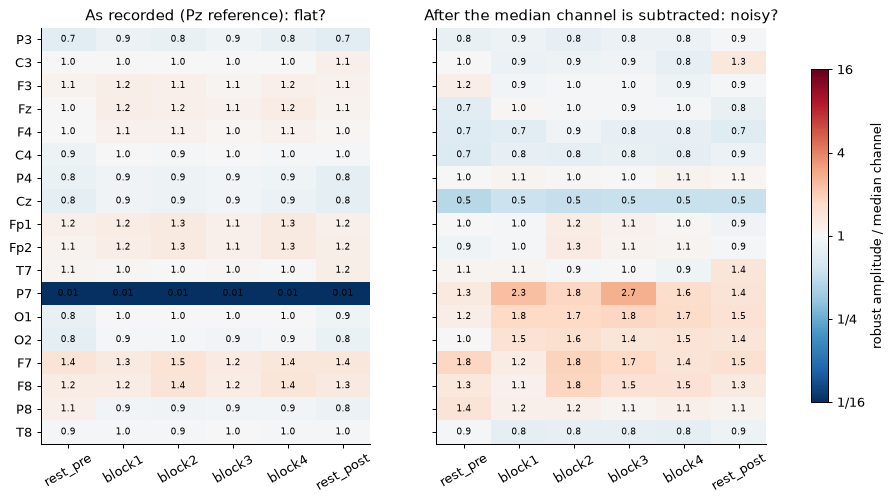

P7: flat (ratio as low as 0.01, SD as low as 0.13 µV, on the recorded signal)
Report: flat = ratio below 0.1 or SD below 1 µV on the recorded signal; noisy = ratio above 3 after the median reference; a channel bad in any of the 6 recordings is bad in all. Bad channels: ['P7'] (1 of 18), rebuilt at step 8 with spherical splines.


In [18]:
# ---- 2.3 Every channel in every recording: flat on the recorded signal, noisy after the median reference ----------------------------
recorded = {name: amplitudes(raw) for name, raw in raws.items()}                            # the signal as recorded (Pz reference)
after = {name: amplitudes(raw, median_reference=True) for name, raw in raws.items()}       # after subtracting the median channel
ratio_pz = pd.DataFrame({name: a['robust'] for name, a in recorded.items()})
ratio_pz = ratio_pz / ratio_pz.median()                      # each recording compared with its own median channel
ratio = pd.DataFrame({name: a['robust'] for name, a in after.items()})
ratio = ratio / ratio.median()
sd = pd.DataFrame({name: a['sd'] for name, a in recorded.items()})
flat = ((ratio_pz < FLAT_RATIO) | (sd < FLAT_SD_UV)).any(axis=1)        # flat in at least one recording, on the recorded signal
noisy = (ratio > NOISY_RATIO).any(axis=1) & ~flat                       # noisy in at least one recording, after the median reference
BAD_CHANNELS = sorted(ratio.index[flat | noisy])

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, table, title in ((axes[0], ratio_pz, 'As recorded (Pz reference): flat?'), (axes[1], ratio, 'After the median channel is subtracted: noisy?')):
    im = ax.imshow(np.log2(table.to_numpy()), cmap='RdBu_r', vmin=-4, vmax=4, aspect='auto')
    for (i, j), v in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, f'{v:.2f}' if v < 0.1 else f'{v:.1f}', ha='center', va='center', fontsize=7)
    ax.set(xticks=range(table.shape[1]), xticklabels=table.columns, yticks=range(table.shape[0]), yticklabels=table.index, title=title)
    ax.tick_params(axis='x', rotation=30)
cbar = fig.colorbar(im, ax=axes, ticks=[-4, -2, 0, 2, 4], shrink=0.8)
cbar.ax.set_yticklabels(['1/16', '1/4', '1', '4', '16'])
cbar.set_label('robust amplitude / median channel')
plt.show()

for ch in BAD_CHANNELS:
    if flat[ch]:
        print(f'{ch}: flat (ratio as low as {ratio_pz.loc[ch].min():.2f}, SD as low as {sd.loc[ch].min():.2f} µV, on the recorded signal)')
    else:
        print(f'{ch}: noisy (ratio up to {ratio.loc[ch].max():.1f} after the median reference)')
for raw in recordings.values():
    raw.info['bads'] = list(BAD_CHANNELS)                    # MNE now leaves these channels out of most steps
print(f'Report: flat = ratio below {FLAT_RATIO:g} or SD below {FLAT_SD_UV:g} µV on the recorded signal; noisy = ratio above {NOISY_RATIO:g} after the '
      f'median reference; a channel bad in any of the {len(raws)} recordings is bad in all. Bad channels: {BAD_CHANNELS} '
      f'({len(BAD_CHANNELS)} of {len(ratio)}), rebuilt at step 8 with spherical splines.')
if len(BAD_CHANNELS) > MAX_BAD:
    print(f'WARNING: more than {MAX_BAD} bad channels (about one fifth of the 18 recorded). Look at the recordings before going on.')

**Look.** Left: the ratio on the signal as recorded. P7 is at 0.01 in every recording, far below the flat line (1/10): it recorded nothing (it
was flat in every participant of the study: a hardware problem). Right: the ratio after the median channel is subtracted. No channel is
above the noisy line in any recording, and P7 looks alive (1.3 to 2.7): the subtraction put the shared noise into a channel that records
nothing. This is why the flat channels are looked for on the left.

The ratios of the good channels are not all equal to 1 on the right: they go from 0.5 to 1.8. Cz, the electrode closest to Pz, is the
lowest. Against one reference, the electrodes close to the reference have smaller amplitudes than the distant ones (Fló et al., 2022).
The thresholds (1/10 and 3) leave room for this spread.

The flat rule has two parts. The relative one (below 1/10 of the median channel) is ours. The absolute one, a standard deviation below
1 µV, is the rule of the channels table of cell 1.2 ("flat: SD below 1 uV over the recording") and the rule that NEAR, a pipeline for
newborn EEG, uses to find flat or weakly responsive channels (Kumaravel et al., 2022b).

A channel bad in one recording is treated as bad in all of them, so that every recording has the same good channels (one ICA for all, step
6). Studies with several conditions pool them in the same way: BeMoBIL merges all the blocks before it looks for bad channels (Klug et al.,
2022), and Oliveira et al. (2017) removed a channel selected in one walking condition from the other walking condition too. The "3 times
the median" rule has a close relative in walking data: Gonsisko et al. (2023) removed the channels whose standard deviation was more
than 3 times the median, re-referenced, and repeated it once.

How many bad channels are too many? BeMoBIL limits the fraction of channels that can be removed (for example one fifth), so that it does
not remove more channels than it can reconstruct (Klug et al., 2022). PREP flags a recording when more than 25 % of the channels had to
be interpolated during robust referencing (Bigdely-Shamlo et al., 2015). One fifth of the 18 channels we record (19 EEG channels minus
Pz) is 3.6, so we use `MAX_BAD = 3`: with more bad channels, we set the recording aside and look at it.

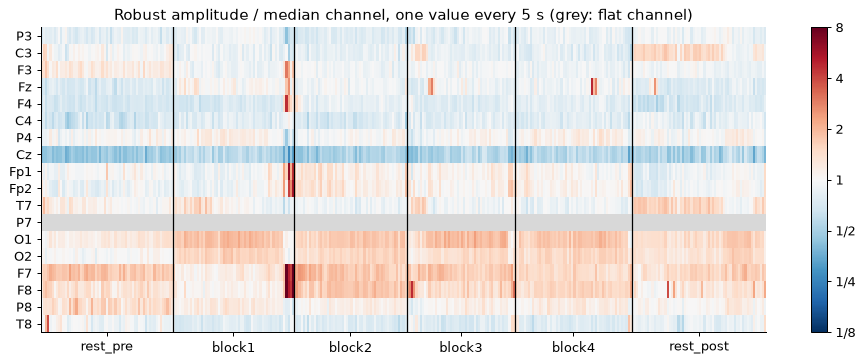

In [19]:
# ---- 2.4 When did a channel go bad? One value every 5 seconds -----------------------------------------------------------------------
WINDOW_S = 5                                                 # seconds in each column of the figure
columns = []
for name, raw in raws.items():
    eeg_w = raw.copy().pick('eeg').filter(1, 40)
    w = eeg_w.get_data() * 1e6
    live = w.std(axis=1) > FLAT_SD_UV
    w = w - np.median(w[live], axis=0)                       # minus the median channel, as in cell 2.3
    w = np.delete(w, eeg_w.ch_names.index('Pz'), axis=0)     # Pz is the reference: always 0
    n = int(WINDOW_S * eeg_w.info['sfreq'])
    pieces = [w[:, k:k + n] for k in range(0, w.shape[1] - n + 1, n)]
    mad = np.array([1.4826 * np.median(np.abs(p - np.median(p, axis=1, keepdims=True)), axis=1) for p in pieces]).T   # channels × windows
    columns.append(mad / np.median(mad, axis=0))             # in each window, each channel compared with the median channel
starts = np.cumsum([0] + [c.shape[1] for c in columns])
ratio_time = pd.DataFrame(np.hstack(columns), index=ratio.index)
ratio_time.loc[flat.index[flat]] = np.nan                    # the flat channels of cell 2.3 are drawn in grey

cmap = plt.get_cmap('RdBu_r').copy()
cmap.set_bad('0.85')
fig, ax = plt.subplots(figsize=(13, 4.4))
im = ax.imshow(np.log2(ratio_time.to_numpy()), cmap=cmap, vmin=-3, vmax=3, aspect='auto', interpolation='nearest')
for s in starts[1:-1]:
    ax.axvline(s - 0.5, color='k', lw=1)
ax.set(yticks=range(len(ratio_time)), yticklabels=ratio_time.index, xticks=(starts[:-1] + starts[1:]) / 2 - 0.5, xticklabels=list(raws),
       title=f'Robust amplitude / median channel, one value every {WINDOW_S} s (grey: flat channel)')
cbar = fig.colorbar(im, ax=ax, ticks=[-3, -2, -1, 0, 1, 2, 3])
cbar.ax.set_yticklabels(['1/8', '1/4', '1/2', '1', '2', '4', '8'])
plt.show()

**Look.** Each column is 5 seconds and each row a channel. Red means louder than the median channel at that moment, blue quieter. A channel
that lost contact for a while would appear as a red band, and one that was never in contact as a row that stays red or blue. P7 is grey: it
is flat the whole time. No other channel has a long band: the red patches are short and move from one channel to another, as blinks and
muscle bursts do. The darkest patch, at the end of block 1, is on the channels around the eyes and the temples (Fp1, Fp2, F7, F8). It is
after the end of the task: the task stopped at 257 s and the file goes on until 282 s. Cz stays blue: it is the electrode closest to Pz
(see cell 2.3). Published pipelines judge short windows (1 s in PREP, 5 s in BeMoBIL) and remove a channel only when it is abnormal in
more than a given fraction of the windows (Bigdely-Shamlo et al., 2015; Klug et al., 2022). We use one number per recording, and this
figure shows what that number hides.

In [20]:
# ---- 2.5 Why not the correlation with the other channels? PREP's rule on this participant -------------------------------------------
def prep_correlation(raw, median_reference):
    """PREP's correlation criterion on a 1-50 Hz copy: in each 1-s window, the 98th percentile of the absolute correlations of a channel with
    the other channels. A channel is bad if this value is below 0.4 in more than 1 % of the windows. Returns the typical value and the bad channels."""
    eeg_c = raw.copy().pick('eeg').filter(1, 50)
    c_data = eeg_c.get_data() * 1e6
    live = c_data.std(axis=1) > FLAT_SD_UV                   # Pz and the flat channels are not partners
    if median_reference:
        c_data = c_data - np.median(c_data[live], axis=0)
    c_data = c_data[live]
    c_names = [ch for ch, keep in zip(eeg_c.ch_names, live) if keep]
    n = int(eeg_c.info['sfreq'])                             # 1-s windows
    best = []
    for k in range(0, c_data.shape[1] - n + 1, n):
        c = np.abs(np.corrcoef(c_data[:, k:k + n]))
        np.fill_diagonal(c, np.nan)
        best.append(np.nanpercentile(c, 98, axis=1))
    best = np.array(best).T                                  # channels × windows
    return np.median(best), [ch for ch, row in zip(c_names, best) if (row < 0.4).mean() > 0.01]


rows = []
for name, raw in raws.items():
    r_pz, bad_pz = prep_correlation(raw, median_reference=False)
    r_med, bad_med = prep_correlation(raw, median_reference=True)
    rows.append((name, round(r_pz, 2), len(bad_pz), round(r_med, 2), len(bad_med)))
pd.DataFrame(rows, columns=['recording', 'typical correlation, Pz reference', 'channels flagged, Pz reference',
                            'typical correlation, minus median', 'channels flagged, minus median']).set_index('recording')

,"typical correlation, Pz reference","channels flagged, Pz reference","typical correlation, minus median","channels flagged, minus median"
recording,,,,
rest_pre,0.81,1,0.52,15
block1,0.92,1,0.57,11
block2,0.86,1,0.53,12
block3,0.93,0,0.54,13
block4,0.87,1,0.55,13
rest_post,0.81,3,0.54,11


**Look.** PREP also flags the channels that do not correlate with any other channel (Bigdely-Shamlo et al., 2015). With the Pz reference, every
channel correlates strongly with another one (typical value 0.8 to 0.9), because they all share the noise of Pz: PREP itself notes
that with a large common noise component this value is very close to 1. The rule flags 0 to 3 of the 17 channels. After we subtract the
median channel, the shared noise is gone, and 17 dry electrodes, far from each other on the head, correlate only weakly (typical value
0.5 to 0.6): the rule now flags 11 to 15 of 17 channels, in every recording. A rule whose verdict depends this much on the reference is not
one we can trust here. It was also made for caps with many more electrodes: its authors advise caution when the electrodes do not
cover the head well (Bigdely-Shamlo et al., 2015), and the authors of the LOF method, another way to find bad channels from their
neighbours, recommend not to use it below 32 channels (Kumaravel et al., 2022a). So we use the amplitude only.

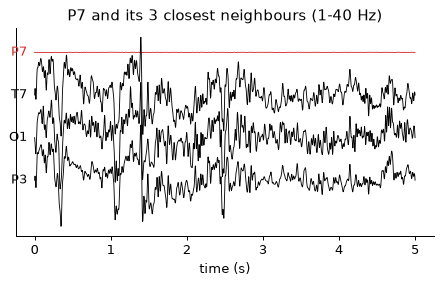

In [21]:
# ---- 2.6 What the bad channels look like next to their neighbours -------------------------------------------------------------------
positions = raws[FIRST_BLOCK].get_montage().get_positions()['ch_pos']
good = [ch for ch in ratio.index if ch not in BAD_CHANNELS]
piece = raws[FIRST_BLOCK].copy().crop(60, 65).filter(1, 40)
fig, axes = plt.subplots(1, len(BAD_CHANNELS), figsize=(6 * len(BAD_CHANNELS), 3), squeeze=False)
for ax, ch in zip(axes[0], BAD_CHANNELS):
    neighbours = sorted(good, key=lambda c: np.linalg.norm(positions[c] - positions[ch]))[:3]   # the 3 closest good electrodes
    for k, name in enumerate([ch] + neighbours):
        ax.plot(piece.times, piece.get_data(picks=name)[0] * 1e6 - 60 * k, color='tab:red' if name == ch else 'k', lw=0.7)
        ax.text(-0.1, -60 * k, name, ha='right', va='center', color='tab:red' if name == ch else 'k')
    ax.set(xlabel='time (s)', yticks=[], title=f'{ch} and its 3 closest neighbours (1-40 Hz)')
plt.show()

**What the headset tells you.** Before a recording, the manual of the DSI-24 asks to check three numbers for each sensor: an impedance below
1 MΩ, a noise (RMS) below 50 µV while the participant sits still and does not blink, and a baseline (the DC offset) below 5000 µV
(Wearable Sensing, 2023). Impedance is a weak indicator for dry electrodes. In three studies a high impedance did not necessarily mean a
bad channel (Fiedler et al., 2022; Ng et al., 2022; di Fronso et al., 2019), and Fiedler et al. conclude that an individual evaluation of
the signal quality is preferable for dry electrodes. The manual also says that impedance does not tell how well the shielding touches the
scalp. The headset can monitor impedance during the whole recording, but the BIDS files used here do not contain it, so we judge the
channels from the signal.

**What changes when people walk.** This notebook finds the bad channels of seated recordings. Walking changes the numbers. In a 256-channel
gel system, about 17 % of the channels of a seated finger-tapping task but about 59 % of the channels during walking had an average
amplitude range above 10 µV (Oliveira et al., 2017): a fixed amplitude threshold made for seated data would flag more than half of the
channels while walking. A dry cap with 64 EEG channels needed 2.1 interpolated channels on average while seated and 4.1 while walking
(Oliveira et al., 2016). One accelerometer on the head explains little of the movement artifact of the electrodes: at a normal walking speed (1.2 m/s),
the artifact correlated only about 0.35 with the vertical head acceleration, and the three axes together accounted for about 14 % of its
variance (Kline et al., 2015). The manual of the DSI-24 itself warns that rapid accelerations can move the headset and produce motion
artifacts, and that sweat makes the electrodes more sensitive to them (Wearable Sensing, 2023). The walking recordings of Brain Walk need
more than this step (notebook `01_preprocessing_lexicaldecision.ipynb`).

**Report it.** In a paper, say how the bad channels were found, which ones were removed and how the missing channels were rebuilt (Pernet et
al., 2018). The line printed by cell 2.3 is a first draft: the criteria, the channels found and their number; step 8 adds how they are
rebuilt. Leys et al. (2013) also ask authors to report the number of outliers removed and their values.

#### Check your understanding

- **Why compare each channel with the median channel, and not with the mean?**
  <details><summary>Answer</summary>

  One very large channel would pull the mean up and hide itself. The median is not moved by one or two extreme channels (Leys et al., 2013).

  </details>
- **P7 is flat in every participant of the study. What does that tell you about the cause?**
  <details><summary>Answer</summary>

  The cause is not the participant. A sensor that records nothing for everyone points to the headset itself (a hardware problem). In the
  group analysis nobody contributes to P7 (step 11).

  </details>
- **Why do we look for flat channels before subtracting the median channel?**
  <details><summary>Answer</summary>

  After the subtraction, a flat channel contains minus the median channel, so it looks alive (P7 gets a ratio of 1.3 to 2.7). PREP does the
  same: the flat channels first, then the reference, then the other criteria (Bigdely-Shamlo et al., 2015).

  </details>
- **With the Pz reference, PREP's correlation rule flags almost nothing, and after the subtraction it flags most channels. Why do we not use it?**
  <details><summary>Answer</summary>

  With the Pz reference, all the channels share the noise of Pz, so each one correlates strongly with another and none stands out. Once the
  shared part is removed, 17 dry electrodes far from each other hardly correlate, and the rule flags most of them. The rule was made for
  caps with many more electrodes (Bigdely-Shamlo et al., 2015).

  </details>
- **Why not simply delete the bad channels?**
  <details><summary>Answer</summary>

  We could. But topographic maps and comparisons between participants are easier with the same 19 channels for everyone, so we rebuild them
  at step 8, and we remember that they are estimates, not recordings. The order matters. A rebuilt channel is computed from its neighbours,
  so it adds no new signal: each rebuilt channel takes one rank away from the data, and ICA asked for as many components as there are
  channels would invent "ghost" components (Kim et al., 2023). This is why ICA (step 6) is trained on the good channels only, with one
  component less than their number: the average reference costs one more, because the channels now sum to zero (Kim et al., 2023).

  </details>

## 3. Filter

**What.** Remove the frequencies we are not interested in. An EEG signal is a sum of rhythms of different frequencies (cell 3.1). Three
filters:

- a **high-pass** filter removes the slow drifts (sweat, slow electrode movement), below 0.1 Hz;
- a **low-pass** filter removes fast activity (muscles, electrical noise), above 30 Hz;
- a **notch** filter removes one narrow frequency: the 60 Hz of the electrical network and its harmonic at 120 Hz (almost absent in
  these recordings, see cell 1.8, but usually present).

**Two copies of the data.** The **analysis copy** (0.1–30 Hz) keeps the slow ERPs we want to measure. ICA (step 6) works better without
slow drifts (Winkler et al., 2015; Klug & Gramann, 2021), so it trains on a second copy, the **ICA copy**, filtered at 1–100 Hz. Its
upper limit is 100 Hz because ICLabel looks at frequencies up to 100 Hz to recognize muscles. The components found on the ICA copy are
then removed from the analysis copy (step 7).

**How.** `raw.notch_filter(freqs)` and `raw.filter(l_freq, h_freq)`. By default MNE uses FIR filters applied forward and then backward
(zero phase): they do not shift the peaks in time (Widmann et al., 2015).

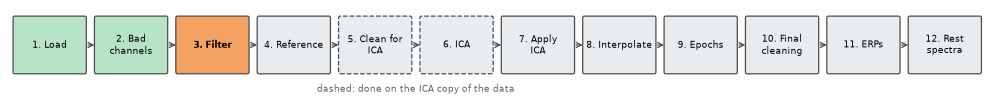

In [22]:
pipeline_map(3)

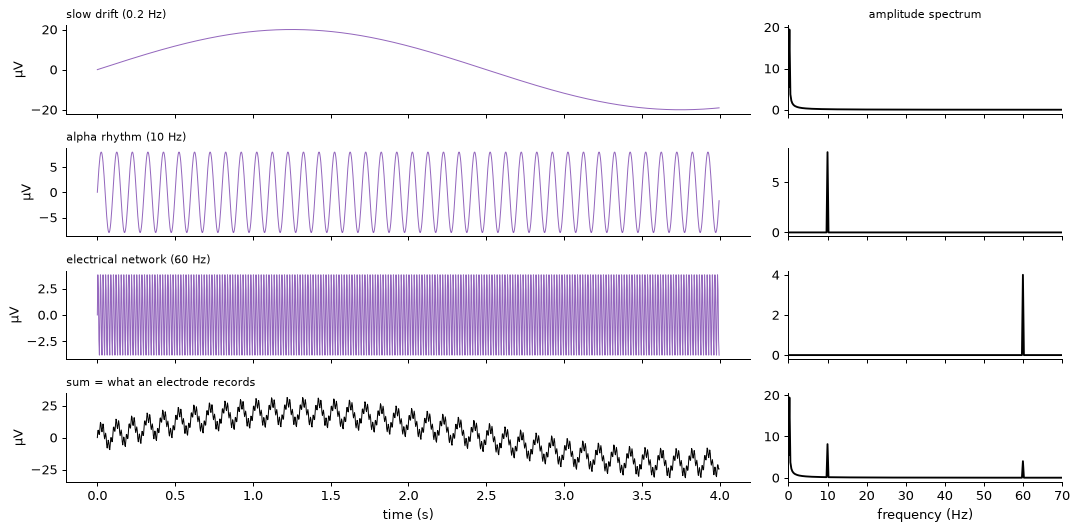

In [23]:
# ---- 3.1 A signal is a sum of rhythms ----------------------------------------------------------------------------------------------
sf_demo = 300
t = np.arange(0, 4, 1 / sf_demo)                             # 4 s of a made-up signal
parts = {'slow drift (0.2 Hz)': 20 * np.sin(2 * np.pi * 0.2 * t),
         'alpha rhythm (10 Hz)': 8 * np.sin(2 * np.pi * 10 * t),
         'electrical network (60 Hz)': 4 * np.sin(2 * np.pi * 60 * t)}
recorded_sum = sum(parts.values())
fig, axes = plt.subplots(len(parts) + 1, 2, figsize=(12, 6), width_ratios=[2.5, 1], sharex='col')
for ax, (label, part) in zip(axes[:, 0], list(parts.items()) + [('sum = what an electrode records', recorded_sum)]):
    ax.plot(t, part, color='k' if label.startswith('sum') else 'tab:purple', lw=0.8)
    ax.set_ylabel('µV')
    ax.set_title(label, fontsize=9, loc='left')
freqs = np.fft.rfftfreq(len(t), 1 / sf_demo)
for ax, part in zip(axes[:, 1], list(parts.values()) + [recorded_sum]):
    ax.plot(freqs, np.abs(np.fft.rfft(part)) / len(t) * 2, color='k')
    ax.set(xlim=(0, 70))
axes[-1, 0].set_xlabel('time (s)')
axes[-1, 1].set_xlabel('frequency (Hz)')
axes[0, 1].set_title('amplitude spectrum', fontsize=9)
plt.tight_layout()
plt.show()

**Look.** The sum (bottom left) is hard to read in time, but its spectrum (bottom right) shows the three parts separately. A filter
keeps some frequencies and removes others: a high-pass at 1 Hz would remove the drift, a low-pass at 30 Hz the 60 Hz noise, and the
alpha rhythm would stay.

**Animation 3.2.** Why not filter everything at 1 Hz, since ICA prefers it? The animation filters a made-up ERP (a P2, an N400 and a
slow late positivity, in grey) with high-pass filters of increasing cut-off. Press play.

In [24]:
# ---- 3.2 Animation: what a high-pass filter does to a slow ERP ---------------------------------------------------------------------
sf_demo = 100
t_erp = np.arange(-1, 2, 1 / sf_demo)                        # one trial, from -1 to 2 s
erp = (2.0 * np.exp(-((t_erp - 0.20) / 0.035) ** 2)          # P2
       - 3.0 * np.exp(-((t_erp - 0.40) / 0.07) ** 2)         # N400
       + 4.0 * np.exp(-((t_erp - 0.65) / 0.15) ** 2))        # late positivity (slow)
padding = np.zeros(60 * sf_demo)                             # 60 s of silence on each side: room for the long filters
cutoffs = [0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0]   # high-pass cut-off frequencies (Hz)
filtered = [mne.filter.filter_data(np.r_[padding, erp, padding], sf_demo, l_freq=c, h_freq=None)[len(padding):-len(padding)]
            for c in cutoffs]

fig, ax = plt.subplots(figsize=(9, 3.6))


def draw(k):
    ax.clear()
    ax.plot(t_erp, erp, color='0.6', lw=3, label='ERP before filtering')
    ax.plot(t_erp, filtered[k], color='tab:red' if cutoffs[k] > 0.3 else 'tab:green', lw=2, label='after the high-pass filter')
    for i, (name, c) in enumerate(COMPONENTS.items()):
        ax.axvspan(*c['window'], color=['0.93', '0.86'][i % 2])
        ax.text(np.mean(c['window']), 4.6, name, ha='center', fontsize=9)
    late = (t_erp >= COMPONENTS['LatePos']['window'][0]) & (t_erp <= COMPONENTS['LatePos']['window'][1])
    kept = filtered[k][late].mean() / erp[late].mean()
    ax.set(xlim=(-0.5, 1.5), ylim=(-4.5, 5.2), xlabel='time from word onset (s)', ylabel='µV',
           title=f'High-pass at {cutoffs[k]:g} Hz: the late positivity keeps {100 * kept:.0f} % of its amplitude')
    ax.axhline(0, color='0.5', lw=0.6)
    ax.legend(loc='lower right', fontsize=8)


anim = animation.FuncAnimation(fig, draw, frames=len(cutoffs), interval=1200)
show_animation(fig, anim)

**Look.** Up to 0.1–0.2 Hz the filtered ERP (green) stays close to the original. From about 0.5 Hz (red) the slow late positivity shrinks, and the
filter creates **fake** negative and positive waves around it, which could be taken for real effects (Tanner et al., 2015). That is why
the data we analyze are filtered at 0.1 Hz, and the 1 Hz copy is used only to train ICA.

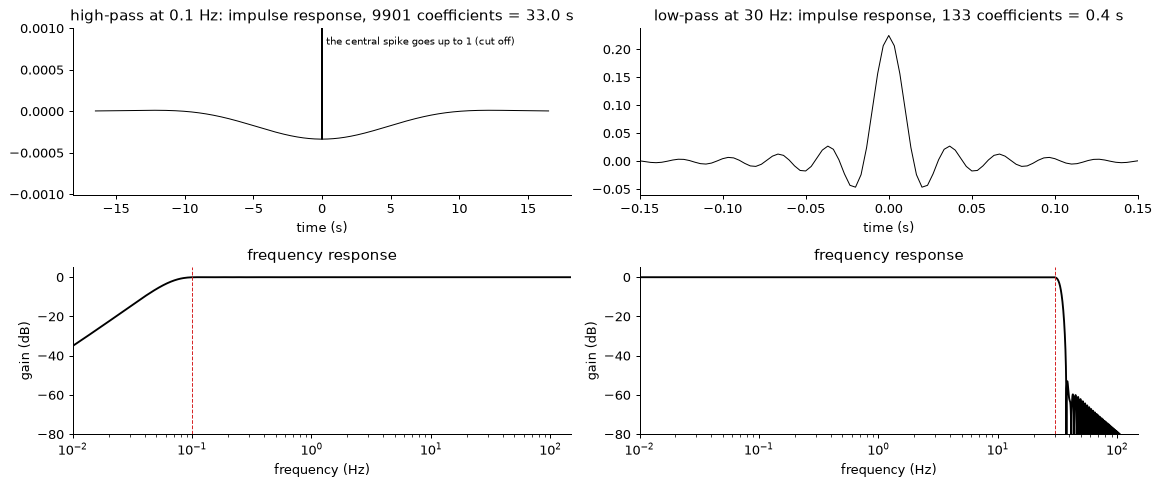

In [25]:
# ---- 3.3 The two filters of the analysis copy --------------------------------------------------------------------------------------
sfreq = raws[FIRST_BLOCK].info['sfreq']
from scipy.signal import freqz                              # the frequency response of a filter
fig, axes = plt.subplots(2, 2, figsize=(13, 5.5))
for col, (l_freq, h_freq, title) in enumerate([(ANALYSIS_BAND[0], None, f'high-pass at {ANALYSIS_BAND[0]:g} Hz'),
                                               (None, ANALYSIS_BAND[1], f'low-pass at {ANALYSIS_BAND[1]:g} Hz')]):
    h = mne.filter.create_filter(None, sfreq, l_freq=l_freq, h_freq=h_freq)   # the filter MNE uses (FIR, Hamming window)
    t_h = (np.arange(len(h)) - len(h) // 2) / sfreq                         # time of each coefficient, 0 in the middle
    axes[0, col].plot(t_h, h, color='k', lw=0.8)
    axes[0, col].set(xlabel='time (s)', title=f'{title}: impulse response, {len(h)} coefficients = {len(h) / sfreq:.1f} s')
    if l_freq is not None:                                   # the long, small tails are invisible next to the central spike: zoom
        axes[0, col].set_ylim(-3 * np.abs(h[:len(h) // 2 - 10]).max(), 3 * np.abs(h[:len(h) // 2 - 10]).max())
        axes[0, col].text(0.3, axes[0, col].get_ylim()[1] * 0.8, 'the central spike goes up to 1 (cut off)', fontsize=8)
    else:
        axes[0, col].set_xlim(-0.15, 0.15)
    f, response = freqz(h, worN=2 ** 16, fs=sfreq)
    axes[1, col].plot(f[1:], 20 * np.log10(np.maximum(np.abs(response[1:]), 1e-6)), color='k')
    axes[1, col].axvline(l_freq or h_freq, color='tab:red', ls='--', lw=0.8)
    axes[1, col].set(xscale='log', xlim=(0.01, sfreq / 2), ylim=(-80, 5), xlabel='frequency (Hz)', ylabel='gain (dB)',
                     title='frequency response')
plt.tight_layout()
plt.show()

**Look.** Each filter is shown two ways. **Impulse response** (top): what the filter does to a single sample, i.e. how it spreads that
sample over time. The 0.1 Hz high-pass filter keeps the sample (the central spike) and subtracts from it a very small, very long
average: its tails last about 33 s. This is why we filter the continuous recording and never the short epochs: an epoch is far too
short for such a filter. The 30 Hz low-pass filter is much shorter (0.4 s). **Frequency response** (bottom): the frequencies that pass
(0 dB) and the ones that are removed (−20 dB = 10 times smaller in amplitude, −40 dB = 100 times smaller); the red line is the cut-off.

In [26]:
# ---- 3.4 Filter: the analysis copy (0.1-30 Hz) and the ICA copy (1-100 Hz) --------------------------------------------------------
notch = [LINE_FREQ * k for k in (1, 2) if LINE_FREQ * k < sfreq / 2]   # 60 and 120 Hz (below half the sampling rate, 150 Hz)
analysis_pz, ica_copy_pz = {}, {}                            # "_pz": still referenced to Pz (step 4 changes that)
for name, raw in recordings.items():
    no_line = raw.copy().notch_filter(notch, picks='eeg')
    analysis_pz[name] = no_line.copy().filter(*ANALYSIS_BAND, picks='eeg')
    ica_copy_pz[name] = no_line.copy().filter(*ICA_BAND, picks='eeg')
print('Notch at', notch, 'Hz; analysis copy', ANALYSIS_BAND, 'Hz; ICA copy', ICA_BAND, 'Hz')

Notch at [60, 120] Hz; analysis copy (0.1, 30.0) Hz; ICA copy (1.0, 100.0) Hz


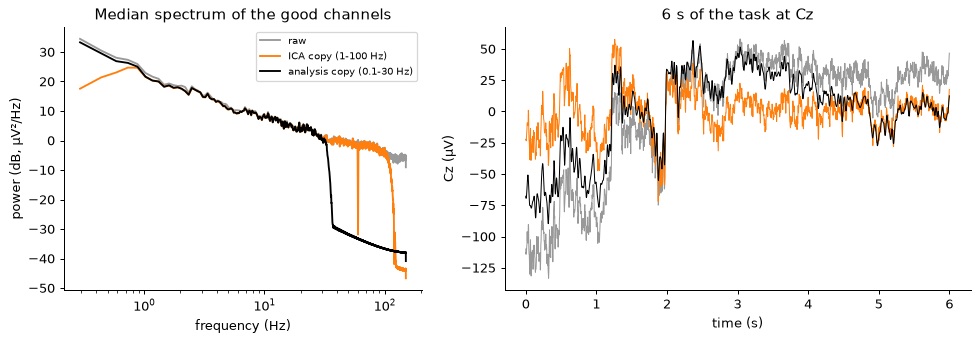

In [27]:
# ---- 3.5 Before and after filtering -----------------------------------------------------------------------------------------------
good_eeg = [ch for ch in eeg_names if ch not in BAD_CHANNELS]  # the good channels, without Pz (still all zeros)
versions = [('raw', recordings['task'], '0.6'), ('ICA copy (1-100 Hz)', ica_copy_pz['task'], 'tab:orange'),
            ('analysis copy (0.1-30 Hz)', analysis_pz['task'], 'k')]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), width_ratios=[1, 1.3])
for label, raw, color in versions:
    psd = raw.compute_psd(method='welch', picks=good_eeg, fmin=0.2, fmax=150, n_fft=2048, tmax=300)
    ax1.plot(psd.freqs, 10 * np.log10(np.median(psd.get_data(), axis=0) * 1e12), color=color, label=label)
    segment = raw.copy().crop(100, 106)
    ax2.plot(segment.times, segment.get_data(picks='Cz')[0] * 1e6 - segment.get_data(picks='Cz')[0].mean() * 1e6,
             color=color, lw=0.8, label=label)
ax1.set(xscale='log', xlabel='frequency (Hz)', ylabel='power (dB, µV²/Hz)', title='Median spectrum of the good channels')
ax2.set(xlabel='time (s)', ylabel='Cz (µV)', title='6 s of the task at Cz')
ax1.legend(fontsize=8)
plt.show()

**Look.** Left: the analysis copy (black) loses everything above 30 Hz. The ICA copy (orange) loses everything below 1 Hz and above
100 Hz, and the notch filter digs a narrow hole at 60 Hz (there was no peak to remove here). Right: the slow wandering of the raw signal
(grey) is gone from both copies, and the analysis copy is smoother because it has no fast activity.

#### Check your understanding

- **Why not filter all the data at 1 Hz, since ICA works better that way?**
  <details><summary>Answer</summary>

  A 1 Hz high-pass filter distorts slow ERPs such as the N400 and the late positivity, and can create fake effects (animation 3.2).

  </details>
- **The 30 Hz low-pass filter already removes 60 Hz. Why do we also need the notch?**
  <details><summary>Answer</summary>

  For the ICA copy, which keeps frequencies up to 100 Hz. In these recordings the line noise is tiny, but in most recordings it would be one of the largest signals in that copy, and ICA would spend components on it.

  </details>
- **Why filter the continuous recording and not the epochs?**
  <details><summary>Answer</summary>

  The 0.1 Hz filter spreads each sample over about 33 s, much longer than a 1-s epoch. Filtering short epochs would distort their edges.

  </details>

## 4. Re-reference to the average

**What.** Choose the zero of the voltage. A voltage is always a difference between two points. The DSI-24 measures each electrode
relative to Pz (the online reference), so Pz itself is 0. We change to the **average reference**: from each channel, at each moment,
we subtract the mean of all good channels.

**Why.** With the Pz reference, every channel contains (minus) the activity at Pz, and electrodes close to Pz look small. The average
reference does not favour one electrode, and Pz gets its own signal back. ICLabel (step 6) was also trained on average-referenced data
(Pion-Tonachini et al., 2019). The bad channels must stay out of the average, or their noise would be copied into every channel: this is
why step 2 came first. MNE leaves out the channels listed in `raw.info['bads']` automatically.

**Limit.** The average reference assumes the electrodes cover the head well. With 19 electrodes the average is only an approximation of
a true zero, but it is the usual choice.

**How.** `raw.set_eeg_reference('average')`.

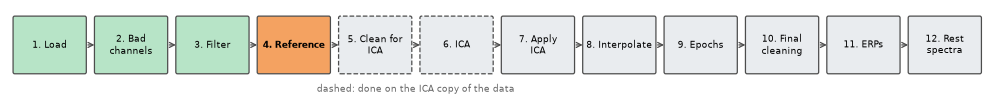

In [28]:
pipeline_map(4)

In [29]:
# ---- 4.1 Re-reference both copies to the average of the good electrodes ------------------------------------------------------------
print(f'Before: largest absolute value of Pz = {np.abs(analysis_pz["task"].get_data(picks="Pz")).max() * 1e6:.3f} µV')
analysis = {name: raw.copy().set_eeg_reference('average') for name, raw in analysis_pz.items()}
ica_copy = {name: raw.copy().set_eeg_reference('average') for name, raw in ica_copy_pz.items()}
good_all = [ch for ch in analysis['task'].copy().pick('eeg').ch_names if ch not in BAD_CHANNELS]   # good channels, with Pz
total = analysis['task'].get_data(picks=good_all).sum(axis=0)
print(f'After:  Pz varies with SD {analysis["task"].get_data(picks="Pz").std() * 1e6:.1f} µV; '
      f'sum of the {len(good_all)} good channels = {np.abs(total).max() * 1e6:.1e} µV (zero at every sample)')

Before: largest absolute value of Pz = 0.000 µV


After:  Pz varies with SD 74.6 µV; sum of the 18 good channels = 7.5e-12 µV (zero at every sample)


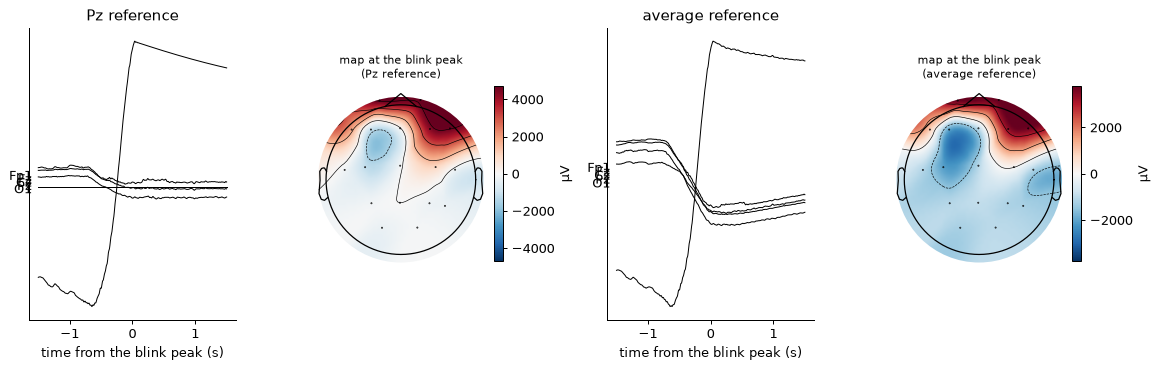

In [30]:
# ---- 4.2 The same blink, seen with the two references -----------------------------------------------------------------------------
frontal = [ch for ch in ['Fp1', 'Fp2', 'F7', 'F8', 'Fz'] if ch not in BAD_CHANNELS][0]   # the good electrode closest to the eyes
blink_events = mne.preprocessing.find_eog_events(analysis['task'], ch_name=frontal)   # one event at the peak of each blink
blink = (blink_events[len(blink_events) // 2, 0] - analysis['task'].first_samp) / sfreq   # one blink in the middle of the task
show = ['Fp1', 'Fz', 'Cz', 'Pz', 'O1']
fig = plt.figure(figsize=(13, 4.2))
for col, (label, data) in enumerate([('Pz reference', analysis_pz['task']), ('average reference', analysis['task'])]):
    piece = data.copy().crop(blink - 1.5, blink + 1.5)
    ax = fig.add_subplot(1, 4, 2 * col + 1)
    for k, ch in enumerate(show):
        ax.plot(piece.times - 1.5, piece.get_data(picks=ch)[0] * 1e6 - 120 * k, color='k', lw=0.8)
        ax.text(-1.6, -120 * k, ch, ha='right', va='center')
    ax.set(title=label, xlabel='time from the blink peak (s)', yticks=[])
    peak = data.copy().pick(good_all).crop(blink, blink)    # all good channels at the blink peak
    ax = fig.add_subplot(1, 4, 2 * col + 2)
    im, _ = mne.viz.plot_topomap(peak.get_data()[:, 0] * 1e6, peak.info, axes=ax, show=False, cmap='RdBu_r')
    plt.colorbar(im, ax=ax, shrink=0.6, label='µV')
    ax.set_title(f'map at the blink peak\n({label})', fontsize=9)
plt.tight_layout()
plt.show()

**Look.** With the Pz reference, Pz is a flat line and the map is pinned to zero at Pz. With the average reference, Pz has a signal and
the map of the blink is large and positive at the front and negative everywhere else (the values sum to zero). Look at Pz and O1 on the
right: the blink now appears there too, upside down and smaller. The average contains the blink, and subtracting the average from every
channel puts an inverted copy of it at the back of the head. Re-referencing changes every channel by the same amount at each moment;
ICA (step 6) will remove the blink from all channels at once.

#### Check your understanding

- **With the average reference, what is the sum of all good channels at any moment?**
  <details><summary>Answer</summary>

  Zero: this is the definition of the average reference (cell 4.1 checks it).

  </details>
- **What would happen if the flat P7 stayed in the average?**
  <details><summary>Answer</summary>

  P7 would count as an electrode at zero volts: the average would be wrong, and after re-referencing P7 would show minus the average, a signal it never recorded. A noisy channel would be worse: 1/18 of its noise would be copied into every other channel.

  </details>
- **Does the reference change the ERP?**
  <details><summary>Answer</summary>

  Yes: an ERP is a voltage difference, so its size at each electrode depends on the reference. Compare ERPs only between studies that use the same reference.

  </details>

## 5. Clean the data used to train ICA

**What.** Cut the ICA copy (rest before, task, rest after, joined) into 2-s pieces, and remove the pieces with large, rare artifacts
(movements, electrode pops, bursts).

**Why.** ICA (step 6) assumes that the sources mix in the same way during the whole recording. A few huge artifacts can capture
components of their own and spoil the decomposition. This cleaning only chooses **what ICA learns from**: the rejected pieces are not
removed from the analysis data.

**How.** AutoReject (Jas et al., 2017), used here only to **screen** the pieces. For each channel, it learns by cross-validation the
largest peak-to-peak amplitude that is still normal. Then, for each piece: if only a few channels are above their threshold, it could
rebuild them from their neighbours (interpolation); if too many are, it rejects the piece. We keep only its decision to reject: the
rejected pieces are left out, and the kept pieces go to ICA unchanged, with no channel rebuilt. Rebuilding a channel in some pieces and
not in others would change how the channels mix from piece to piece, which ICA assumes stays the same. Step 10 uses AutoReject fully,
and rebuilds channels in the epochs.

- `mne.make_fixed_length_epochs(raw, duration=2.0)` cuts the recording into 2-s pieces (and skips the pieces that touch a BAD
  annotation).
- `AutoReject(n_interpolate=..., cv=10)`: `n_interpolate` lists how many channels it may rebuild per piece (it chooses the best
  value), `cv` is the number of cross-validation folds. `ar.get_reject_log(pieces)` returns its decisions without applying them.

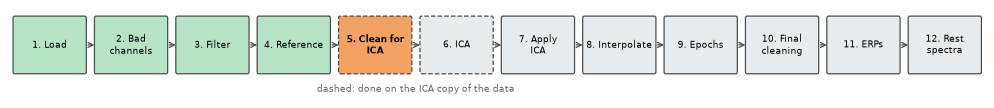

In [31]:
pipeline_map(5)

751 of 822 pieces kept (25.0 min of data for ICA)


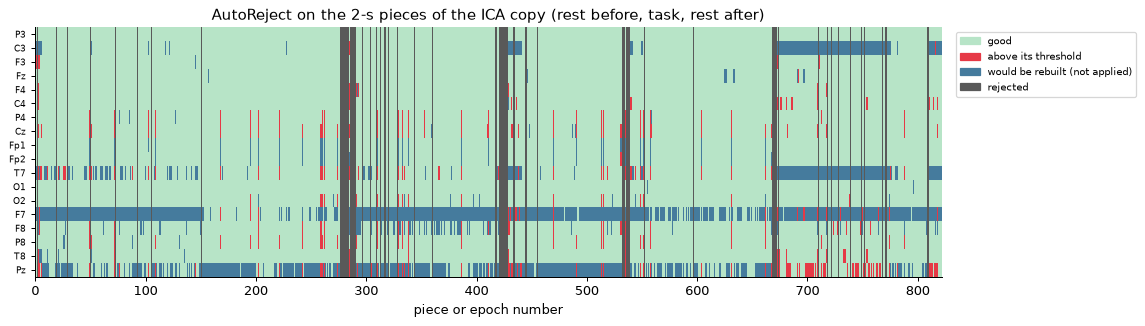

In [32]:
# ---- 5.1 Two-second pieces of the ICA copy, checked by AutoReject -----------------------------------------------------------------
ica_training = mne.concatenate_raws([raw.copy() for raw in ica_copy.values()])   # rest before + task + rest after
pieces = mne.make_fixed_length_epochs(ica_training, duration=SEGMENT_S, preload=True)
ar_ica = AutoReject(n_interpolate=np.array(AR_N_INTERPOLATE), cv=10, random_state=42, picks='eeg', verbose=False)
ar_ica.fit(pieces)                                           # learns the thresholds (about 30 s)
log_ica = ar_ica.get_reject_log(pieces)                      # for each piece and channel: good, to rebuild, or bad
pieces_clean = pieces[~log_ica.bad_epochs]
print(f'{len(pieces_clean)} of {len(pieces)} pieces kept ({len(pieces_clean) * SEGMENT_S / 60:.1f} min of data for ICA)')
plot_reject_log(log_ica, good_all, 'AutoReject on the 2-s pieces of the ICA copy (rest before, task, rest after)',
                rebuilt_label='would be rebuilt (not applied)')

**Look.** Each column is a 2-s piece and each row a good channel. Green cells are good, red cells are above the channel's threshold,
blue cells are channels AutoReject would rebuild (not applied here), and dark columns are rejected pieces. The rejected pieces are mostly in the middle, in the task: the participant blinked about every 2.4 s there,
and a blink is large on 4 to 6 frontal electrodes at once, too many channels for one piece, so AutoReject rejects it. Is that a problem? ICA must still see
blinks to learn the blink component. Cell 5.2 counts them, and checks that ICA has enough data: a common rule of thumb asks for at
least 20 to 30 × (number of channels)² samples.

In [33]:
# ---- 5.2 Blinks, and enough data for ICA? -------------------------------------------------------------------------------------------
training_blinks = mne.preprocessing.find_eog_events(ica_training, ch_name=frontal)[:, 0]   # the sample of each blink
piece_length = int(SEGMENT_S * sfreq)
has_blink = np.array([((training_blinks >= s) & (training_blinks < s + piece_length)).any() for s in pieces.events[:, 0]])
print(f'Rejected: {100 * log_ica.bad_epochs[has_blink].mean():.0f} % of the pieces with a blink, '
      f'{100 * log_ica.bad_epochs[~has_blink].mean():.0f} % of the pieces without one')
print(f'ICA still sees {(has_blink & ~log_ica.bad_epochs).sum()} pieces with a blink')
n_channels = len(good_all)
print(f'{len(pieces_clean) * piece_length:,} samples for ICA; the rule of thumb asks for at least '
      f'{30 * n_channels ** 2:,} (30 × {n_channels}²)')

Rejected: 100 % of the pieces with a blink, 8 % of the pieces without one
ICA still sees 0 pieces with a blink
450,600 samples for ICA; the rule of thumb asks for at least 9,720 (30 × 18²)


#### Check your understanding

**Look.** AutoReject treats blinks as artifacts (they are), so it rejects most of the pieces that contain one, and almost none of the
others. This is a known trade-off of cleaning before ICA: ICA needs to see blinks to learn the blink component. Here enough blinks remain
(step 6 finds the blink component with a probability of 0.98). With fewer blinks left, a gentler rule would be better, for example
rejecting only the pieces above a very high amplitude (several hundred µV).

- **Many pieces were rejected. Is that a problem for the ERPs?**
  <details><summary>Answer</summary>

  No: this step only chooses what ICA learns from. The analysis copy keeps all its data; the epochs are checked later (steps 9 and 10).

  </details>
- **Why 2-s pieces?**
  <details><summary>Answer</summary>

  Short enough that one artifact removes little data, long enough to contain several cycles of slow rhythms. Values from 1 to 4 s are common.

  </details>

## 6. ICA: find the eye and muscle components

**What.** Each electrode records a **mixture** of many sources: brain areas, eye movements, muscles, electrical noise. Independent
component analysis (ICA) finds weights that **unmix** the channels into components, assuming the sources are statistically
independent and not Gaussian (Makeig et al., 1996; Hyvärinen & Oja, 2000). Each component has:

- a **topography**: how strongly it appears at each electrode (where it is);
- a **time course**: its activity over time (when it is active).

**Why.** We can then remove the eye and muscle components and keep the others, instead of throwing away every trial that contains a
blink.

**How many components?** As many as there are independent signals in the data: 19 electrodes − 2 bad channels − 1 lost to the average
reference (the channels sum to zero, so the last one is known from the others) = **16**.

**How.** `mne.preprocessing.ICA(n_components, method='picard')`, then `ica.fit(pieces_clean)`.

**Animation 6.1.** First, ICA on a made-up example with two sources (blinks and an alpha rhythm) recorded by two electrodes.

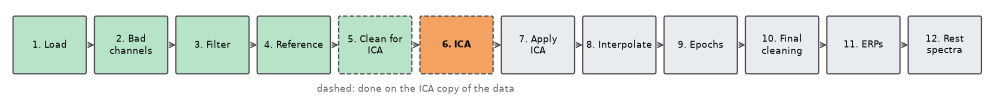

In [34]:
pipeline_map(6)

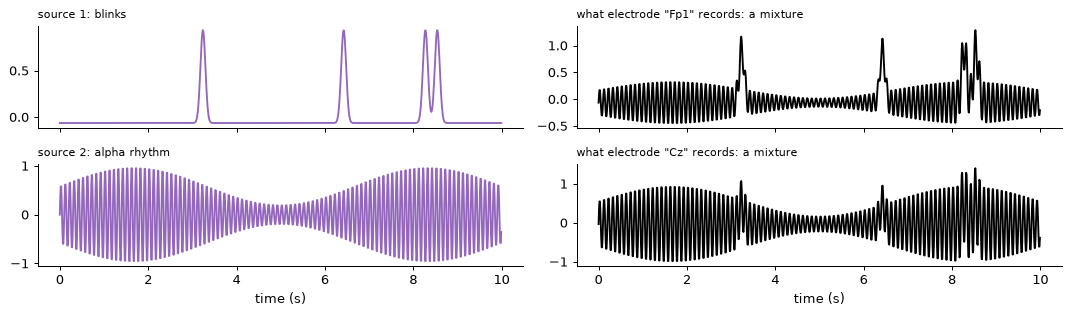

In [35]:
# ---- 6.1 How ICA unmixes: two sources, two electrodes --------------------------------------------------------------------------------
rng = np.random.default_rng(1)
sf_demo = 100
t_demo = np.arange(0, 20, 1 / sf_demo)                       # 20 s at 100 Hz
blinks = sum(np.exp(-((t_demo - b) / 0.08) ** 2) for b in rng.uniform(0.5, 19.5, 9))   # source 1: blinks, rare large peaks
alpha = np.sin(2 * np.pi * 10 * t_demo) * (0.6 + 0.4 * np.sin(2 * np.pi * 0.15 * t_demo))   # source 2: a 10 Hz rhythm
sources = np.vstack([blinks - blinks.mean(), alpha])
mixing = np.array([[1.0, 0.4],                               # "Fp1" records a lot of the blinks and a little alpha
                   [0.5, 1.0]])                              # "Cz" records some blinks and a lot of alpha
recorded = mixing @ sources

# ICA, part 1: whitening. The two channels are made uncorrelated, with the same variance.
centred = recorded - recorded.mean(axis=1, keepdims=True)
eigenvalues, eigenvectors = np.linalg.eigh(np.cov(centred))
white = eigenvectors @ np.diag(eigenvalues ** -0.5) @ eigenvectors.T @ centred


# ICA, part 2: turn the whitened data until the two outputs are as far from Gaussian as possible.
def rotate(angle):
    a = np.deg2rad(angle)
    return np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]]) @ white


angles = np.arange(0, 180, 1)
non_gaussian = np.array([np.abs(kurtosis(rotate(a), axis=1)).sum() for a in angles])   # |kurtosis|: 0 for a Gaussian signal

fig, axes = plt.subplots(2, 2, figsize=(12, 3.6), sharex=True)
for k, (src, rec, ch) in enumerate(zip(sources, recorded, ['Fp1', 'Cz'])):
    axes[k, 0].plot(t_demo[:1000], src[:1000], color='tab:purple')
    axes[k, 0].set_title(f'source {k + 1}: {"blinks" if k == 0 else "alpha rhythm"}', fontsize=9, loc='left')
    axes[k, 1].plot(t_demo[:1000], rec[:1000], color='k')
    axes[k, 1].set_title(f'what electrode "{ch}" records: a mixture', fontsize=9, loc='left')
axes[1, 0].set_xlabel('time (s)')
axes[1, 1].set_xlabel('time (s)')
plt.tight_layout()
plt.show()

In [36]:
# ---- 6.1 (continued) Animation: ICA turns the data until the outputs are independent ------------------------------------------------
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 3.6), width_ratios=[1, 1.8, 1.2])
frames = list(range(0, 91, 6))                               # turning by 90° only swaps the two outputs


def draw(k):
    angle = frames[k]
    outputs = rotate(angle)
    for ax in (ax1, ax2, ax3):
        ax.clear()
    ax1.scatter(outputs[0, ::3], outputs[1, ::3], s=2, color='0.4')
    ax1.set(xlim=(-4, 7), ylim=(-4, 7), xlabel='output 1', ylabel='output 2', title='the data, turned', aspect='equal')
    ax2.plot(t_demo[:1000], outputs[0, :1000] + 4, color='tab:blue')
    ax2.plot(t_demo[:1000], outputs[1, :1000] - 2, color='tab:orange')
    ax2.set(yticks=[], xlabel='time (s)', title='the two outputs')
    ax3.plot(angles[angles <= 90], non_gaussian[angles <= 90], color='k')
    ax3.axvline(angle, color='tab:red')
    ax3.set(xlabel='rotation (degrees)', ylabel='non-Gaussianity', title=f'rotation {angle}°')


anim = animation.FuncAnimation(fig, draw, frames=len(frames), interval=400)
show_animation(fig, anim)
best = angles[np.argmax(non_gaussian)]
print(f'Most non-Gaussian rotation: {best}°. At that angle, output 1 and output 2 are the blinks and the alpha rhythm again.')

Most non-Gaussian rotation: 6°. At that angle, output 1 and output 2 are the blinks and the alpha rhythm again.


**Look.** At most angles each output is still a mixture of blinks and alpha. When the non-Gaussianity curve (right) reaches a peak,
one output contains only the blinks and the other only the alpha rhythm: ICA has recovered the sources without knowing them. Real ICA does
the same in 16 dimensions instead of 2.

In [37]:
# ---- 6.2 Fit ICA on the clean pieces -----------------------------------------------------------------------------------------------
n_components = len(good_all) - 1                             # 19 electrodes - bad channels - 1 for the average reference
print(f'{len(good_all)} good channels -> {n_components} components (MNE estimates the rank of the data at '
      f'{mne.compute_rank(pieces_clean)["eeg"]})')
ica = mne.preprocessing.ICA(n_components=n_components, method=ICA_METHOD, fit_params=ICA_FIT_PARAMS,
                            random_state=ICA_SEED, max_iter=2000)
ica.fit(pieces_clean)                                        # about 30 s
print(ica)

18 good channels -> 17 components (MNE estimates the rank of the data at 17)


<ICA | epochs decomposition, method: picard (fit in 65 iterations on 450600 samples), 17 ICA components (18 PCA components available), channel types: eeg, no sources marked for exclusion>


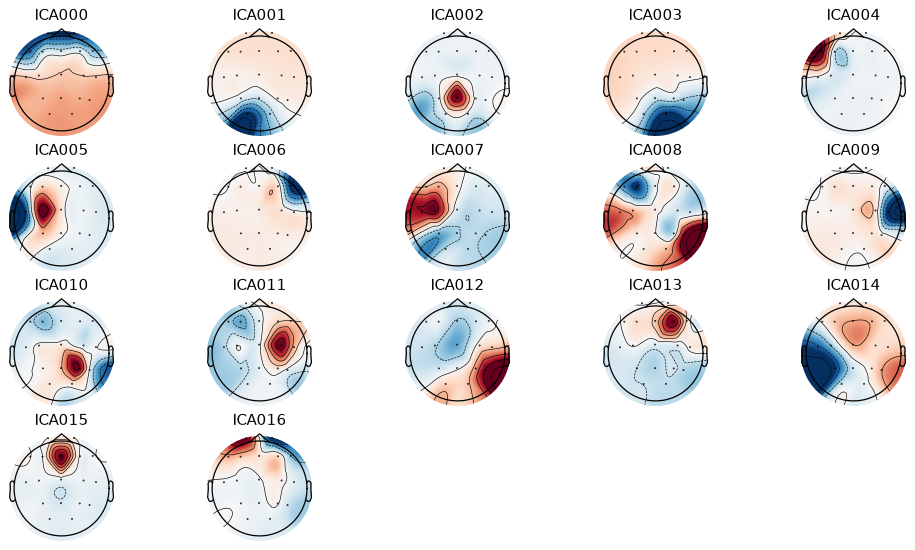

In [38]:
# ---- 6.3 The topographies of the components ----------------------------------------------------------------------------------------
fig = ica.plot_components(show=False)
fig.set_size_inches(11, 6)
plt.show()

**Look.** A blink component has a strong, symmetric topography at the front (Fp1, Fp2). A horizontal eye movement component is
opposite on the left and right at the front (F7 against F8). A muscle component is often concentrated on one electrode at the edge of
the cap (temporal or frontal). Brain components often have smooth topographies, with one positive and one negative area.

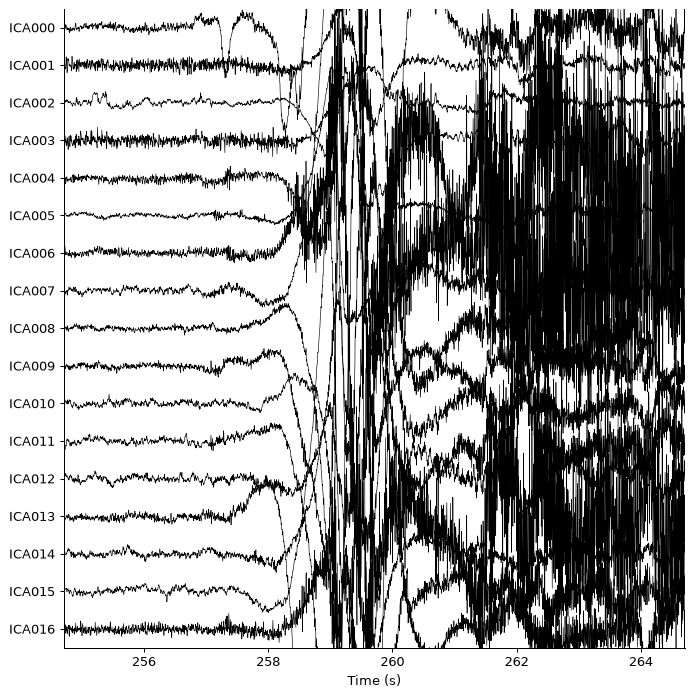

In [39]:
# ---- 6.4 The time courses of the components (10 s of the task) ---------------------------------------------------------------------
ica.plot_sources(ica_copy['task'], start=blink - 5, stop=blink + 5, show_scrollbars=False,
                 title='Time courses of the components, around the blink of step 4');

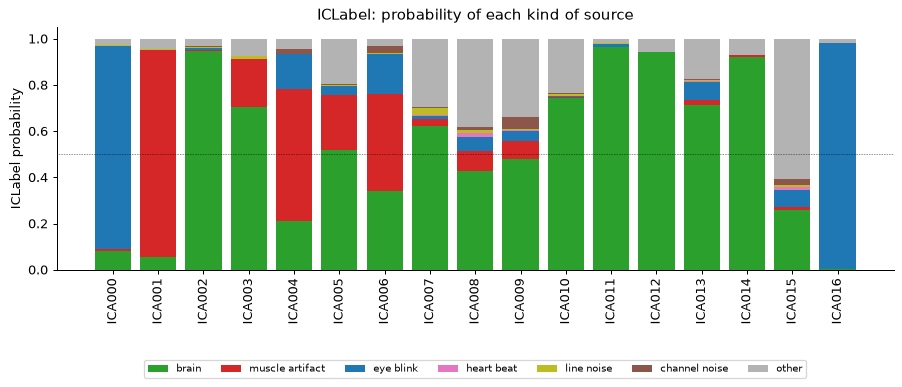

,brain,muscle artifact,eye blink,heart beat,line noise,channel noise,other
ICA000,0.08,0.01,0.88,0.00,0.00,0.00,0.03
ICA001,0.06,0.89,0.00,0.00,0.00,0.00,0.04
ICA002,0.95,0.00,0.01,0.00,0.00,0.00,0.03
ICA003,0.71,0.21,0.00,0.00,0.01,0.00,0.08
ICA004,0.21,0.57,0.15,0.00,0.00,0.02,0.04
ICA005,0.52,0.24,0.04,0.00,0.00,0.00,0.20
ICA006,0.34,0.42,0.17,0.00,0.00,0.03,0.03
ICA007,0.62,0.03,0.01,0.01,0.03,0.00,0.30
ICA008,0.43,0.08,0.06,0.02,0.01,0.01,0.38
ICA009,0.48,0.08,0.04,0.00,0.01,0.05,0.34


In [40]:
# ---- 6.5 ICLabel: what kind of source is each component? ---------------------------------------------------------------------------
CLASSES = ['brain', 'muscle artifact', 'eye blink', 'heart beat', 'line noise', 'channel noise', 'other']
probabilities = np.array(iclabel_label_components(ica_training, ica, inplace=False))   # (components, 7 classes)
labels = pd.DataFrame(probabilities, columns=CLASSES, index=[f'ICA{i:03d}' for i in range(ica.n_components_)])

fig, ax = plt.subplots(figsize=(12, 3.5))
bottom = np.zeros(len(labels))
for cls, color in zip(CLASSES, ['tab:green', 'tab:red', 'tab:blue', 'tab:pink', 'tab:olive', 'tab:brown', '0.7']):
    ax.bar(labels.index, labels[cls], bottom=bottom, color=color, label=cls)
    bottom += labels[cls].to_numpy()
ax.axhline(0.5, color='k', lw=0.5, ls=':')
ax.set(ylabel='ICLabel probability', title='ICLabel: probability of each kind of source')
ax.tick_params(axis='x', rotation=90)
ax.legend(ncol=7, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.35))
plt.show()
labels.round(2)

**How.** ICLabel (Pion-Tonachini et al., 2019; Python version: Li et al., 2022) is a classifier trained on thousands of components labelled
by experts. It looks at each component's topography, spectrum and autocorrelation, and gives the probability of 7 kinds of source.
`iclabel_label_components(raw, ica)` expects data filtered at 1–100 Hz and average-referenced, which is exactly our ICA copy.

**Caution.** ICLabel was trained on wet, high-density EEG. With 19 dry electrodes, take its labels as advice and check them with your
eyes (cells 6.3, 6.4 and 6.7). A second, simple check for blinks: the time course of a blink component should look like the signal of
the electrodes above the eyes.

**The rule** (cell 6.7, numbers in cell 0.3). Remove the 2 components most likely to be "eye", usually one for the blinks and one for
the horizontal eye movements, if each is at least 50 % eye; every component at least 50 % muscle; and a mixture of the two, at least
80 % eye and muscle together with at least 20 % of each. A mixture is neither clearly eye nor clearly muscle, but it is clearly not
brain.

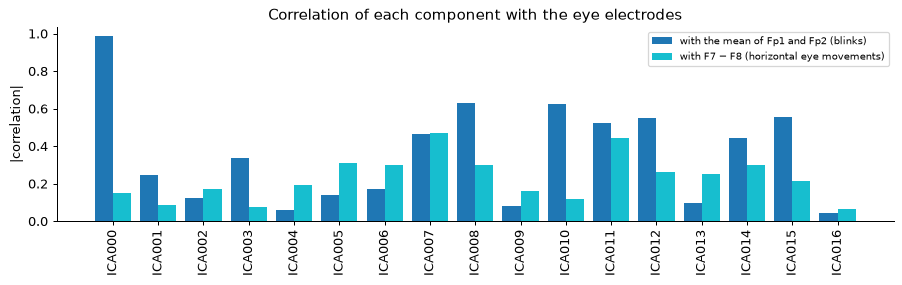

In [41]:
# ---- 6.6 A second opinion for the eyes: correlation with the electrodes around the eyes -----------------------------------------
eye_channels = [ch for ch in ['Fp1', 'Fp2'] if ch not in BAD_CHANNELS] or [frontal]   # above the eyes
component_signals = ica.get_sources(ica_training).get_data()
vertical = ica_training.get_data(picks=eye_channels).mean(axis=0)           # blinks: Fp1 and Fp2 go up together
correlation = np.array([np.corrcoef(s, vertical)[0, 1] for s in component_signals])
fig, ax = plt.subplots(figsize=(12, 2.8))
x = np.arange(len(labels))
ax.bar(x - 0.2, np.abs(correlation), 0.4, color='tab:blue', label=f'with the mean of {" and ".join(eye_channels)} (blinks)')
if not {'F7', 'F8'} & set(BAD_CHANNELS):
    horizontal = ica_training.get_data(picks='F7')[0] - ica_training.get_data(picks='F8')[0]   # looking left or right: F7 and F8 go opposite ways
    ax.bar(x + 0.2, [abs(np.corrcoef(s, horizontal)[0, 1]) for s in component_signals], 0.4, color='tab:cyan',
           label='with F7 − F8 (horizontal eye movements)')
ax.set(xticks=x, xticklabels=labels.index, ylabel='|correlation|', title='Correlation of each component with the eye electrodes')
ax.tick_params(axis='x', rotation=90)
ax.legend(fontsize=8)
plt.show()

**Look.** ICA000 follows Fp1 and Fp2 almost perfectly: the blinks. ICA005 follows F7 − F8: looking to the left and to the right. The
F7 − F8 check is rough: in this participant the blink is larger at F7 than at F8, so F7 − F8 also contains some blink (hence the bar of
ICA000), and a component centred on F7 (ICA011) also follows it. Use these correlations together with the topographies, not alone.

In [42]:
# ---- 6.7 The decision ----------------------------------------------------------------------------------------------------------------
p_eye, p_muscle = labels['eye blink'], labels['muscle artifact']
is_eye = (p_eye.rank(ascending=False, method='first') <= N_EYE) & (p_eye >= EYE_THRESHOLD)   # the N_EYE most likely eye components
is_muscle = p_muscle >= MUSCLE_THRESHOLD
is_mixed = ((p_eye + p_muscle >= MIXED_THRESHOLD)                                  # eye and muscle together, each of them clearly present
            & (p_eye >= 1 - MIXED_THRESHOLD) & (p_muscle >= 1 - MIXED_THRESHOLD))
ica.exclude = [i for i in range(ica.n_components_) if is_eye.iloc[i] or is_mixed.iloc[i] or is_muscle.iloc[i]]
for i in ica.exclude:
    reason = 'eye' if is_eye.iloc[i] else 'eye + muscle' if is_mixed.iloc[i] else 'muscle'
    print(f'ICA{i:03d} removed: {reason} (p eye = {p_eye.iloc[i]:.2f}, p muscle = {p_muscle.iloc[i]:.2f}, '
          f'correlation with the eyes {correlation[i]:+.2f})')
share = ica.get_explained_variance_ratio(pieces_clean, components=ica.exclude)['eeg']
print(f'{len(ica.exclude)} of {ica.n_components_} components removed; together they carry {100 * share:.0f} % of the variance of the ICA copy')

ICA000 removed: eye (p eye = 0.88, p muscle = 0.01, correlation with the eyes -0.99)
ICA001 removed: muscle (p eye = 0.00, p muscle = 0.89, correlation with the eyes -0.24)
ICA004 removed: muscle (p eye = 0.15, p muscle = 0.57, correlation with the eyes +0.06)
ICA016 removed: eye (p eye = 0.98, p muscle = 0.00, correlation with the eyes +0.04)


4 of 17 components removed; together they carry 38 % of the variance of the ICA copy


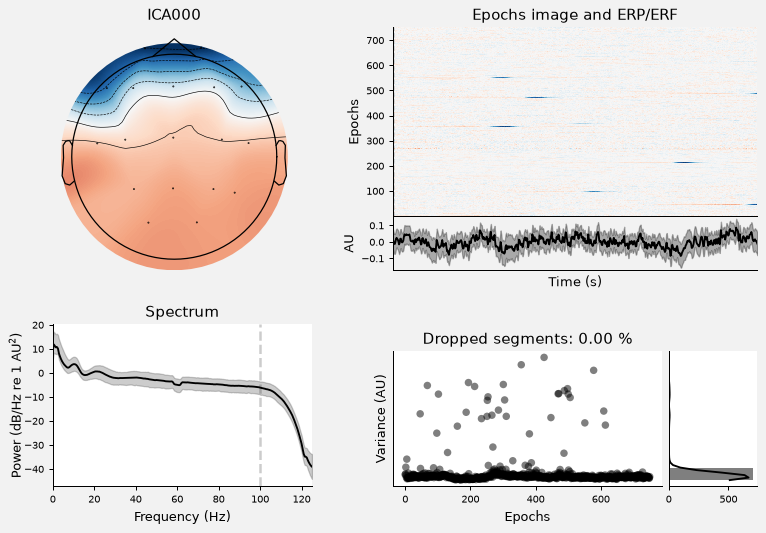

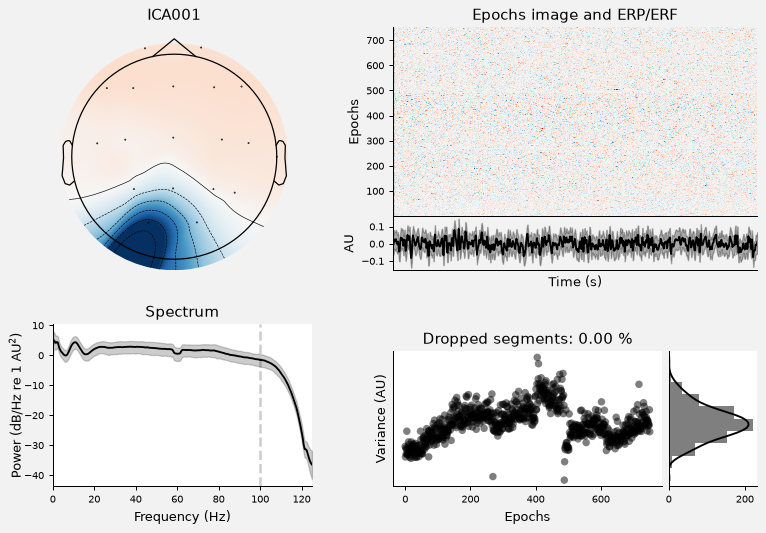

In [43]:
# ---- 6.8 A closer look at two removed components: one eye, one muscle ----------------------------------------------------------------
examples = [i for i in ica.exclude if is_eye.iloc[i]][:1] + [i for i in ica.exclude if not is_eye.iloc[i]][:1]
figs = ica.plot_properties(pieces_clean, picks=examples, show=False)
for fig in figs:
    fig.set_size_inches(9, 6)
plt.show()

**Look.** For each component: its topography (top left), its activity in every 2-s piece (top right, one row per piece; the average
below it means nothing here, because the pieces are not locked to any event), its spectrum (bottom left) and its variance in each piece
(bottom right). The **eye** component has a frontal topography, large rare events and most of its
power at low frequencies. The **muscle** component is concentrated at the edge of the cap, and its spectrum rises or stays flat above
20 Hz, where brain activity falls.

#### Check your understanding

- **Why 16 components and not 19?**
  <details><summary>Answer</summary>

  Pz carries no information of its own before re-referencing (it is the reference), 2 channels are bad, and the average reference makes the remaining channels sum to zero, so the last one is known from the others: 19 − 2 − 1 = 16.

  </details>
- **How would you recognize a blink component without ICLabel?**
  <details><summary>Answer</summary>

  A strong frontal, symmetric topography, a time course with large peaks at the moments of the blinks, and a high correlation with Fp1 and Fp2 (cell 6.6).

  </details>
- **A component is 52 % muscle and 47 % eye. What do you do?**
  <details><summary>Answer</summary>

  Look at its topography, time course and spectrum. Here ICLabel gives it 99 % eye and muscle together and almost nothing for brain (ICA014 of P012), so it is an artifact whichever of the two it is: the mixture rule removes it, even if MUSCLE_THRESHOLD is raised. A component that is also partly brain is a harder call: removing it risks removing brain signal.

  </details>

## 7. Remove the eye and muscle components

**What.** Remove the excluded components from the **analysis copy** (0.1–30 Hz): `ica.apply(raw)` rebuilds the channels from all the
components except the excluded ones.

**Why it works on the other copy.** ICA weights are **spatial**: they say how to combine the electrodes at each moment, whatever the
frequency. So the weights learned on the 1–100 Hz copy can be applied to the 0.1–30 Hz copy (Winkler et al., 2015). We get the best of
both: a good decomposition, and slow ERPs that are not distorted.

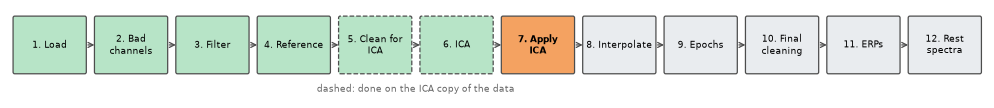

In [44]:
pipeline_map(7)

In [45]:
# ---- 7.1 Apply ICA to the three analysis recordings --------------------------------------------------------------------------------
cleaned = {name: ica.apply(raw.copy()) for name, raw in analysis.items()}
print(f'Removed components {ica.exclude} from:', ', '.join(cleaned))

Removed components [0, 1, 4, 16] from: rest_pre, task, rest_post


3 blinks found in the task (0 per minute)


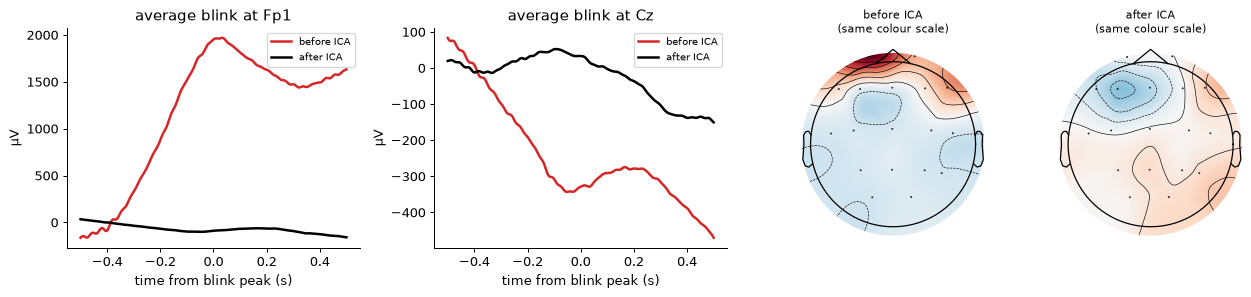

In [46]:
# ---- 7.2 The average blink, before and after ICA -----------------------------------------------------------------------------------
print(f'{len(blink_events)} blinks found in the task ({len(blink_events) / (analysis["task"].times[-1] / 60):.0f} per minute)')
blink_average = {label: mne.Epochs(data['task'], blink_events, tmin=-0.5, tmax=0.5, baseline=(-0.5, -0.3), preload=True).average()
                 for label, data in [('before ICA', analysis), ('after ICA', cleaned)]}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), width_ratios=[1.6, 1.6, 1, 1])
for ax, ch in zip(axes[:2], [frontal, 'Cz']):
    for (label, evoked), color in zip(blink_average.items(), ['tab:red', 'k']):
        ax.plot(evoked.times, evoked.get_data(picks=ch)[0] * 1e6, color=color, lw=2, label=label)
    ax.set(title=f'average blink at {ch}', xlabel='time from blink peak (s)', ylabel='µV')
    ax.legend(fontsize=8)
peak = blink_average['before ICA'].get_data(picks=good_all).max() * 1e6
for ax, (label, evoked) in zip(axes[2:], blink_average.items()):
    data = evoked.copy().pick(good_all).crop(0, 0)
    mne.viz.plot_topomap(data.get_data()[:, 0] * 1e6, data.info, axes=ax, show=False, vlim=(-peak, peak), cmap='RdBu_r')
    ax.set_title(f'{label}\n(same colour scale)', fontsize=9)
plt.tight_layout()
plt.show()

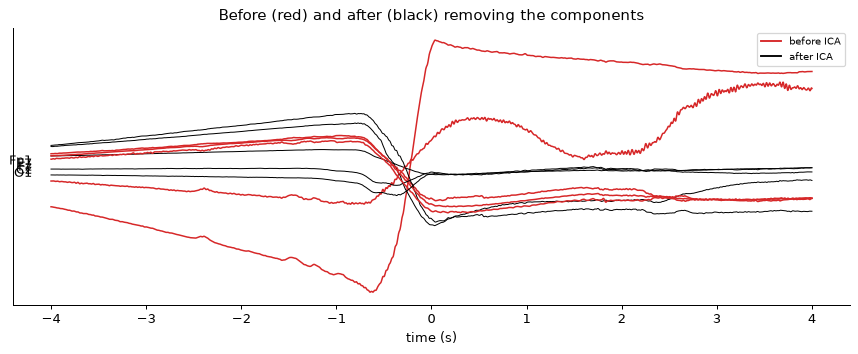

In [47]:
# ---- 7.3 Eight seconds of the task, before and after ICA ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
for k, ch in enumerate(['Fp1', 'F7', 'Fz', 'Cz', 'O1']):
    for data, color, lw in [(analysis, 'tab:red', 1.2), (cleaned, 'k', 0.8)]:
        piece = data['task'].copy().crop(blink - 4, blink + 4)
        ax.plot(piece.times - 4, piece.get_data(picks=ch)[0] * 1e6 - 100 * k, color=color, lw=lw)
    ax.text(-4.2, -100 * k, ch, ha='right', va='center')
ax.plot([], [], color='tab:red', label='before ICA')
ax.plot([], [], color='k', label='after ICA')
ax.set(yticks=[], xlabel='time (s)', title='Before (red) and after (black) removing the components')
ax.legend(loc='upper right', fontsize=8)
plt.show()

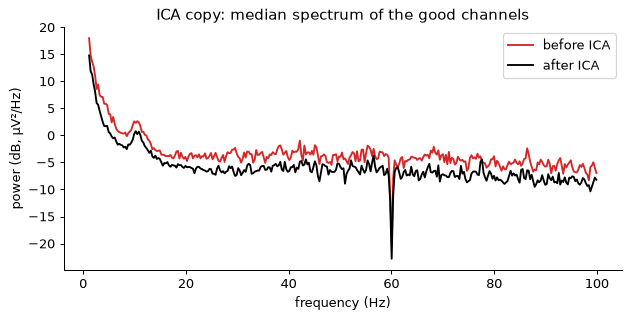

In [48]:
# ---- 7.4 The muscle components: the spectrum of the ICA copy before and after ------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, data, color in [('before ICA', ica_copy['task'], 'tab:red'), ('after ICA', ica.apply(ica_copy['task'].copy()), 'k')]:
    psd = data.compute_psd(method='welch', picks=good_all, fmin=1, fmax=100, n_fft=1024, tmax=300)
    ax.plot(psd.freqs, 10 * np.log10(np.median(psd.get_data(), axis=0) * 1e12), color=color, label=label)
ax.set(xlabel='frequency (Hz)', ylabel='power (dB, µV²/Hz)', title='ICA copy: median spectrum of the good channels')
ax.legend()
plt.show()

**Look.** The average blink (7.2) is reduced to almost nothing at the frontal electrodes, and the map of the blink disappears. In the
traces (7.3), the blinks are gone at Fp1 and F7, while the rest of the signal is unchanged. The spectrum (7.4) loses power at high
frequencies, where the muscle components were.

#### Check your understanding

- **After ICA the blink is gone at Fp1. Is the brain signal at Fp1 gone too?**
  <details><summary>Answer</summary>

  No: only the removed components are subtracted, and the brain components still contribute to Fp1. But any brain activity mixed into a removed component is lost: this is why we remove as few components as possible.

  </details>
- **Why was it important to find the bad channels before ICA?**
  <details><summary>Answer</summary>

  A noisy channel would have taken one or more components for itself, and after the average reference its noise would have been in every channel, mixed with the other sources.

  </details>

## 8. Rebuild the bad channels

**What.** Estimate the signal of the bad channels (here P7) from the other electrodes, with **spherical splines** (Perrin et al., 1989): a smooth surface is
fitted through the good electrodes on a sphere, and read at the position of each bad electrode. Then re-reference to the average again, so
that the average includes all 19 channels.

**Why.** So that every recording has the same 19 channels, for topographic maps and comparisons between participants.

**Limit.** A rebuilt channel is an **estimate**: it contains no new information. Do not draw conclusions from a rebuilt electrode on its
own; our regions (cell 0.3) avoid them.

**How.** `raw.interpolate_bads(reset_bads=True)` rebuilds the channels listed in `raw.info['bads']` and then empties that list.

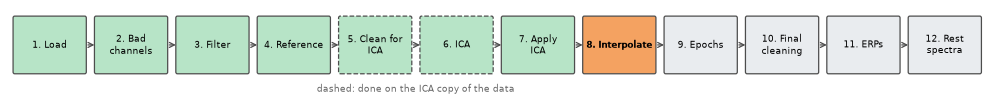

In [49]:
pipeline_map(8)

In [50]:
# ---- 8.1 Rebuild the bad channels in the three recordings --------------------------------------------------------------------------
final = {name: raw.copy().interpolate_bads(reset_bads=True, origin=(0.0, 0.0, 0.04)).set_eeg_reference('average')
         for name, raw in cleaned.items()}
print('Rebuilt:', BAD_CHANNELS, '| bad channels left:', final['task'].info['bads'])
averaged = set(POSTERIOR).union(*[c['region'] for c in COMPONENTS.values()])   # the electrodes averaged in steps 11 and 12
in_regions = sorted(set(BAD_CHANNELS) & averaged)
if in_regions:
    print(f'Warning: {in_regions} are averaged in COMPONENTS or POSTERIOR (cell 0.3), but they are rebuilt, not recorded')

Rebuilt: ['P7'] | bad channels left: []


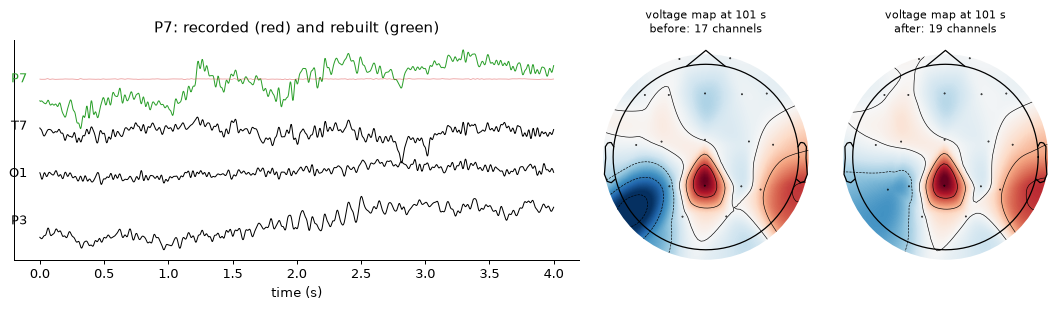

In [51]:
# ---- 8.2 The rebuilt channels next to their neighbours, and the map of the signal amplitude ----------------------------------------
fig, axes = plt.subplots(1, len(BAD_CHANNELS) + 2, figsize=(5 * len(BAD_CHANNELS) + 7, 3.4),
                         width_ratios=[2.5] * len(BAD_CHANNELS) + [1, 1])
piece_before = analysis['task'].copy().crop(100, 104)
piece_after = final['task'].copy().crop(100, 104)
for ax, ch in zip(axes, BAD_CHANNELS):
    neighbours = sorted(good, key=lambda c: np.linalg.norm(positions[c] - positions[ch]))[:3]
    for k, name in enumerate([ch] + neighbours):
        ax.plot(piece_after.times, piece_after.get_data(picks=name)[0] * 1e6 - 40 * k, color='tab:green' if name == ch else 'k', lw=0.8)
        ax.text(-0.1, -40 * k, name, ha='right', va='center', color='tab:green' if name == ch else 'k')
    ax.plot(piece_before.times, piece_before.get_data(picks=ch)[0] * 1e6, color='tab:red', lw=0.5, alpha=0.6)
    ax.set(yticks=[], xlabel='time (s)', title=f'{ch}: recorded (red) and rebuilt (green)')
moment = [(label, data.copy().crop(101.0, 101.1).get_data().mean(axis=1) * 1e6, data.info)   # the mean of 100 ms
          for label, data in [('before: 17 channels', cleaned['task'].copy().pick(good_all)),
                              ('after: 19 channels', final['task'].copy().pick('eeg'))]]
limit = max(np.abs(values).max() for _, values, _ in moment)
for ax, (label, values, info) in zip(axes[-2:], moment):
    mne.viz.plot_topomap(values, info, axes=ax, show=False, vlim=(-limit, limit), cmap='RdBu_r')
    ax.set_title(f'voltage map at 101 s\n{label}', fontsize=9)
plt.tight_layout()
plt.show()

**Look.** The rebuilt P7 (green) looks like plausible EEG and follows its neighbours, unlike the recorded signal (red: a flat line). On
the maps of one moment, the map with the rebuilt channels has the same shape as the map
without them: interpolation fills the holes, but adds nothing the other electrodes did not already say.

## 9. Cut one epoch around each word

**What.** Cut the task recording into **epochs**: one piece per word, from 0.2 s before to 0.8 s after the word. Drop the epochs with a
huge amplitude. Then correct each epoch for its level before the word: the **baseline correction**.

**Why.** An ERP is small (a few µV) compared with the ongoing EEG (tens of µV). Each epoch = ERP + activity that is not time-locked to the
word. Averaging many epochs keeps the ERP and shrinks the rest (step 11). Slow drifts give each epoch its own level; the baseline
correction removes that level, measured in the 200 ms before the word, so that the drifts do not add up in the average.

**Two ways to correct the baseline.** The usual way subtracts each epoch's mean over the baseline from every time point of the epoch.
But the EEG before the word predicts the EEG after it less and less as time goes on: where it no longer predicts it, subtracting the
baseline adds the noise of the baseline instead of removing a drift. The **regression** way (Alday, 2019) lets the data say how much
of the baseline to remove at each time point. At each time point and electrode, a linear regression predicts the epochs from their
condition and their baseline mean; the slope of the baseline is how much each epoch loses (slope × its baseline mean). A slope of 1 at
every time point is the usual subtraction; a slope of 0 is no correction. We use the regression (`BASELINE_METHOD` in cell 0.3).

**How.**
- `mne.events_from_annotations(raw, event_id)` turns the word annotations into an **events** array: one row per word (sample, 0, code).
- `mne.Epochs(raw, events, event_id, tmin, tmax, baseline=None, metadata=...)` cuts the epochs, without baseline correction. `metadata`
  is a table with one row per epoch (the word, the accuracy, the reaction time...), so that we can select trials later, e.g.
  `epochs['response_time > 0.5']`. Epochs that touch a BAD annotation are dropped.
- `epochs.drop_bad(reject=dict(eeg=...))` drops the epochs whose peak-to-peak amplitude is too large on at least one channel (the
  peak-to-peak amplitude does not depend on the baseline).
- `mne.stats.linear_regression(epochs, design_matrix, names)` fits the regression at every time point, as in the MNE tutorial on
  regression-based baseline correction: one column per condition (0 or 1) and one for the baseline mean of each epoch.
  `epochs.apply_baseline(baseline)` would apply the usual subtraction.

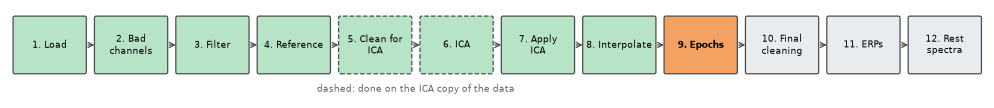

In [52]:
pipeline_map(9)

396 words; the first rows of the events array (sample, 0, code):
[[1773    0    1]
 [2406    0    2]
 [3194    0    3]
 [4043    0    3]]


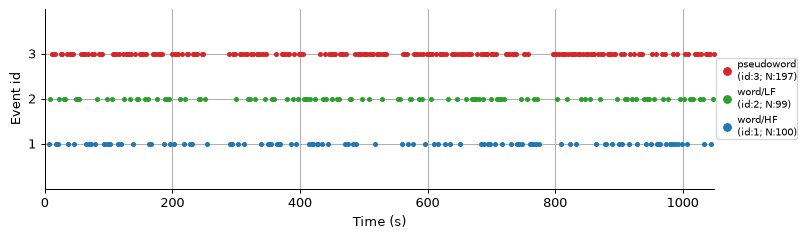

In [53]:
# ---- 9.1 The events: one row per word ----------------------------------------------------------------------------------------------
EVENT_ID = {'word/HF': 1, 'word/LF': 2, 'pseudoword': 3}     # the code of each condition in the events array
word_events, _ = mne.events_from_annotations(final['task'], event_id=EVENT_ID)
assert (word_events[:, 2] == trials['condition'].map(EVENT_ID).to_numpy()).all()   # same words, same order as the trials table
print(f'{len(word_events)} words; the first rows of the events array (sample, 0, code):')
print(word_events[:4])
fig = mne.viz.plot_events(word_events, sfreq=sfreq, first_samp=final['task'].first_samp, event_id=EVENT_ID,
                          color={code: CONDITIONS[name] for name, code in EVENT_ID.items()}, show=False)
fig.set_size_inches(12, 2.6)
plt.show()

In [54]:
# ---- 9.2 The epochs, with the information about each trial ---------------------------------------------------------------------------
metadata = trials[['block', 'trial_in_block', 'stimulus', 'condition', 'accuracy', 'response_time', 'marker_residual_ms']].reset_index(drop=True)
epochs = mne.Epochs(final['task'], word_events, EVENT_ID, tmin=TMIN, tmax=TMAX, baseline=None,   # baseline corrected at 9.4
                    metadata=metadata, preload=True)
print(f'{len(epochs)} epochs of {len(word_events)} words ({len(word_events) - len(epochs)} touched a BAD annotation)')
epochs

393 epochs of 396 words (3 touched a BAD annotation)


<Epochs | 393 events (all good), -0.2 – 0.8 s (baseline off), ~20.8 MiB, data loaded, with metadata,
 'word/HF': 100
 'word/LF': 98
 'pseudoword': 195>

In [55]:
# ---- 9.3 Drop the epochs with a very large amplitude ---------------------------------------------------------------------------------
epochs_threshold = epochs.copy().drop_bad(reject=dict(eeg=REJECT_UV * 1e-6))
print(f'{len(epochs) - len(epochs_threshold)} epochs dropped above {REJECT_UV} µV peak to peak; {len(epochs_threshold)} left')

28 epochs dropped above 150 µV peak to peak; 365 left


At 100 ms the regression removes 0.87 × the baseline mean (median of the electrodes; Cz: 0.92)
At 300 ms the regression removes 0.79 × the baseline mean (median of the electrodes; Cz: 0.88)
At 500 ms the regression removes 0.70 × the baseline mean (median of the electrodes; Cz: 0.87)
At 700 ms the regression removes 0.65 × the baseline mean (median of the electrodes; Cz: 0.76)


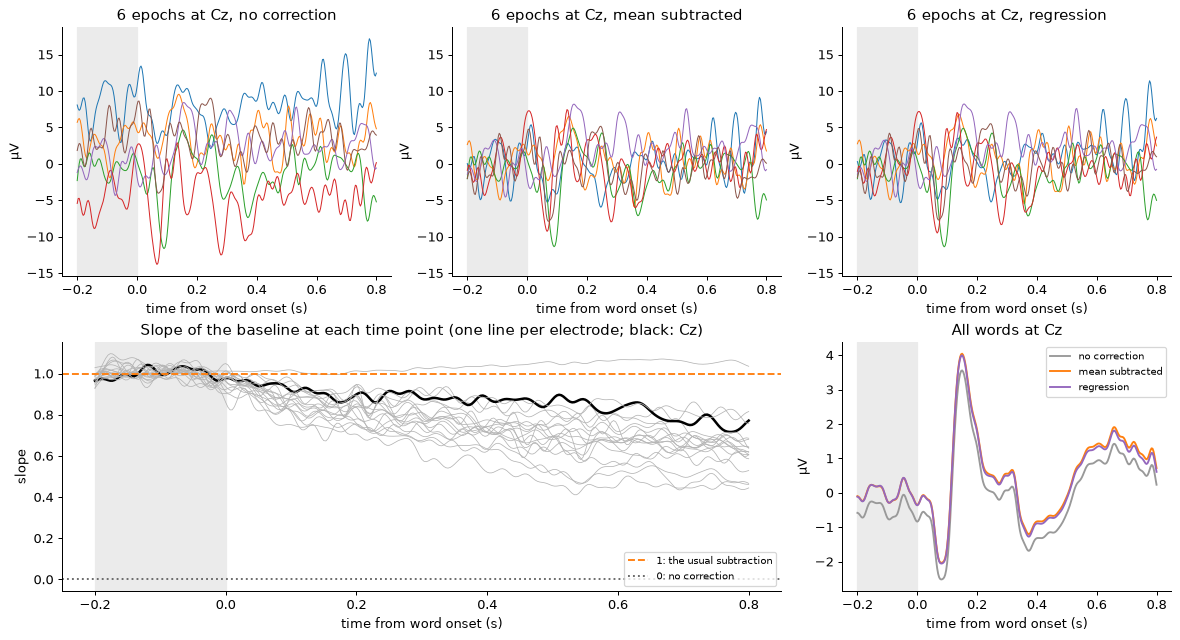

In [56]:
# ---- 9.4 The baseline correction: the usual subtraction, and the regression we use ---------------------------------------------------
def regression_baseline(ep):
    """Regression-based baseline correction (Alday, 2019). At each time point and electrode, a linear regression predicts the epochs
    from their condition (one 0/1 column each) and their baseline mean; each epoch then loses its baseline mean times the slope of the
    baseline. Returns the corrected epochs and the slopes (electrodes x times): 1 is the usual subtraction, 0 no correction."""
    eeg = ep.copy().pick('eeg')
    baseline = eeg.copy().crop(*BASELINE).get_data().mean(axis=-1)              # epochs x electrodes: the level before the word
    codes = np.unique(ep.events[:, 2])
    conditions = [ep.events[:, 2] == code for code in codes]                     # one 0/1 column per condition
    slopes = np.array([mne.stats.linear_regression(eeg.copy().pick([ch]), np.column_stack(conditions + [baseline[:, k]]),
                                                   names=[*map(str, codes), 'baseline'])['baseline'].beta.data[0]
                       for k, ch in enumerate(eeg.ch_names)])                   # electrodes x times
    corrected = ep.copy().apply_function(lambda x: x - baseline[:, :, None] * slopes, picks='eeg', channel_wise=False)
    return corrected, slopes


by_mean = epochs_threshold.copy().apply_baseline(BASELINE)   # the usual correction: the slope is 1 at every time point
by_regression, slopes = regression_baseline(epochs_threshold)
epochs_corrected = by_regression if BASELINE_METHOD == 'regression' else by_mean   # the correction used from here on (cell 0.3)
eeg_names = epochs_threshold.copy().pick('eeg').ch_names
for t in (0.1, 0.3, 0.5, 0.7):
    k = np.argmin(np.abs(epochs_threshold.times - t))
    print(f'At {t * 1000:.0f} ms the regression removes {np.median(slopes[:, k]):.2f} × the baseline mean '
          f'(median of the electrodes; Cz: {slopes[eeg_names.index("Cz"), k]:.2f})')

some = np.arange(0, 60, 10)                                  # six epochs
fig, axes = plt.subplot_mosaic([['none', 'mean', 'regression'], ['slope', 'slope', 'erp']], figsize=(13, 7), layout='constrained')
for key, label, data in [('none', 'no correction', epochs_threshold), ('mean', 'mean subtracted', by_mean),
                         ('regression', 'regression', by_regression)]:
    for s in data.get_data(picks='Cz')[some, 0] * 1e6:
        axes[key].plot(data.times, s, lw=0.8)
    axes[key].set(title=f'6 epochs at Cz, {label}', xlabel='time from word onset (s)', ylabel='µV')
axes['mean'].sharey(axes['none'])
axes['regression'].sharey(axes['none'])
for ch, slope in zip(eeg_names, slopes):
    axes['slope'].plot(epochs_threshold.times, slope, color='k' if ch == 'Cz' else '0.7', lw=2 if ch == 'Cz' else 0.6)
axes['slope'].axhline(1, color='tab:orange', ls='--', label='1: the usual subtraction')
axes['slope'].axhline(0, color='0.4', ls=':', label='0: no correction')
axes['slope'].set(title='Slope of the baseline at each time point (one line per electrode; black: Cz)',
                  xlabel='time from word onset (s)', ylabel='slope')
axes['slope'].legend(fontsize=8)
for label, data, color in [('no correction', epochs_threshold, '0.6'), ('mean subtracted', by_mean, 'tab:orange'),
                           ('regression', by_regression, 'tab:purple')]:
    axes['erp'].plot(data.times, data['word'].average().get_data(picks='Cz')[0] * 1e6, color=color, label=label)
axes['erp'].set(title='All words at Cz', xlabel='time from word onset (s)', ylabel='µV')
axes['erp'].legend(fontsize=8)
for ax in axes.values():
    ax.axvspan(*BASELINE, color='0.92', zorder=0)
plt.show()

**Look.** Top: six epochs at Cz. Without correction (left), each epoch has its own level. The usual subtraction (middle) centres every
epoch on zero before the word (grey band). The regression (right) does too, but removes less of each epoch's level after the word.
Bottom left: the slope of the baseline at each time point, for each electrode. It is about 1 in the baseline (its mean there is exactly
1) and falls after the word: at 300 ms the regression removes about two thirds of each epoch's baseline level (median of the electrodes
0.65), and at 700 ms about half (0.48). The EEG before the word predicts the EEG after it less and less, so late in the epoch the usual
subtraction removes more than the data justify. Bottom right: the word ERP at Cz has the same shape with both corrections; only its
level after the word changes, here by up to about 1.5 µV. The differences between conditions change less (in P012 by at most about
0.3 µV, cell 11.5): the words come in random order, so on average the conditions start from the same level.

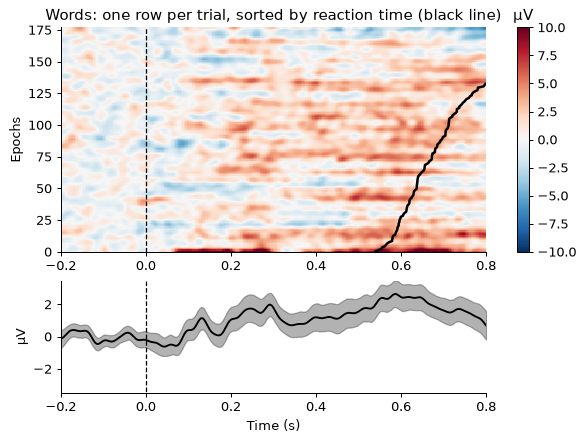

In [57]:
# ---- 9.5 Every single trial: the ERP image, sorted by reaction time ------------------------------------------------------------------
answered = epochs_corrected['word'][epochs_corrected['word'].metadata['response_time'].notna().to_numpy()]
rt = answered.metadata['response_time'].to_numpy()
figs = answered.plot_image(picks=REGION, combine='mean', order=np.argsort(rt), overlay_times=rt, sigma=2,
                           vmin=-10, vmax=10, title='Words: one row per trial, sorted by reaction time (black line)', show=False)
plt.show()

**Look.** Each row is one trial (mean of the centro-parietal electrodes), sorted from the fastest to the slowest response; the black line
is the moment of the response. The average of all rows is at the bottom. Single trials are noisy, but a pattern appears across rows.
Ask: does the positive activity (red) follow the black line, or does it start at the same time after the word in every row? Activity
that follows the response is linked to the decision or the movement; activity at a fixed time after the word is linked to the word. Here,
the positivity starts at about the same time in fast and slow trials.

#### Check your understanding

- **Why from −0.2 to 0.8 s?**
  <details><summary>Answer</summary>

  We need a baseline before the word, and the components we study (P2, P350, N400 and the late positivity) are over by about 0.8 s.

  </details>
- **Without the baseline correction, what would happen to the average?**
  <details><summary>Answer</summary>

  Each epoch keeps its own offset (cell 9.4). The offsets do not cancel exactly, so the average would be shifted and noisier.

  </details>
- **Why keep the trial information as metadata?**
  <details><summary>Answer</summary>

  To select trials by any property afterwards: correct trials, fast or slow responses, one block, one word...

  </details>

## 10. Final cleaning of the epochs

**What.** AutoReject again, now on the epochs. Then keep the trials we want for the ERPs: words whose onset is confirmed by their own tone,
and correct answers with a reaction time of at least 250 ms.

**Why.** Some epochs still have a local problem: one channel jumps in one trial. AutoReject rebuilds a few channels in that epoch, or drops
the epoch if too many are bad. Errors and anticipations (very fast responses) do not reflect normal word recognition. The onset of each word is the moment
the tablet drew it, put on the EEG clock through a fit to the tones the tablet sent to the trigger channel, one per word (column
`marker_residual_ms` of the events: the tone minus the onset). When a word's own tone is missing or more than 5 ms away, its onset cannot be
checked, so we leave it out: usually the first word of a block, whose tone often starts late, and words next to a dropout of the headset.

**How.** `ar.fit(epochs)` learns the thresholds, then `ar.transform(epochs, return_log=True)` returns the repaired epochs and the log.

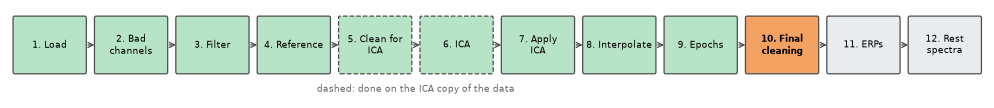

In [58]:
pipeline_map(10)

AutoReject: 0 epochs dropped, 344 epochs with at least one channel rebuilt


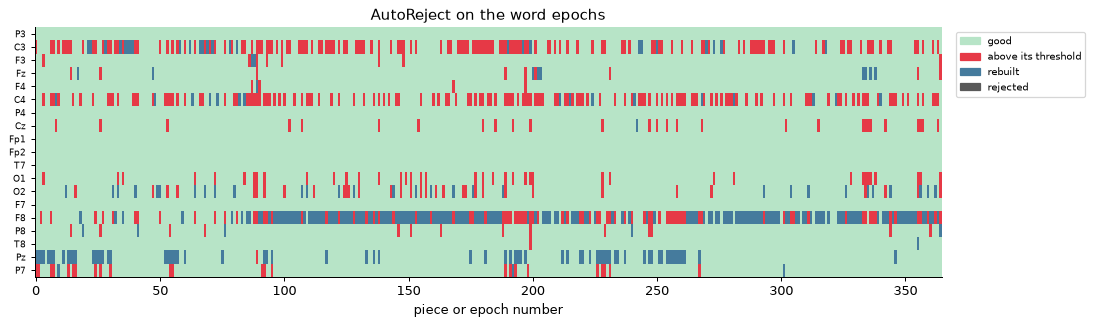

In [59]:
# ---- 10.1 AutoReject on the epochs ---------------------------------------------------------------------------------------------------
ar_epochs = AutoReject(n_interpolate=np.array(AR_N_INTERPOLATE), cv=10, random_state=42, picks='eeg', verbose=False)
ar_epochs.fit(epochs_corrected)
epochs_repaired, log_epochs = ar_epochs.transform(epochs_corrected, return_log=True)
rebuilt = [' '.join(BAD_CHANNELS + [ch for ch, label in zip(log_epochs.ch_names, row) if label == 2 and ch not in BAD_CHANNELS])
           for row in log_epochs.labels[~log_epochs.bad_epochs]]                   # each epoch: rebuilt at step 8 or just now
epochs_repaired.metadata = epochs_repaired.metadata.assign(rebuilt=rebuilt)         # saved with the epochs (13.1)
print(f'AutoReject: {log_epochs.bad_epochs.sum()} epochs dropped, '
      f'{(log_epochs.labels == 2).any(axis=1).sum()} epochs with at least one channel rebuilt')
plot_reject_log(log_epochs, good_all + BAD_CHANNELS, 'AutoReject on the word epochs')

In [60]:
# ---- 10.2 Keep the trials with a confirmed onset and a normal correct answer, and count what is left ------------------------------
confirmed = (epochs_repaired.metadata['marker_residual_ms'].abs() <= MAX_TONE_MS).to_numpy()   # its own tone is there (not NaN) and close
keep = confirmed & (epochs_repaired.metadata['response_time'] >= MIN_RT_S).to_numpy()           # also False for a missing response
if KEEP_CORRECT_ONLY:
    keep = keep & (epochs_repaired.metadata['accuracy'] == 1).to_numpy()
epochs_clean = epochs_repaired[keep]
counts = pd.DataFrame({
    'words': trials['condition'].value_counts(),
    'not in a BAD annotation': epochs.metadata['condition'].value_counts(),
    f'below {REJECT_UV} µV': epochs_threshold.metadata['condition'].value_counts(),
    'after AutoReject': epochs_repaired.metadata['condition'].value_counts(),
    'onset confirmed by its tone': epochs_repaired[confirmed].metadata['condition'].value_counts(),
    f'correct, RT ≥ {MIN_RT_S * 1000:.0f} ms': epochs_clean.metadata['condition'].value_counts(),
}).loc[list(CONDITIONS)]
counts.loc['total'] = counts.sum()
counts

,words,not in a BAD annotation,below 150 µV,after AutoReject,onset confirmed by its tone,"correct, RT ≥ 10 ms"
condition,,,,,,
word/HF,100,100,91,91,87,82
word/LF,99,98,88,88,84,71
pseudoword,197,195,186,186,173,159
total,396,393,365,365,344,312


**Look.** Most of the trials survive. In this participant, behaviour (errors) removes more trials than the EEG cleaning: each step is
counted, so you can see where the trials go. The tone check removes 3 words: the first word of blocks 2, 3 and 4, whose tone started
60 to 90 ms late (their onset comes from the tablet's drawing time and is probably right, but it cannot be checked).

## 11. The ERPs

**What.** Average the epochs of each condition: the **evoked response** or ERP. `epochs['word/HF'].average()` returns an `Evoked` object.
Then measure each component: the mean of its electrodes in its time window.

**Why averaging works.** The ERP is the same in every trial; the rest of the EEG is not time-locked to the word and varies randomly from
trial to trial. When we average N trials, the ERP stays and the rest shrinks like 1/√N: 4 times more trials halve the noise.
Animation 11.1 shows it on real data.

**The components** (cell 0.3). Their windows and electrodes come from the literature, not from these data.

| Component | Window | Electrodes averaged | Prediction | Source |
|---|---|---|---|---|
| P2 | 180–260 ms | P3, Pz, P4 | none for words against pseudowords | Vergara-Martínez et al. (2013): no significant difference in this window |
| P350 | 260–360 ms | P3, Pz, P4 | words more positive than pseudowords: pseudoword − words < 0 | Vergara-Martínez et al. (2013) |
| N400a | 360–470 ms | Cz, Pz, P3, P4 | pseudoword − words < 0, and LF − HF < 0 | windows: Vergara-Martínez et al. (2013); electrodes: Kutas & Federmeier (2011) |
| N400b | 470–580 ms | Cz, Pz, P3, P4 | pseudoword − words < 0, and LF − HF < 0 | the same |
| LatePos | 600–800 ms | Cz, Pz, P3, P4 | none: exploratory | not defined by Vergara-Martínez et al. (2013) |

Vergara-Martínez et al. (2013, Experiment 2) is a lexical decision task with English words, recorded with a mastoid reference. The P2
and P350 electrodes follow their description of two positive waves over the back of the head, at about 200 and 300 ms, and the two N400
windows are theirs; the N400 electrodes are the centre and back of the head, where the N400 is classically largest. The late positivity
is exploratory: it may reflect the decision, and the responses fall in its window (median reaction times between 0.48 and 0.85 s), so it
also contains the preparation of the movement. Notebook 09 measures a late positivity just before the tap. Three points to keep in mind
when you compare our figures with papers (the figures show frequent and rare words, `PLOTTED` in cell 0.3; the tables of 11.5
give all three conditions):

- **The N400 is a negative-going effect, but its window can stay above 0 µV.** The prediction is that pseudowords (and rare words) are
  more negative than the condition they are compared with; both curves can stay positive.
- **Positive is up here.** Many ERP papers, Vergara-Martínez et al. (2013) included, plot negative up.
- **The reference changes the maps.** Many N400 studies, Vergara-Martínez et al. (2013) included, use the mastoids (behind the ears) as
  the reference. We use the average of all electrodes (step 4): the electrodes then sum to zero at every moment, so a positivity at the
  centre of the head comes with a negativity at the edges.

**The group.** One participant is noisy. After each figure of P012 comes the same figure for the group: every participant processed by
this notebook, through exactly the same pipeline (cell 13.1 saves each participant's epochs in `mes_resultats`). As in notebook 09, the
electrodes rebuilt from their neighbours (steps 8 and 10) do not enter a participant's ERP, and an electrode recorded by fewer than half
of the participants is not shown (P7 was flat in everyone). To add a participant, set `SUBJECT` in cell 0.3 and run the whole notebook
(about 2 minutes). P008 cannot be added: its recording is too noisy for this simple pipeline (every epoch is above 150 µV at step 9).

**Timing.** Each word's onset is the moment the tablet drew it, put on the EEG clock through the tones of the trigger channel (cell 10.2).
Checked again from the raw files, the tones agree with the onsets to about 2 ms. But no photodiode measured when the word really lit up
the screen, so every onset may be off by the same unknown delay. From P016 the tablet ran at 60 Hz instead of 120 Hz. The early visual
responses of P017 and P018 come 27 and 40 ms later than the average of the participants recorded at 120 Hz, who themselves vary from
−20 to +30 ms (P016: +3 ms). This may be a longer display delay; a photodiode test would tell.

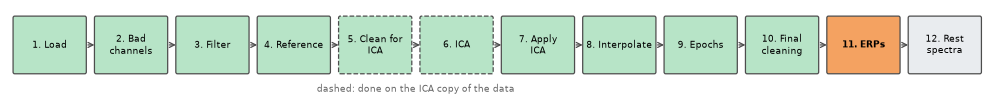

In [61]:
pipeline_map(11)

In [62]:
# ---- 11.0 The group: every participant processed by this notebook --------------------------------------------------------------------
GROUP_MIN = 3                                                # the group figures need at least 3 participants
MIN_EPOCHS = 20                                              # an electrode recorded in fewer epochs has no ERP for that participant


def recorded_erp(ep):
    """The ERP of each EEG electrode, averaged over the epochs in which it was recorded: an electrode rebuilt from its neighbours in
    an epoch (metadata column 'rebuilt', steps 8 and 10) does not count. With fewer than MIN_EPOCHS such epochs, its ERP is NaN."""
    ep = ep.copy().pick('eeg')
    recorded = np.array([[ch not in str(r).split() for ch in ep.ch_names] for r in ep.metadata['rebuilt']])   # epochs x electrodes
    n = recorded.sum(axis=0)                                 # the number of epochs in which each electrode was recorded
    mean = np.where(recorded[:, :, None], ep.get_data(), 0.0).sum(axis=0) / np.maximum(n, 1)[:, None]
    mean[n < MIN_EPOCHS] = np.nan
    return mne.EvokedArray(mean, ep.info, tmin=ep.tmin, nave=len(ep))


saved = {path.name.split('_')[0][4:]: path for path in sorted((DATA_DIR / 'mes_resultats').glob('sub-*_teaching_seated-epo.fif'))}
group = {name: [] for name in [*CONDITIONS, 'word']}        # condition: the ERP of each participant
participants = []
for participant in sorted(set(saved) | {SUBJECT}):
    ep = epochs_clean if participant == SUBJECT else mne.read_epochs(saved[participant])   # this participant: this run
    if 'rebuilt' not in ep.metadata:                         # saved by an older version of this notebook
        print(f'{participant} left out: run this notebook again with SUBJECT = {participant!r}')
        continue
    participants.append(participant)
    for name in group:
        group[name].append(recorded_erp(ep[name]))

ch_group = group['word'][0].ch_names
finite = np.isfinite([[e.data[:, 0] for e in group[name]] for name in CONDITIONS]).all(axis=0)   # participants x electrodes
n_recorded = finite.sum(axis=0)                              # how many participants recorded each electrode
seen = n_recorded >= max(GROUP_MIN, len(participants) / 2)   # the rule of notebook 09: at least 3 participants, and half of them


def grand_average(evokeds):
    """The group ERP: at each electrode, the mean of the participants who recorded it. Electrodes recorded by too few participants
    (seen is False) are left out."""
    data = np.nanmean([e.data[seen] for e in evokeds], axis=0)
    return mne.EvokedArray(data, mne.pick_info(evokeds[0].info, np.flatnonzero(seen)), tmin=evokeds[0].tmin, nave=len(evokeds))


def group_ready():
    """True if the group has at least GROUP_MIN participants; otherwise says how to add some."""
    if len(participants) < GROUP_MIN:
        print(f'The group has {len(participants)} participant(s): run this notebook for other participants first (cell 0.3, '
              f'SUBJECT). Each run saves its epochs in mes_resultats (cell 13.1).')
    return len(participants) >= GROUP_MIN


not_yet = [p.name[4:] for p in sorted((DATA_DIR / 'bids').glob('sub-*')) if p.name[4:] not in participants]
print(f'The group: {len(participants)} participants ({", ".join(participants)})')
if not_yet:
    print('Not yet run through this notebook:', ', '.join(not_yet))
print('Participants who recorded each electrode:', ', '.join(f'{ch} {n}' for ch, n in zip(ch_group, n_recorded)))
print('Left out of the group figures (recorded by fewer than half):', ', '.join(np.array(ch_group)[~seen]) or 'none')

The group: 13 participants (P002, P003, P004, P006, P007, P009, P010, P012, P014, P015, P016, P017, P018)
Not yet run through this notebook: P008
Participants who recorded each electrode: P3 13, C3 13, F3 13, Fz 13, F4 12, C4 13, P4 13, Cz 13, Fp1 12, Fp2 12, T7 13, P7 0, O1 13, O2 12, F7 11, F8 12, P8 13, T8 13, Pz 13
Left out of the group figures (recorded by fewer than half): P7


In [63]:
# ---- 11.1 Animation: the ERP appears as we average more trials -----------------------------------------------------------------------
word_trials = epochs_clean['word'].get_data(picks=REGION).mean(axis=1) * 1e6   # (trials, times), µV, mean of the region
order = np.random.default_rng(0).permutation(len(word_trials))                 # a random order of the trials
times = epochs_clean.times
counts_to_show = [n for n in [1, 2, 4, 8, 16, 32, 64, 128] if n < len(word_trials)] + [len(word_trials)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))


def draw(k):
    n = counts_to_show[k]
    chosen = word_trials[order[:n]]
    mean = chosen.mean(axis=0)
    for ax in (ax1, ax2):
        ax.clear()
        ax.axvline(0, color='0.5', lw=0.8)
        ax.axhline(0, color='0.5', lw=0.8)
    for trial in chosen[:30]:
        ax1.plot(times, trial, color='0.6', lw=0.5)
    ax1.set(ylim=(-45, 45), xlabel='time from word onset (s)', ylabel='µV', title=f'{min(n, 30)} of the {n} trials')
    if n > 1:
        sem = chosen.std(axis=0, ddof=1) / np.sqrt(n)
        ax2.fill_between(times, mean - sem, mean + sem, color='tab:purple', alpha=0.3)
    ax2.plot(times, mean, color='k', lw=2)
    ax2.set(ylim=(-12, 12), xlabel='time from word onset (s)',
            title=f'Average of {n} trials: noise before the word {mean[times < 0].std():.1f} µV')


anim = animation.FuncAnimation(fig, draw, frames=len(counts_to_show), interval=1200)
show_animation(fig, anim)

**Look.** With one trial, the "average" is just noisy EEG. Each doubling of the number of trials makes the curve smoother and the band
(the standard error of the mean, in purple) narrower, and the ERP appears: an early positive wave and a long positive wave after
400 ms. The noise before the word (in the title) falls roughly as 1/√N.

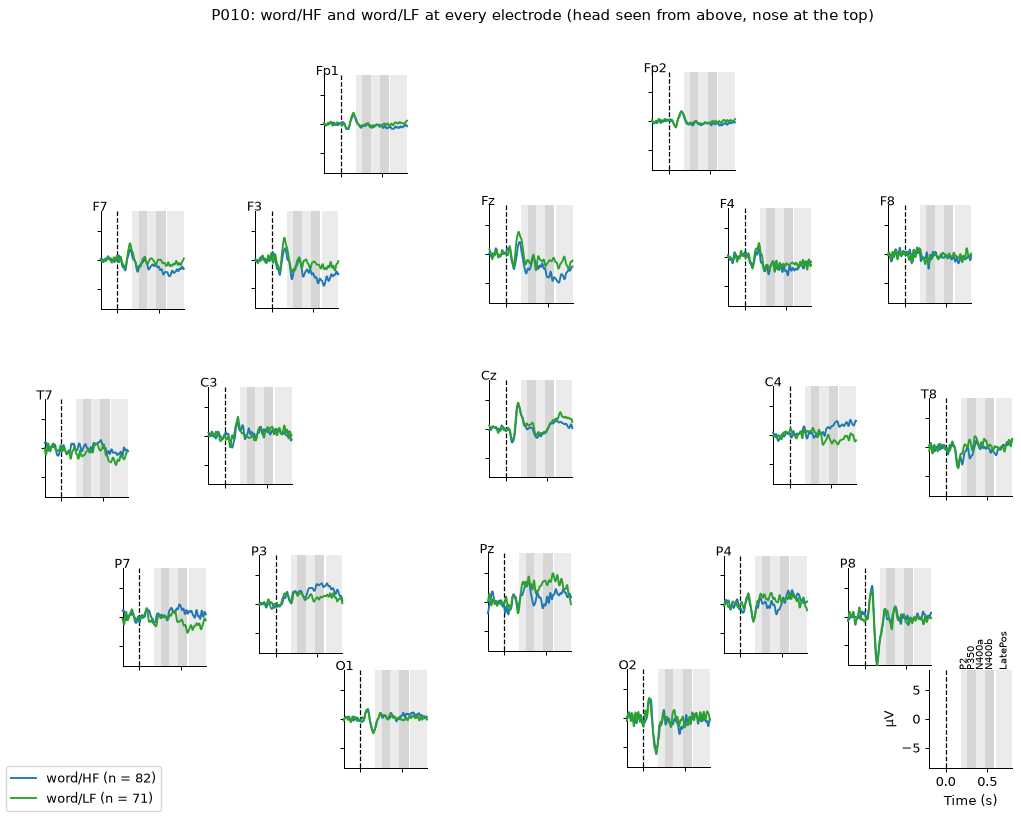

In [64]:
# ---- 11.2 The ERP at every electrode, for each condition -----------------------------------------------------------------------------
def plot_topo(evokeds, title):
    """One small plot per electrode, placed as on the head seen from above (nose at the top), one curve per condition. The window of
    each component (cell 0.3) is shaded, and named on the scale at the bottom right."""
    fig = mne.viz.plot_compare_evokeds(evokeds, picks='eeg', axes='topo', colors=[CONDITIONS[n] for n in PLOTTED], legend=False,
                                       truncate_xaxis=False, truncate_yaxis=False, show=False, title=title)[0]
    fig.set_size_inches(12, 9)
    for ax in fig.axes:
        for i, c in enumerate(COMPONENTS.values()):
            ax.axvspan(*c['window'], color=['0.92', '0.84'][i % 2], lw=0, zorder=0)
    scale = fig.axes[-1]                                     # the last axes: the scale, without data
    for name, c in COMPONENTS.items():
        scale.text(np.mean(c['window']), scale.get_ylim()[1], name, rotation=90, ha='center', va='bottom', fontsize=8)
    fig.legend(*fig.axes[0].get_legend_handles_labels(), loc='lower left')   # one legend for all the small plots
    plt.show()


plot_topo({f'{name} (n = {len(epochs_clean[name])})': epochs_clean[name].average() for name in PLOTTED},
          f'{SUBJECT}: {" and ".join(PLOTTED)} at every electrode (head seen from above, nose at the top)')

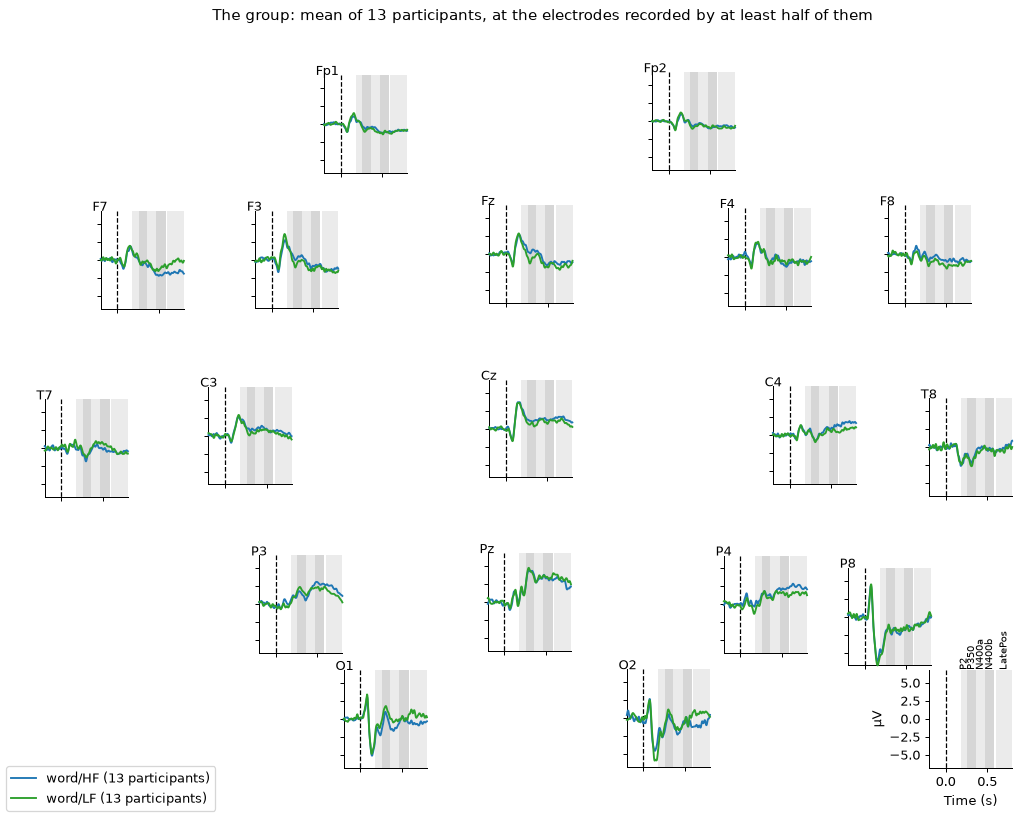

In [65]:
# ---- 11.2 (group) The same figure for the group --------------------------------------------------------------------------------------
if group_ready():
    plot_topo({f'{name} ({len(participants)} participants)': grand_average(group[name]) for name in PLOTTED},
              f'The group: mean of {len(participants)} participants, at the electrodes recorded by at least half of them')

**Look.** Each small plot is one electrode, placed as on the head seen from above (nose at the top). All plots share the scale at the
bottom right, where the five windows are named. In P012, the largest wave is negative, at about 110–140 ms at the back of the head (O1,
O2, P8, over the visual cortex), and the positivity after 300 ms is largest at Cz and Pz. The group has the same shape, smaller and
smoother (P8 about −6.5 µV at 150 ms, Pz about +3.5 µV from 300 to 600 ms): averaging participants keeps what they share and cancels what is
specific to each of them. P7 is missing from the group because no participant recorded it; in P012 it is rebuilt from its neighbours
(step 8), an estimate and not a measurement. In both figures frequent and rare words overlap almost everywhere: they differ
by about 1 µV or less, while the electrodes differ by more than 10 µV.

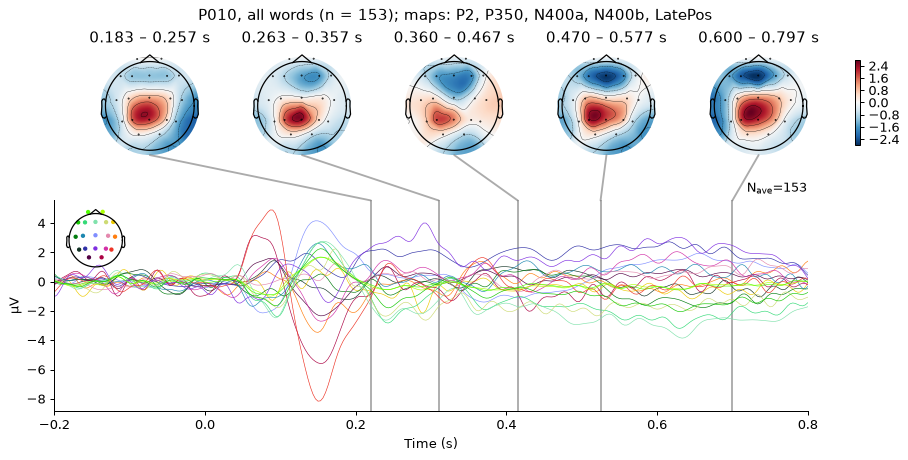

In [66]:
# ---- 11.3 All words: every channel (butterfly plot) and the map of each component ----------------------------------------------------
centres = [np.mean(c['window']) for c in COMPONENTS.values()]                 # the middle of each window (s)
widths = [c['window'][1] - c['window'][0] for c in COMPONENTS.values()]       # each map is the mean over its whole window
evoked_words = epochs_clean['word'].average()
fig = evoked_words.plot_joint(times=centres, topomap_args=dict(average=widths), show=False,
                              title=f'{SUBJECT}, all words (n = {evoked_words.nave}); maps: {", ".join(COMPONENTS)}')
fig.set_size_inches(10, 5)
plt.show()

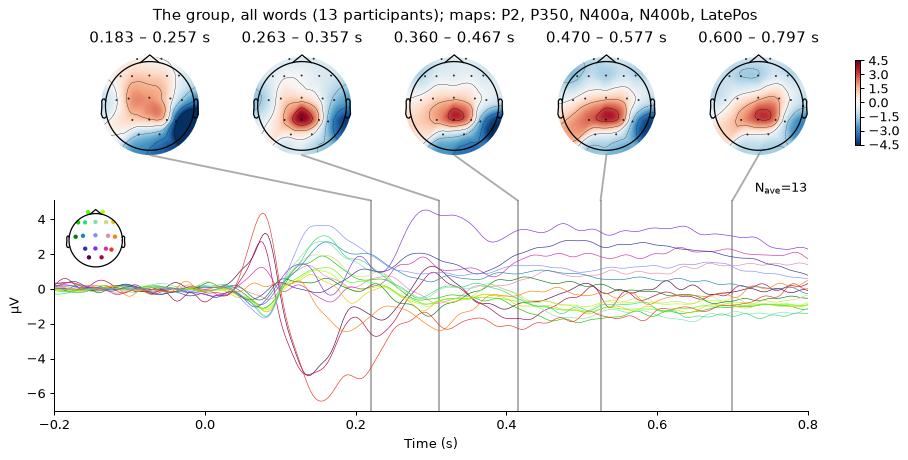

In [67]:
# ---- 11.3 (group) The same figure for the group --------------------------------------------------------------------------------------
if group_ready():
    group_words = grand_average(group['word'])
    fig = group_words.plot_joint(times=centres, topomap_args=dict(average=widths), show=False,
                                 title=f'The group, all words ({len(participants)} participants); maps: {", ".join(COMPONENTS)}')
    fig.set_size_inches(10, 5)
    plt.show()

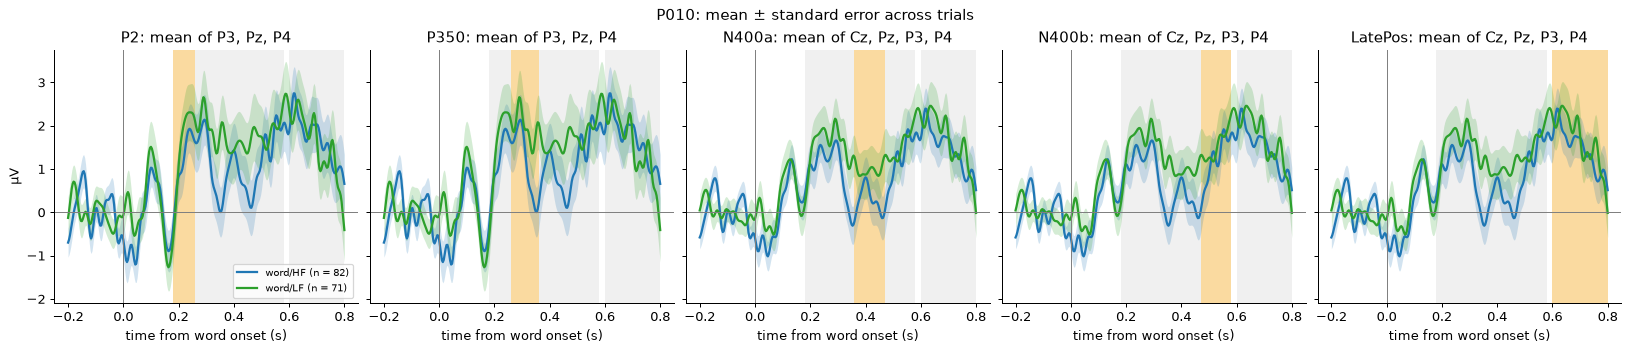

In [68]:
# ---- 11.4 Each component: the conditions at its electrodes ---------------------------------------------------------------------------
def plot_components(curves, title):
    """One panel per component (cell 0.3): the mean of its electrodes for each condition, ± the standard error across the curves
    averaged (the trials of one participant, or the participants of the group). Its window in yellow, the other windows in grey.
    curves[component][condition] is an array (trials or participants x times), in µV."""
    fig, axes = plt.subplots(1, len(COMPONENTS), figsize=(18, 3.8), sharey=True, layout='constrained')
    for ax, (comp, c) in zip(axes, COMPONENTS.items()):
        for other in COMPONENTS.values():
            ax.axvspan(*other['window'], color='0.94', lw=0, zorder=0)
        ax.axvspan(*c['window'], color='#ffd27f', alpha=0.7, lw=0, zorder=0)
        for name in PLOTTED:
            x = curves[comp][name]
            mean, sem = x.mean(axis=0), x.std(axis=0, ddof=1) / np.sqrt(len(x))
            ax.plot(times, mean, color=CONDITIONS[name], lw=1.8, label=f'{name} (n = {len(x)})')
            ax.fill_between(times, mean - sem, mean + sem, color=CONDITIONS[name], alpha=0.2, lw=0)
        ax.axvline(0, color='0.5', lw=0.8)
        ax.axhline(0, color='0.5', lw=0.8)
        ax.set(title=f'{comp}: mean of {", ".join(c["region"])}', xlabel='time from word onset (s)')
    axes[0].set_ylabel('µV')
    axes[0].legend(fontsize=8, loc='lower right')
    fig.suptitle(title)
    plt.show()


curves = {comp: {name: epochs_clean[name].get_data(picks=c['region']).mean(axis=1) * 1e6 for name in [*CONDITIONS, 'word']}
          for comp, c in COMPONENTS.items()}                 # each trial: the mean of the component's electrodes (µV)
plot_components(curves, f'{SUBJECT}: mean ± standard error across trials')

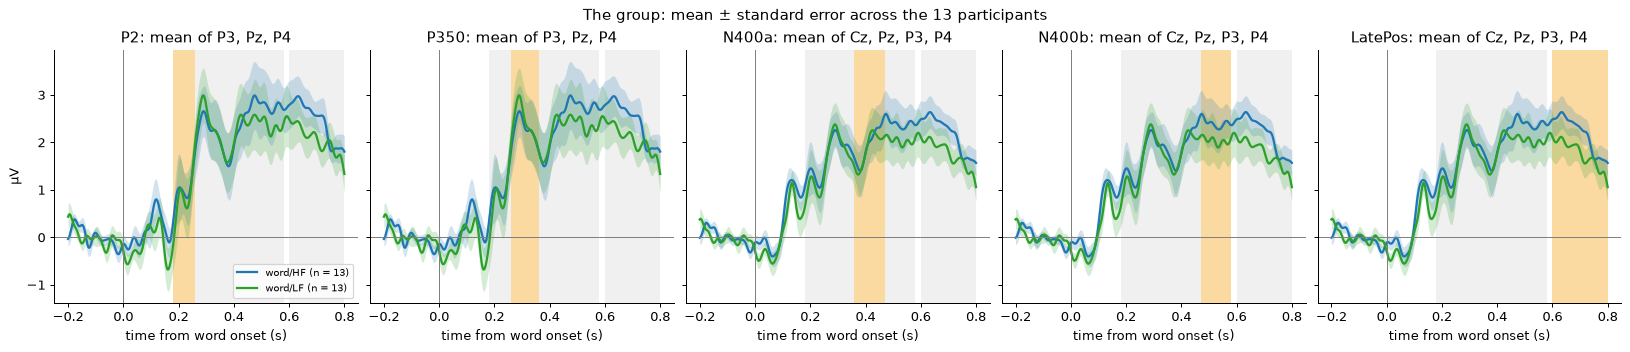

In [69]:
# ---- 11.4 (group) The same figure for the group --------------------------------------------------------------------------------------
if group_ready():
    group_curves = {comp: {name: np.array([np.nanmean(e.get_data(picks=c['region']), axis=0) for e in group[name]]) * 1e6
                           for name in group} for comp, c in COMPONENTS.items()}   # each participant: the electrodes it recorded
    plot_components(group_curves, f'The group: mean ± standard error across the {len(participants)} participants')

In [70]:
# ---- 11.5 The mean amplitude of each condition in the window of each component -------------------------------------------------------
def window_means(curves):
    """The mean of each curve (one per trial or per participant) over the window of its component (µV)."""
    return {comp: {name: x[:, (times >= c['window'][0]) & (times <= c['window'][1])].mean(axis=1) for name, x in curves[comp].items()}
            for comp, c in COMPONENTS.items()}


values = window_means(curves)
amplitude = pd.DataFrame({comp: {name: v[name].mean() for name in CONDITIONS} for comp, v in values.items()})
amplitude.loc['pseudoword − words'] = [v['pseudoword'].mean() - v['word'].mean() for v in values.values()]
amplitude.loc['LF − HF'] = amplitude.loc['word/LF'] - amplitude.loc['word/HF']
amplitude.round(2)

,P2,P350,N400a,N400b,LatePos
word/HF,1.17,1.16,0.27,1.19,1.47
word/LF,1.55,1.98,0.98,1.53,1.65
pseudoword,1.33,1.93,0.55,0.97,0.99
pseudoword − words,-0.01,0.39,-0.05,-0.37,-0.57
LF − HF,0.38,0.82,0.71,0.34,0.18


In [71]:
# ---- 11.5 (group) The same table for the group: mean ± standard error across participants --------------------------------------------
def mean_sem(x):
    """'mean ± standard error' of one value per participant."""
    return f'{x.mean():.2f} ± {x.std(ddof=1) / np.sqrt(len(x)):.2f}'


if group_ready():
    table = {}
    for comp, v in window_means(group_curves).items():
        lexicality, frequency = v['pseudoword'] - v['word'], v['word/LF'] - v['word/HF']   # one difference per participant
        table[comp] = {**{name: mean_sem(v[name]) for name in CONDITIONS},
                       'pseudoword − words': mean_sem(lexicality), 'LF − HF': mean_sem(frequency),
                       'participants with pseudoword < words': f'{(lexicality < 0).sum()} of {len(lexicality)}',
                       'participants with LF < HF': f'{(frequency < 0).sum()} of {len(frequency)}'}
    display(pd.DataFrame(table))

,P2,P350,N400a,N400b,LatePos
word/HF,1.00 ± 0.40,2.27 ± 0.55,1.96 ± 0.47,2.41 ± 0.44,2.17 ± 0.25
word/LF,0.84 ± 0.50,2.41 ± 0.58,1.87 ± 0.47,2.03 ± 0.46,1.75 ± 0.33
pseudoword,1.03 ± 0.35,2.54 ± 0.50,1.50 ± 0.45,1.79 ± 0.34,1.69 ± 0.30
pseudoword − words,0.12 ± 0.14,0.22 ± 0.15,-0.41 ± 0.12,-0.46 ± 0.16,-0.30 ± 0.17
LF − HF,-0.16 ± 0.30,0.15 ± 0.20,-0.09 ± 0.14,-0.37 ± 0.19,-0.43 ± 0.20
participants with pseudoword < words,5 of 13,4 of 13,9 of 13,11 of 13,8 of 13
participants with LF < HF,7 of 13,7 of 13,8 of 13,10 of 13,8 of 13


**Look.** Each panel averages the electrodes of one component (the black dots on the maps of 11.6), with its window in yellow. In both
N400 windows, frequent words are more positive than rare words, in P012 and in the group: rare words are below frequent words in 8 of
the 13 participants between 360 and 470 ms (N400a) and in 10 of 13 between 470 and 580 ms (N400b). The tables add the pseudowords: in
both N400 windows they are the most negative of the three conditions, and below words in 9 of 13 participants (N400a) and 11 of 13
(N400b). The differences are small
(under 1 µV in the group) compared with the noise of single trials, and there is no statistical test here: notebook 09 tests the
effects.

The P350 of Vergara-Martínez et al. (2013), words more positive than pseudowords between 260 and 360 ms, is not in our group: pseudowords
are below words in only 4 of 13 participants (table). The P2 window has no prediction and shows no consistent difference (pseudowords below words
in 5 of 13). Look at the group's P2 panel: at P3, Pz and P4 there is only a small positive bump at about 200 ms (under 1 µV), between a dip
at 160 ms and the large rise into the P350, which begins at the end of the window. The paper described its waves with a mastoid
reference; with our average reference, the same electrodes and window do not catch a clear P2. Moving the window now, to where a
difference appears, would be choosing it from the data. The late positivity is exploratory, and no difference is consistent across
participants there either (8 of 13 for each difference).

The difference between conditions also has a topography. Below: the map of rare minus frequent words in each window, then an
animation of the map of P012's word ERP.

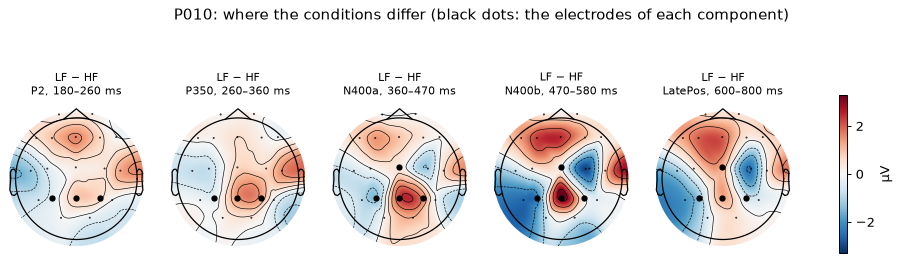

In [72]:
# ---- 11.6 Where do the conditions differ? The map of each difference in each window --------------------------------------------------
DIFFERENCES = {'LF − HF': ('word/LF', 'word/HF')}             # rare minus frequent words
if 'pseudoword' in PLOTTED:                                  # and pseudowords minus words, when they are drawn (cell 0.3)
    DIFFERENCES = {'pseudoword − words': ('pseudoword', 'word'), **DIFFERENCES}


def plot_difference_maps(evokeds, title, seen=None):
    """One row per difference, one column per component: the mean difference over the component's window at each electrode (µV),
    all on the same colour scale. Black dots: the electrodes of the component. evokeds[condition] is a list of ERPs, one per
    participant (NaN where not recorded). Open circles (group): electrodes recorded by too few participants, without a value."""
    info = evokeds['word'][0].info
    seen = np.ones(len(info['ch_names']), bool) if seen is None else seen
    maps = {}
    for difference, (a, b) in DIFFERENCES.items():
        for comp, c in COMPONENTS.items():
            inside = (evokeds[a][0].times >= c['window'][0]) & (evokeds[a][0].times <= c['window'][1])
            each = [(x.data[seen][:, inside] - y.data[seen][:, inside]).mean(axis=1) for x, y in zip(evokeds[a], evokeds[b])]
            maps[difference, comp] = np.nanmean(each, axis=0) * 1e6   # the mean of the participants who recorded each electrode
    limit = max(np.abs(m).max() for m in maps.values())
    info_seen = mne.pick_info(info, np.flatnonzero(seen))
    fig, axes = plt.subplots(len(DIFFERENCES), len(COMPONENTS), figsize=(14, 1.2 + 2.6 * len(DIFFERENCES)))
    for ax, ((difference, comp), values) in zip(axes.flat, maps.items()):
        image, _ = mne.viz.plot_topomap(values, info_seen, axes=ax, show=False, vlim=(-limit, limit), cmap='RdBu_r',
                                        mask=np.isin(info_seen['ch_names'], COMPONENTS[comp]['region']),
                                        mask_params=dict(marker='o', markerfacecolor='k', markersize=4))
        if not seen.all():                                   # electrodes recorded by too few participants: open circles, no value
            mne.viz.plot_topomap(np.zeros(len(seen)), info, axes=ax, show=False, vlim=(-1, 1), cmap=ListedColormap([(0, 0, 0, 0)]),
                                 contours=0, sensors=False, mask=~seen,
                                 mask_params=dict(marker='o', markerfacecolor='none', markeredgecolor='0.35', markersize=6))
        start, end = COMPONENTS[comp]['window']
        ax.set_title(f'{difference}\n{comp}, {start * 1000:.0f}–{end * 1000:.0f} ms', fontsize=9)
    fig.colorbar(image, ax=axes, shrink=0.6, label='µV')
    fig.suptitle(title)
    plt.show()


plot_difference_maps({name: [epochs_clean[name].average()] for name in [*CONDITIONS, 'word']},
                     f'{SUBJECT}: where the conditions differ (black dots: the electrodes of each component)')

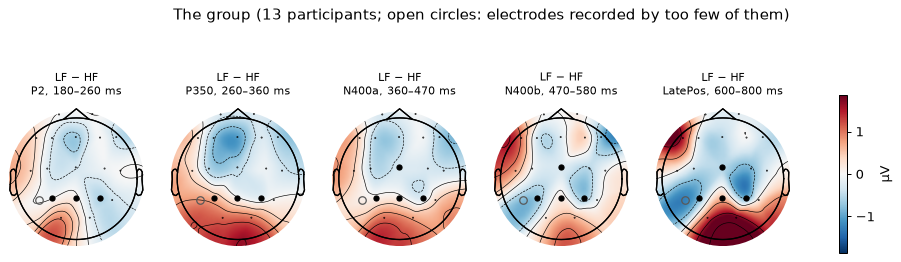

In [73]:
# ---- 11.6 (group) The same maps for the group ----------------------------------------------------------------------------------------
if group_ready():
    plot_difference_maps(group, f'The group ({len(participants)} participants; open circles: electrodes recorded by too few of them)',
                         seen=seen)

In [74]:
# ---- 11.7 Animation: the map of the word ERP over time ------------------------------------------------------------------------------
fig, anim = evoked_words.animate_topomap(times=np.arange(-0.1, 0.801, 0.025), ch_type='eeg', frame_rate=5, blit=False, show=False)
show_animation(fig, anim)

**Look.** The difference maps (11.6) put the five maps of a figure on one colour scale, with the electrodes of each component as black
dots. In the group, rare minus frequent words is weak in N400a and negative over the centre and back of the head in N400b (P3 and P4
about −0.7 µV), with positive values at some edges (T7, F7, O2): with the average reference the electrodes sum to zero. The maps of P012 are noisier: the differences of one participant, 1–2 µV,
change from one window to the next. In the animation of P012's word ERP (11.7), the map is flat before the word. From about 100 ms, a
strong negativity appears at the back of the head (occipital electrodes, over the visual cortex) with a positivity at the centre; from
about 300 ms the positivity at the centre of the head grows and lasts through the N400 windows and the late positivity.

#### Check your understanding

- **How many trials would you need to halve the noise of an average of 50 trials?**
  <details><summary>Answer</summary>

  200 trials: the noise falls like 1/√N, so halving it takes 4 times more trials.

  </details>
- **Why does the N400 look like a positive wave here?**
  <details><summary>Answer</summary>

  The N400 is a negative-going effect: in its windows, pseudowords and rare words are more negative than frequent words. The voltage itself does not have to go below 0 µV: other components overlap with it (the P350 before, the late positivity after), and the zero depends on the reference. With the average reference the electrodes sum to zero, so the negative waves at the edges of the head come with positive values at the centre.

  </details>
- **P012 has a curve at P7, the group does not. Why?**
  <details><summary>Answer</summary>

  P7 was flat in every participant. In P012 it is rebuilt from its neighbours (step 8): an estimate, not a measurement. The group uses only the electrodes each participant recorded, so no one contributes to P7.

  </details>
- **The P2 window shows no difference between words and pseudowords. Does this show that the P2 does not depend on the kind of word?**
  <details><summary>Answer</summary>

  No. A difference that is not found is not evidence that there is none: with 13 participants and no test, a small effect can be missed, and here the window does not even catch a clear P2 at these electrodes (11.4, group). Vergara-Martínez et al. (2013) are careful in the same way: they report no significant difference in this window, not that the conditions are equal.

  </details>

## 12. The rest recordings: spectra

**What.** The rest recordings have no events, so there are no ERPs. We study their rhythms instead: cut them into 2-s pieces, drop the
pieces with very large amplitudes, compute the spectrum of each piece (Welch method), and average. We compare the rest before the task,
the task itself and the rest at the end, and look at the **alpha rhythm** (8–12 Hz), largest at the back of the head.

**Why.** Rest recordings give a baseline of brain rhythms. Alpha is known to be larger when we do not attend to the outside world, and
to change with tiredness. They went through the same preprocessing (steps 2 to 8) as the task.

**How.** `mne.make_fixed_length_epochs`, then `epochs.compute_psd(method='welch')`, which returns a spectrum for each piece;
`.average()` averages them.

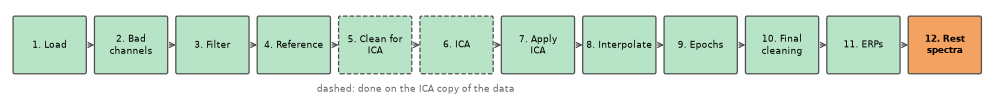

In [75]:
pipeline_map(12)

rest_pre   145 of 150 pieces of 2 s kept


task       446 of 527 pieces of 2 s kept


rest_post  136 of 150 pieces of 2 s kept


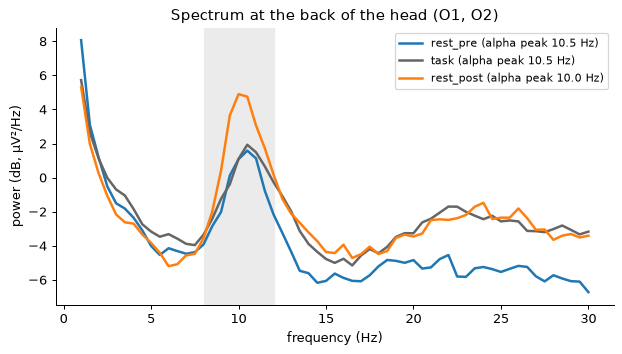

In [76]:
# ---- 12.1 The spectrum of each recording -------------------------------------------------------------------------------------------
spectra = {}
for name in final:                                           # the rests this participant has, and the task
    rest_pieces = mne.make_fixed_length_epochs(final[name], duration=SEGMENT_S, preload=True)
    n_pieces = len(rest_pieces)
    rest_pieces.drop_bad(reject=dict(eeg=REJECT_UV * 1e-6))
    spectra[name] = rest_pieces.compute_psd(method='welch', fmin=1, fmax=30, n_fft=int(SEGMENT_S * sfreq)).average()
    print(f'{name:10s} {len(rest_pieces)} of {n_pieces} pieces of {SEGMENT_S:g} s kept')

fig, ax = plt.subplots(figsize=(8, 4))
for name, spectrum in spectra.items():
    color = {'rest_pre': 'tab:blue', 'task': '0.4', 'rest_post': 'tab:orange'}[name]
    power = spectrum.get_data(picks=POSTERIOR).mean(axis=0) * 1e12            # µV²/Hz, mean of the posterior electrodes
    in_alpha = (spectrum.freqs >= ALPHA_BAND[0]) & (spectrum.freqs <= ALPHA_BAND[1])
    peak = spectrum.freqs[in_alpha][np.argmax(power[in_alpha])]
    ax.plot(spectrum.freqs, 10 * np.log10(power), color=color, lw=2, label=f'{name} (alpha peak {peak:.1f} Hz)')
ax.axvspan(*ALPHA_BAND, color='0.92', zorder=0)
ax.set(xlabel='frequency (Hz)', ylabel='power (dB, µV²/Hz)', title=f'Spectrum at the back of the head ({", ".join(POSTERIOR)})')
ax.legend(fontsize=9)
plt.show()

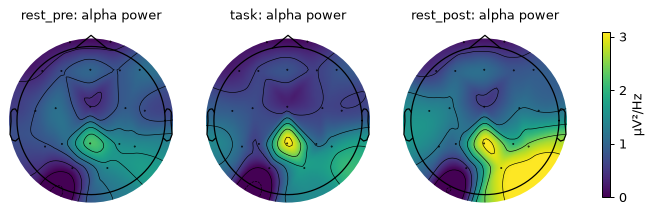

In [77]:
# ---- 12.2 Where is the alpha rhythm? -------------------------------------------------------------------------------------------------
alpha_power = {name: spectrum.get_data(fmin=ALPHA_BAND[0], fmax=ALPHA_BAND[1]).mean(axis=1) * 1e12 for name, spectrum in spectra.items()}
top = max(p.max() for p in alpha_power.values())
fig, axes = plt.subplots(1, len(alpha_power), figsize=(10, 3.4))
for ax, (name, power) in zip(axes, alpha_power.items()):
    im, _ = mne.viz.plot_topomap(power, spectra[name].info, axes=ax, show=False, vlim=(0, top), cmap='viridis')
    ax.set_title(f'{name}: alpha power', fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.7, label='µV²/Hz')
plt.show()

**Look.** All three spectra fall with frequency and have a bump in the alpha band, largest at the back of the head. In P012, alpha is
largest in the rest before the task, smallest during the task, and in between in the rest at the end of the session. Reading words on a
screen needs visual attention, which lowers posterior alpha. The rest at the end comes after about an hour of tasks, including the
walking blocks; many things changed in between (tiredness, the contact of the electrodes), so one participant cannot tell us why. Remember
also that P012's last rest lasted only about 2.3 minutes, so its spectrum is less precise.

#### Check your understanding

- **Why 2-s pieces for the spectrum?**
  <details><summary>Answer</summary>

  With 2 s of data, the spectrum has a resolution of 1/2 s = 0.5 Hz, enough to see the alpha peak; averaging many pieces makes the estimate stable.

  </details>
- **Could we compare the alpha power of this participant with another one directly?**
  <details><summary>Answer</summary>

  With care: the absolute power depends on the contact of the electrodes and the thickness of the skull. Comparisons within a participant (rest before against rest after) are more reliable.

  </details>

## 13. Save the results, and summary

In [78]:
# ---- 13.1 Save the clean epochs, the clean rest recordings and a summary ------------------------------------------------------------
RESULTS_DIR = DATA_DIR / 'mes_resultats'                     # "my results": the folder notebook 01 also writes to
RESULTS_DIR.mkdir(exist_ok=True)
epochs_clean.save(RESULTS_DIR / f'sub-{SUBJECT}_teaching_seated-epo.fif', overwrite=True)
for name in [n for n in ('rest_pre', 'rest_post') if n in final]:
    final[name].save(RESULTS_DIR / f'sub-{SUBJECT}_teaching_{name}_eeg.fif', overwrite=True)
summary = {
    'participant': SUBJECT,
    'bad channels (rebuilt)': BAD_CHANNELS,
    'pieces kept to train ICA': f'{len(pieces_clean)} of {len(pieces)}',
    'ICA components': int(ica.n_components_),
    'components removed': [f'ICA{i:03d}' for i in ica.exclude],
    'epochs kept (HF, LF, pseudoword)': [len(epochs_clean[name]) for name in CONDITIONS],
    'N400a, mean amplitude (µV)': {name: round(float(amplitude.loc[name, 'N400a']), 2) for name in CONDITIONS},
    'N400b, mean amplitude (µV)': {name: round(float(amplitude.loc[name, 'N400b']), 2) for name in CONDITIONS},
}
(RESULTS_DIR / f'sub-{SUBJECT}_teaching_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved in', RESULTS_DIR)
pd.Series(summary, name=SUBJECT).to_frame()

Saved in tasks\brainwalk\mes_resultats


,P010
participant,P010
bad channels (rebuilt),[P7]
pieces kept to train ICA,751 of 822
ICA components,17
components removed,"[ICA000, ICA001, ICA004, ICA016]"
"epochs kept (HF, LF, pseudoword)","[82, 71, 159]"
"N400a, mean amplitude (µV)","{'word/HF': 0.27, 'word/LF': 0.98, 'pseudoword..."
"N400b, mean amplitude (µV)","{'word/HF': 1.19, 'word/LF': 1.53, 'pseudoword..."


### The pipeline in one table

| Step | What it did here | Main risk if done badly |
|---|---|---|
| 1. Load | 6 recordings, rests cut to the rest period, 4 blocks joined | wrong events or wrong channel types |
| 2. Bad channels | P7 (flat on the recorded signal) marked as bad; noisy channels looked for after the median reference | a bad channel spreads to all others at step 4 |
| 3. Filter | notch 60/120 Hz; 0.1–30 Hz (analysis) and 1–100 Hz (ICA copy) | a high-pass that is too high distorts slow ERPs |
| 4. Reference | average of the good channels; Pz gets a signal back | bad channels in the average |
| 5. Clean for ICA | 2-s pieces with large artifacts left out of ICA training | ICA spoilt by rare huge artifacts |
| 6. ICA | 16 components, eye and muscle components picked by ICLabel | removing brain components |
| 7. Apply ICA | blinks and muscle removed from the 0.1–30 Hz data | |
| 8. Interpolate | P7 rebuilt from its neighbours | treating a rebuilt channel as recorded |
| 9. Epochs | −0.2 to 0.8 s around each word; baseline −0.2 to 0 s, corrected by regression | epochs crossing a junction or a gap |
| 10. Final cleaning | AutoReject; onsets confirmed by their tone; correct trials with RT ≥ 250 ms | too few trials left |
| 11. ERPs | P2, P350, N400a, N400b and the late positivity by condition, for P012 and for the group | conclusions from one participant |
| 12. Rest spectra | alpha before, during and after the task | |

### What this simple pipeline does not do

Compared with the full Brain Walk pipeline (notebook `01_preprocessing_lexicaldecision.ipynb`), this pipeline does **not** correct the
head movements measured by the accelerometer of the headset, does not use wavelets to correct the eyes, and does not repair channels
locally in each epoch. Seated data do not need these steps much; walking data do, because each step shakes the electrodes and the cables.

### Try it yourself

1. In cell 0.3, set `ANALYSIS_BAND = (1.0, 30.0)` and rerun from step 3. What happens to the late positivity in cell 11.4? (Compare with animation 3.2.)
2. In cell 6.7, add the line `ica.exclude = []` at the end and rerun steps 7 to 11. How do the blink figures and the ERPs change?
3. Set `MUSCLE_THRESHOLD = 0.9`. How many components are removed now? Does the ERP change?
4. Set `KEEP_CORRECT_ONLY = False`. How many trials do you gain, and does the N400 change?
5. Run the whole notebook with `SUBJECT = 'P010'`, a participant with cleaner data and longer rests. Which steps change the most?

### References

- Ablin, P., Cardoso, J.-F., & Gramfort, A. (2018). Faster independent component analysis by preconditioning with Hessian approximations.
  *IEEE Transactions on Signal Processing, 66*(15), 4040–4049.
- Alday, P. M. (2019). How much baseline correction do we need in ERP research? Extended GLM model can replace baseline correction while
  lifting its limits. *Psychophysiology, 56*(12), e13451.
- Bigdely-Shamlo, N., Mullen, T., Kothe, C., Su, K.-M., & Robbins, K. A. (2015). The PREP pipeline: standardized preprocessing for large-scale EEG
  analysis. *Frontiers in Neuroinformatics, 9*, 16.
- di Fronso, S., Fiedler, P., Tamburro, G., Haueisen, J., Bertollo, M., & Comani, S. (2019). Dry EEG in sports sciences: A fast and reliable tool
  to assess individual alpha peak frequency changes induced by physical effort. *Frontiers in Neuroscience, 13*, 982.
- Fiedler, P., Fonseca, C., Supriyanto, E., Zanow, F., & Haueisen, J. (2022). A high-density 256-channel cap for dry electroencephalography. *Human
  Brain Mapping, 43*(4), 1295–1308.
- Fló, A., Gennari, G., Benjamin, L., & Dehaene-Lambertz, G. (2022). Automated pipeline for infants continuous EEG (APICE): A flexible pipeline for
  developmental cognitive studies. *Developmental Cognitive Neuroscience, 54*, 101077.
- Gonsisko, C. B., Ferris, D. P., & Downey, R. J. (2023). iCanClean improves independent component analysis of mobile brain imaging with EEG.
  *Sensors, 23*(2), 928.
- Gramfort, A., et al. (2013). MEG and EEG data analysis with MNE-Python. *Frontiers in Neuroscience, 7*, 267.
- Heijs, J. J. A., Havelaar, R. J., Fiedler, P., van Wezel, R. J. A., & Heida, T. (2021). Validation of soft multipin dry EEG electrodes. *Sensors,
  21*(20), 6827.
- Hyvärinen, A., & Oja, E. (2000). Independent component analysis: algorithms and applications. *Neural Networks, 13*(4–5), 411–430.
- Jas, M., Engemann, D. A., Bekhti, Y., Raimondo, F., & Gramfort, A. (2017). Autoreject: Automated artifact rejection for MEG and EEG data.
  *NeuroImage, 159*, 417–429.
- Kam, J. W. Y., Griffin, S., Shen, A., Patel, S., Hinrichs, H., Heinze, H.-J., Deouell, L. Y., & Knight, R. T. (2019). Systematic comparison between a
  wireless EEG system with dry electrodes and a wired EEG system with wet electrodes. *NeuroImage, 184*, 119–129.
- Kim, H., Luo, J., Chu, S., Cannard, C., Hoffmann, S., & Miyakoshi, M. (2023). ICA's bug: How ghost ICs emerge from effective rank deficiency caused
  by EEG electrode interpolation and incorrect re-referencing. *Frontiers in Signal Processing, 3*, 1064138.
- Kline, J. E., Huang, H. J., Snyder, K. L., & Ferris, D. P. (2015). Isolating gait-related movement artifacts in electroencephalography during human
  walking. *Journal of Neural Engineering, 12*(4), 046022.
- Klug, M., & Gramann, K. (2021). Identifying key factors for improving ICA-based decomposition of EEG data in mobile and stationary
  experiments. *European Journal of Neuroscience, 54*(12), 8406–8420.
- Klug, M., Jeung, S., Wunderlich, A., Gehrke, L., Protzak, J., Djebbara, Z., Argubi-Wollesen, A., Wollesen, B., & Gramann, K. (2022). The BeMoBIL
  pipeline for automated analyses of multimodal mobile brain and body imaging data. *bioRxiv*. https://doi.org/10.1101/2022.09.29.510051
- Kumaravel, V. P., Buiatti, M., Parise, E., & Farella, E. (2022a). Adaptable and robust EEG bad channel detection using local outlier factor (LOF).
  *Sensors, 22*(19), 7314.
- Kumaravel, V. P., Farella, E., Parise, E., & Buiatti, M. (2022b). NEAR: An artifact removal pipeline for human newborn EEG data. *Developmental
  Cognitive Neuroscience, 54*, 101068.
- Kutas, M., & Federmeier, K. D. (2011). Thirty years and counting: finding meaning in the N400 component of the event-related brain
  potential (ERP). *Annual Review of Psychology, 62*, 621–647.
- Leys, C., Ley, C., Klein, O., Bernard, P., & Licata, L. (2013). Detecting outliers: Do not use standard deviation around the mean, use absolute
  deviation around the median. *Journal of Experimental Social Psychology, 49*(4), 764–766.
- Li, A., Feitelberg, J., Saini, A. P., Höchenberger, R., & Scheltienne, M. (2022). MNE-ICALabel: Automatically annotating ICA components
  with ICLabel in Python. *Journal of Open Source Software, 7*(76), 4484.
- Luck, S. J. (2014). *An introduction to the event-related potential technique* (2nd ed.). MIT Press.
- Makeig, S., Bell, A. J., Jung, T.-P., & Sejnowski, T. J. (1996). Independent component analysis of electroencephalographic data.
  *Advances in Neural Information Processing Systems, 8*, 145–151.
- Ng, C. R., Fiedler, P., Kuhlmann, L., Liley, D., Vasconcelos, B., Fonseca, C., Tamburro, G., Comani, S., Lui, T. K.-Y., Tse, C.-Y., Warsito, I. F.,
  Supriyanto, E., & Haueisen, J. (2022). Multi-center evaluation of gel-based and dry multipin EEG caps. *Sensors, 22*(20), 8079.
- Oliveira, A. S., Schlink, B. R., Hairston, W. D., König, P., & Ferris, D. P. (2016). Proposing metrics for benchmarking novel EEG technologies
  towards real-world measurements. *Frontiers in Human Neuroscience, 10*, 188.
- Oliveira, A. S., Schlink, B. R., Hairston, W. D., König, P., & Ferris, D. P. (2017). A channel rejection method for attenuating motion-related
  artifacts in EEG recordings during walking. *Frontiers in Neuroscience, 11*, 225.
- Pernet, C. R., Garrido, M., Gramfort, A., Maurits, N., Michel, C., Pang, E., Salmelin, R., Schoffelen, J. M., Valdes-Sosa, P. A., & Puce, A. (2018).
  Best practices in data analysis and sharing in neuroimaging using MEEG. *OSF Preprints*. https://doi.org/10.31219/osf.io/a8dhx
- Pernet, C. R., et al. (2019). EEG-BIDS, an extension to the brain imaging data structure for electroencephalography. *Scientific Data,
  6*, 103.
- Perrin, F., Pernier, J., Bertrand, O., & Echallier, J. F. (1989). Spherical splines for scalp potential and current density mapping.
  *Electroencephalography and Clinical Neurophysiology, 72*(2), 184–187.
- Pion-Tonachini, L., Kreutz-Delgado, K., & Makeig, S. (2019). ICLabel: An automated electroencephalographic independent component
  classifier, dataset, and website. *NeuroImage, 198*, 181–197.
- PyPREP developers. (n.d.). *PyPREP documentation*. https://pyprep.readthedocs.io
- Tanner, D., Morgan-Short, K., & Luck, S. J. (2015). How inappropriate high-pass filters can produce artifactual effects and incorrect
  conclusions in ERP studies of language and cognition. *Psychophysiology, 52*(8), 997–1009.
- Vergara-Martínez, M., Perea, M., Gómez, P., & Swaab, T. Y. (2013). ERP correlates of letter identity and letter position are modulated
  by lexical frequency. *Brain and Language, 125*(1), 11–27.
- Wearable Sensing. (2023). *DSI-24 user manual* (V1.2023). https://wearablesensing.com/dsi-24/
- Widmann, A., Schröger, E., & Maess, B. (2015). Digital filter design for electrophysiological data – a practical approach. *Journal of
  Neuroscience Methods, 250*, 34–46.
- Winkler, I., Debener, S., Müller, K.-R., & Tangermann, M. (2015). On the influence of high-pass filtering on ICA-based artifact reduction
  in EEG-ERP. *37th Annual International Conference of the IEEE EMBS*, 4101–4105.
